In [27]:

# IMPORTS, SETUP AND DATA LOADING

# Load the final outputs from Notebook 04.
# No preprocessing or model training yet.

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("CELL 1: MODEL DEVELOPMENT SETUP")

# 1. Locate the project root.

current_dir = Path.cwd()

if (current_dir / "data" / "processed").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "processed").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open this notebook "
        "inside your NHS Dorset project."
    )

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_REPORT_DIR = PROJECT_ROOT / "reports" / "model_development"

MODEL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT)

# 2. Define handover file paths.

dataset_path = (
    DATA_DIR / "outpatient_dna_feature_engineered.csv"
)

features_path = (
    DATA_DIR / "outpatient_dna_selected_features.json"
)

manifest_path = (
    DATA_DIR / "outpatient_dna_split_manifest.csv"
)

for path in [dataset_path, features_path, manifest_path]:
    assert path.exists(), f"Missing handover file: {path}"

print("\nAll three input files found.")

# 3. Load feature-engineered dataset.

df_model = pd.read_csv(
    dataset_path,
    low_memory=False
)

with open(features_path, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

selected_features = feature_config["features"]

df_manifest = pd.read_csv(
    manifest_path,
    low_memory=False
)

print("\nDataset shape:", df_model.shape)
print("Manifest shape:", df_manifest.shape)
print("Selected predictors:", len(selected_features))

# 4. Validate the handover.

assert df_model.shape == (36264, 53)
assert len(df_manifest) == 36264
assert df_model["appointment_id"].is_unique
assert df_manifest["appointment_id"].is_unique
assert len(selected_features) == 15
assert len(set(selected_features)) == 15
assert all(col in df_model.columns for col in selected_features)

assert int(df_model["dna_target"].sum()) == 3306

# 5. Validate split assignments.

expected_counts = {
    "train": 24612,
    "validation": 4773,
    "test": 5488
}

for split_name, expected in expected_counts.items():
    actual = int(
        (
            (df_model["data_split"] == split_name)
            & (df_model["eligible_for_split"] == True)
        ).sum()
    )

    assert actual == expected, (
        f"{split_name}: expected {expected}, found {actual}"
    )

    print(f"{split_name}: {actual:,} usable appointments")

# 6. Verify the saved manifest agrees with the dataset.

manifest_check = df_model[
    ["appointment_id", "data_split", "eligible_for_split"]
].merge(
    df_manifest[
        ["appointment_id", "data_split", "eligible_for_split"]
    ],
    on="appointment_id",
    how="outer",
    suffixes=("_data", "_manifest"),
    validate="one_to_one",
    indicator=True
)

assert (manifest_check["_merge"] == "both").all()

assert (
    manifest_check["data_split_data"]
    == manifest_check["data_split_manifest"]
).all()

assert (
    manifest_check["eligible_for_split_data"]
    == manifest_check["eligible_for_split_manifest"]
).all()

print("\nSplit manifest consistency: PASS")

# 7. Display selected predictors.

print("\nSelected candidate predictors:")

for index, feature in enumerate(selected_features, start=1):
    print(f"{index:02d}. {feature}")

print("\nCELL 1 COMPLETED SUCCESSFULLY")
print("Ready for Cell 2: Reconstruct and validate model datasets.")

CELL 1: MODEL DEVELOPMENT SETUP
Project root: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction

All three input files found.

Dataset shape: (36264, 53)
Manifest shape: (36264, 8)
Selected predictors: 15
train: 24,612 usable appointments
validation: 4,773 usable appointments
test: 5,488 usable appointments

Split manifest consistency: PASS

Selected candidate predictors:
01. age
02. age_missing_flag
03. distance_km
04. distance_missing_flag
05. long_term_conditions
06. interpreter_required
07. specialty
08. appointment_type
09. consultation_mode
10. referral_source
11. booking_lead_days_exact
12. is_short_notice
13. appointment_day_of_week
14. appointment_month
15. appointment_hour

CELL 1 COMPLETED SUCCESSFULLY
Ready for Cell 2: Reconstruct and validate model datasets.


In [28]:

# RECONSTRUCT AND VALIDATE MODEL DATASETS
#
# Objectives:
# 1. Reconstruct chronological datasets.
# 2. Separate predictors and target.
# 3. Verify population and outcome counts.
# 4. Check appointment overlap and chronology.
# 5. Audit missing values and data types.
# 6. Preserve fairness metadata.
# 7. Save validation reports.
#
# No imputation, scaling, encoding or training.

print("CELL 2: RECONSTRUCT AND VALIDATE MODEL DATASETS")


# 1. Confirm Cell 1 has run.

print("\n1. VERIFY INPUTS")

required_objects = [
    "df_model",
    "df_manifest",
    "selected_features",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cell 1 first. Missing: {missing_objects}"
)

assert len(df_model) == 36264
assert len(selected_features) == 15

df_work = df_model.copy(deep=True)

print("Input dataset:", df_work.shape)


# 2. Validate and parse timestamps.

print("\n2. VALIDATE TIMESTAMPS")

timestamp_columns = [
    "booked_datetime",
    "prediction_cutoff_datetime",
    "appointment_datetime"
]

for column in timestamp_columns:

    assert column in df_work.columns

    df_work[column] = pd.to_datetime(
        df_work[column],
        errors="coerce"
    )

    assert df_work[column].notna().all(), (
        f"Invalid timestamps in {column}"
    )

assert (
    df_work["booked_datetime"]
    <= df_work["prediction_cutoff_datetime"]
).all()

assert (
    df_work["prediction_cutoff_datetime"]
    < df_work["appointment_datetime"]
).all()

print("Timestamp validation: PASS")


# 3. Validate the split eligibility column.
# CSV reloads can sometimes change boolean types.

print("\n3. VERIFY SPLIT ELIGIBILITY")

eligibility = df_work["eligible_for_split"]

if pd.api.types.is_bool_dtype(eligibility):

    df_work["eligible_for_split"] = eligibility

else:

    normalised = (
        eligibility.astype("string")
        .str.strip()
        .str.lower()
    )

    assert normalised.isin(
        ["true", "false"]
    ).all(), (
        "Unexpected values in eligible_for_split."
    )

    df_work["eligible_for_split"] = (
        normalised.map({
            "true": True,
            "false": False
        }).astype(bool)
    )

assert df_work["eligible_for_split"].notna().all()

print("Eligibility values validated.")


# 4. Reconstruct the three datasets.


print("\n4. RECONSTRUCT DATASETS")

split_names = [
    "train",
    "validation",
    "test"
]

split_frames = {}

for name in split_names:

    part = df_work.loc[
        (df_work["data_split"] == name)
        &
        (df_work["eligible_for_split"])
    ].copy()

    part = part.sort_values(
        ["appointment_datetime", "appointment_id"]
    ).reset_index(drop=True)

    split_frames[name] = part

df_train = split_frames["train"]
df_val = split_frames["validation"]
df_test = split_frames["test"]

expected_counts = {
    "train": 24612,
    "validation": 4773,
    "test": 5488
}

for name, part in split_frames.items():

    assert len(part) == expected_counts[name]

    print(f"{name}: {len(part):,} appointments")


# 5. Validate DNA outcome distribution.

print("\n5. VALIDATE OUTCOME DISTRIBUTION")

expected_dna = {
    "train": 2230,
    "validation": 435,
    "test": 524
}

outcome_rows = []

for name, part in split_frames.items():

    assert part["dna_target"].notna().all()

    assert set(
        part["dna_target"].unique()
    ) == {0, 1}

    dna_cases = int(part["dna_target"].sum())

    assert dna_cases == expected_dna[name]

    outcome_rows.append({
        "split": name,
        "appointments": len(part),
        "attended": len(part) - dna_cases,
        "dna_cases": dna_cases,
        "dna_rate_percent": round(
            dna_cases / len(part) * 100,
            2
        )
    })

model_split_summary = pd.DataFrame(
    outcome_rows
)

display(model_split_summary)


# 6. Verify no appointment overlaps between splits.

print("\n6. CHECK APPOINTMENT OVERLAP")

train_ids = set(df_train["appointment_id"])
val_ids = set(df_val["appointment_id"])
test_ids = set(df_test["appointment_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert df_train["appointment_id"].is_unique
assert df_val["appointment_id"].is_unique
assert df_test["appointment_id"].is_unique

print("Appointment ID overlap: NONE")


# 7. Verify chronological and maturity safeguards.

print("\n7. VALIDATE CHRONOLOGICAL ORDER")

assert (
    df_train["appointment_datetime"].max()
    < df_val["appointment_datetime"].min()
)

assert (
    df_val["appointment_datetime"].max()
    < df_test["appointment_datetime"].min()
)

first_validation_prediction = (
    df_val["prediction_cutoff_datetime"].min()
)

first_test_prediction = (
    df_test["prediction_cutoff_datetime"].min()
)

assert (
    df_train["appointment_datetime"].max()
    < first_validation_prediction
)

assert (
    df_val["appointment_datetime"].max()
    < first_test_prediction
)

print("Chronological appointment order: PASS")
print("Outcome maturity safeguards: PASS")


# 8. Separate predictors and targets.


print("\n8. CREATE PREDICTOR AND TARGET MATRICES")

X_train = df_train[
    selected_features
].copy()

X_val = df_val[
    selected_features
].copy()

X_test = df_test[
    selected_features
].copy()

y_train = df_train[
    "dna_target"
].astype(int).copy()

y_val = df_val[
    "dna_target"
].astype(int).copy()

y_test = df_test[
    "dna_target"
].astype(int).copy()

assert list(X_train.columns) == selected_features
assert list(X_val.columns) == selected_features
assert list(X_test.columns) == selected_features

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


# 9. Verify restricted features are excluded.

print("\n9. VERIFY LEAKAGE SAFEGUARDS")

forbidden_features = {
    "dna_target",
    "attendance_status",
    "clinic_checkin_time",
    "appointment_id",
    "patient_id",
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime",
    "previous_dnas_12m",
    "rescheduled_count",
    "sms_reminder_sent",
    "sex",
    "ethnic_group",
    "imd_decile",
    "data_split",
    "eligible_for_split",
    "exclusion_reason"
}

for name, matrix in [
    ("train", X_train),
    ("validation", X_val),
    ("test", X_test)
]:

    assert not (
        set(matrix.columns) & forbidden_features
    ), f"Leakage field detected in {name}"

print("Restricted predictors excluded: PASS")


# 10. Review missing values in each split.


print("\n10. REVIEW MISSING VALUES")

missing_rows = []

for name, matrix in [
    ("train", X_train),
    ("validation", X_val),
    ("test", X_test)
]:

    for feature in selected_features:

        missing_rows.append({
            "split": name,
            "feature": feature,
            "missing_count": int(
                matrix[feature].isna().sum()
            ),
            "missing_percent": round(
                matrix[feature].isna().mean() * 100,
                2
            )
        })

model_missingness_audit = pd.DataFrame(
    missing_rows
)

display(
    model_missingness_audit.loc[
        model_missingness_audit[
            "missing_count"
        ] > 0
    ]
)

print(
    "Missing values preserved for "
    "training-only preprocessing."
)


# 11. Review feature data types.

print("\n11. REVIEW FEATURE DATA TYPES")

model_dtype_audit = pd.DataFrame({
    "feature": selected_features,
    "train_dtype": [
        str(X_train[col].dtype)
        for col in selected_features
    ],
    "validation_dtype": [
        str(X_val[col].dtype)
        for col in selected_features
    ],
    "test_dtype": [
        str(X_test[col].dtype)
        for col in selected_features
    ]
})

display(model_dtype_audit)


# 12. Preserve fairness metadata separately.

print("\n12. PRESERVE FAIRNESS INFORMATION")

fairness_columns = [
    "appointment_id",
    "patient_id",
    "dna_target",
    "age",
    "sex",
    "ethnic_group",
    "imd_decile"
]

assert all(
    col in df_work.columns
    for col in fairness_columns
)

fairness_train = df_train[
    fairness_columns
].copy()

fairness_val = df_val[
    fairness_columns
].copy()

fairness_test = df_test[
    fairness_columns
].copy()

assert len(fairness_train) == len(X_train)
assert len(fairness_val) == len(X_val)
assert len(fairness_test) == len(X_test)

print("Fairness metadata preserved: PASS")


# 13. Audit patient overlap.
# Repeated patients across periods are documented
# rather than automatically removed.

print("\n13. PATIENT OVERLAP AUDIT")

patient_sets = {
    "train": set(df_train["patient_id"].dropna()),
    "validation": set(df_val["patient_id"].dropna()),
    "test": set(df_test["patient_id"].dropna())
}

model_patient_overlap = pd.DataFrame([
    {
        "comparison": "Train vs validation",
        "shared_patients": len(
            patient_sets["train"]
            & patient_sets["validation"]
        )
    },
    {
        "comparison": "Train vs test",
        "shared_patients": len(
            patient_sets["train"]
            & patient_sets["test"]
        )
    },
    {
        "comparison": "Validation vs test",
        "shared_patients": len(
            patient_sets["validation"]
            & patient_sets["test"]
        )
    }
])

display(model_patient_overlap)


# 14. Save validation reports.

print("\n14. SAVE CELL 2 REPORTS")

cell02_reports = {
    "cell02_model_split_summary.csv":
        model_split_summary,

    "cell02_model_missingness_audit.csv":
        model_missingness_audit,

    "cell02_model_dtype_audit.csv":
        model_dtype_audit,

    "cell02_model_patient_overlap.csv":
        model_patient_overlap
}

for filename, table in cell02_reports.items():

    output_path = MODEL_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)


# 15. Final validation.

print("\n15. FINAL CELL 2 VALIDATION")

assert (
    len(X_train) + len(X_val) + len(X_test)
) == 34873

assert (
    int(y_train.sum())
    + int(y_val.sum())
    + int(y_test.sum())
) == 3189

assert len(selected_features) == 15

print("Usable appointments: 34,873")
print("Training appointments: 24,612")
print("Validation appointments: 4,773")
print("Test appointments: 5,488")
print("Predictors: 15")
print("Reports saved:", len(cell02_reports))

print(
    "\nNo preprocessing fitted, "
    "no models trained and "
    "no test-set evaluation performed."
)

print("COMPLETED SUCCESSFULLY")
print("Ready for Training-only preprocessing.")


CELL 2: RECONSTRUCT AND VALIDATE MODEL DATASETS

1. VERIFY INPUTS
Input dataset: (36264, 53)

2. VALIDATE TIMESTAMPS
Timestamp validation: PASS

3. VERIFY SPLIT ELIGIBILITY
Eligibility values validated.

4. RECONSTRUCT DATASETS
train: 24,612 appointments
validation: 4,773 appointments
test: 5,488 appointments

5. VALIDATE OUTCOME DISTRIBUTION


,split,appointments,attended,dna_cases,dna_rate_percent
0,train,24612,22382,2230,9.06
1,validation,4773,4338,435,9.11
2,test,5488,4964,524,9.55



6. CHECK APPOINTMENT OVERLAP
Appointment ID overlap: NONE

7. VALIDATE CHRONOLOGICAL ORDER
Chronological appointment order: PASS
Outcome maturity safeguards: PASS

8. CREATE PREDICTOR AND TARGET MATRICES
X_train: (24612, 15)
X_val: (4773, 15)
X_test: (5488, 15)

9. VERIFY LEAKAGE SAFEGUARDS
Restricted predictors excluded: PASS

10. REVIEW MISSING VALUES


,split,feature,missing_count,missing_percent
0,train,age,37,0.15
2,train,distance_km,229,0.93
15,validation,age,5,0.10
17,validation,distance_km,56,1.17
30,test,age,6,0.11
32,test,distance_km,64,1.17


Missing values preserved for training-only preprocessing.

11. REVIEW FEATURE DATA TYPES


,feature,train_dtype,validation_dtype,test_dtype
0,age,float64,float64,float64
1,age_missing_flag,int64,int64,int64
2,distance_km,float64,float64,float64
3,distance_missing_flag,int64,int64,int64
4,long_term_conditions,int64,int64,int64
5,interpreter_required,str,str,str
6,specialty,str,str,str
7,appointment_type,str,str,str
8,consultation_mode,str,str,str
9,referral_source,str,str,str



12. PRESERVE FAIRNESS INFORMATION
Fairness metadata preserved: PASS

13. PATIENT OVERLAP AUDIT


,comparison,shared_patients
0,Train vs validation,2945
1,Train vs test,3320
2,Validation vs test,1218



14. SAVE CELL 2 REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell02_model_split_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell02_model_missingness_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell02_model_dtype_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell02_model_patient_overlap.csv

15. FINAL CELL 2 VALIDATION
Usable appointments: 34,873
Training appointments: 24,612
Validation appointments: 4,773
Test appointments: 5,488
Predictors: 15
Reports saved: 4

No preprocessing fitted, no models trained and no test-set evaluation performed.
COMPLETED SUCCESSFULLY
Ready for Training-only preprocessing.


In [29]:

# TRAINING-ONLY PREPROCESSING
#
# Purpose:
# Prepare the 15 candidate predictors for machine learning.
#


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
import sklearn

print("TRAINING-ONLY PREPROCESSING")
print("Scikit-learn version:", sklearn.__version__)


# 1. Verify previous cells.

print("\n1. VERIFY INPUT DATASETS")

required_objects = [
    "X_train", "X_val", "X_test",
    "y_train", "y_val", "y_test",
    "selected_features", "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cells 1 and 2 first: {missing_objects}"
)

assert X_train.shape == (24612, 15)
assert X_val.shape == (4773, 15)
assert X_test.shape == (5488, 15)

assert list(X_train.columns) == selected_features
assert list(X_val.columns) == selected_features
assert list(X_test.columns) == selected_features

print("Input validation: PASS")


# 2. Define numerical and categorical features.
#
# Appointment day, month and hour are treated
# as categorical because their numeric values
# represent calendar categories rather than
# continuous quantities.

print("\n2. DEFINE FEATURE TYPES")

numeric_features = [
    "age",
    "age_missing_flag",
    "distance_km",
    "distance_missing_flag",
    "long_term_conditions",
    "booking_lead_days_exact",
    "is_short_notice"
]

categorical_features = [
    "interpreter_required",
    "specialty",
    "appointment_type",
    "consultation_mode",
    "referral_source",
    "appointment_day_of_week",
    "appointment_month",
    "appointment_hour"
]

assert (
    set(numeric_features)
    | set(categorical_features)
) == set(selected_features)

assert not (
    set(numeric_features)
    & set(categorical_features)
)

print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))


# 3. Validate numeric data types.

print("\n3. VALIDATE NUMERIC FEATURES")

for feature in numeric_features:

    for split_name, matrix in [
        ("train", X_train),
        ("validation", X_val),
        ("test", X_test)
    ]:

        assert pd.api.types.is_numeric_dtype(
            matrix[feature]
        ), (
            f"{feature} is not numeric in {split_name}"
        )

print("Numeric data types: PASS")


# 4. Define numerical preprocessing.
#
# Median imputation is robust to outliers.
# StandardScaler uses training-set statistics.
#
# Missingness flags are retained as predictors.

print("\n4. CONFIGURE NUMERIC PREPROCESSING")

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# 5. Define categorical preprocessing.
#
# Convert categorical values to strings before
# fitting to avoid mixed-type encoding issues.
#
# handle_unknown="ignore" prevents failure if
# validation/test contain unseen categories.

print("\n5. CONFIGURE CATEGORICAL PREPROCESSING")

try:

    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

except TypeError:

    # Compatibility with older scikit-learn.

    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            onehot_encoder
        )
    ]
)


# 6. Build preprocessing transformer.

print("\n6. BUILD PREPROCESSOR")

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

print("Preprocessor configured.")


# 7. Prepare categorical inputs consistently.


print("\n7. PREPARE CATEGORICAL INPUTS")

def prepare_model_inputs(matrix):

    prepared = matrix[
        selected_features
    ].copy()

    for feature in categorical_features:

        prepared[feature] = (
            prepared[feature]
            .astype("string")
            .astype(object)
        )

        prepared[feature] = (
            prepared[feature]
            .where(
                pd.notna(prepared[feature]),
                np.nan
            )
        )

    return prepared


X_train_input = prepare_model_inputs(X_train)
X_val_input = prepare_model_inputs(X_val)
X_test_input = prepare_model_inputs(X_test)

print("Categorical inputs prepared: PASS")


# 8. Fit preprocessing on training data only.

print("\n8. FIT ON TRAINING DATA ONLY")

X_train_processed = preprocessor.fit_transform(
    X_train_input
)

print("Training preprocessing fitted.")


# 9. Transform validation and test data.


print("\n9. TRANSFORM VALIDATION AND TEST")

X_val_processed = preprocessor.transform(
    X_val_input
)

X_test_processed = preprocessor.transform(
    X_test_input
)

print("Validation transformed.")
print("Test transformed.")


# 10. Extract transformed feature names.

print("\n10. EXTRACT TRANSFORMED FEATURE NAMES")

processed_feature_names = list(
    preprocessor.get_feature_names_out()
)

assert len(processed_feature_names) == (
    X_train_processed.shape[1]
)

assert len(processed_feature_names) == len(
    set(processed_feature_names)
)

print(
    "Original predictors:",
    len(selected_features)
)

print(
    "Transformed predictors:",
    len(processed_feature_names)
)


# 11. Validate transformed arrays.

print("\n11. VALIDATE PROCESSED DATA")

processed_datasets = {
    "train": X_train_processed,
    "validation": X_val_processed,
    "test": X_test_processed
}

expected_rows = {
    "train": 24612,
    "validation": 4773,
    "test": 5488
}

expected_columns = X_train_processed.shape[1]

for split_name, matrix in processed_datasets.items():

    assert matrix.shape[0] == expected_rows[
        split_name
    ]

    assert matrix.shape[1] == expected_columns

    assert np.isfinite(matrix).all(), (
        f"Missing or infinite values in {split_name}"
    )

    print(
        f"{split_name}: {matrix.shape}, "
        "no missing/infinite values"
    )

print("Processed data validation: PASS")


# 12. Audit training-only numeric imputation.

print("\n12. AUDIT NUMERIC IMPUTATION")

fitted_numeric_imputer = (
    preprocessor
    .named_transformers_["numeric"]
    .named_steps["imputer"]
)

numeric_imputation_audit = pd.DataFrame({
    "feature": numeric_features,
    "training_median": (
        fitted_numeric_imputer.statistics_
    ),
    "train_missing_before": [
        int(X_train[col].isna().sum())
        for col in numeric_features
    ],
    "validation_missing_before": [
        int(X_val[col].isna().sum())
        for col in numeric_features
    ],
    "test_missing_before": [
        int(X_test[col].isna().sum())
        for col in numeric_features
    ]
})

display(numeric_imputation_audit)


# 13. Audit categorical encoding.

print("\n13. AUDIT CATEGORICAL ENCODING")

fitted_encoder = (
    preprocessor
    .named_transformers_["categorical"]
    .named_steps["onehot"]
)

category_rows = []

for feature, categories in zip(
    categorical_features,
    fitted_encoder.categories_
):

    category_rows.append({
        "feature": feature,
        "training_category_count": len(categories),
        "training_categories": ", ".join(
            map(str, categories)
        )
    })

categorical_encoding_audit = pd.DataFrame(
    category_rows
)

display(categorical_encoding_audit)


# 14. Audit unseen categories in validation/test.
#
# Unseen categories are encoded safely because
# handle_unknown="ignore" was configured.

print("\n14. AUDIT UNSEEN CATEGORIES")

unseen_rows = []

for feature, training_categories in zip(
    categorical_features,
    fitted_encoder.categories_
):

    known = set(map(str, training_categories))

    for split_name, matrix in [
        ("validation", X_val_input),
        ("test", X_test_input)
    ]:

        values = set(
            matrix[feature]
            .dropna()
            .astype(str)
            .unique()
        )

        unseen = sorted(values - known)

        unseen_rows.append({
            "split": split_name,
            "feature": feature,
            "unseen_category_count": len(unseen),
            "unseen_categories": ", ".join(unseen)
        })

unseen_category_audit = pd.DataFrame(
    unseen_rows
)

display(unseen_category_audit)


# 15. Save preprocessing audit reports.

print("\n15. SAVE PREPROCESSING AUDIT REPORTS")

feature_mapping_audit = pd.DataFrame({
    "transformed_feature": processed_feature_names
})

cell03_reports = {
    "cell03_numeric_imputation_audit.csv":
        numeric_imputation_audit,

    "cell03_categorical_encoding_audit.csv":
        categorical_encoding_audit,

    "cell03_unseen_category_audit.csv":
        unseen_category_audit,

    "cell03_transformed_feature_names.csv":
        feature_mapping_audit
}

for filename, report in cell03_reports.items():

    output_path = MODEL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)


# 16. Final checks.

print("\n16. FINAL CELL 3 VALIDATION")

assert len(y_train) == len(X_train_processed)
assert len(y_val) == len(X_val_processed)
assert len(y_test) == len(X_test_processed)

assert int(y_train.sum()) == 2230
assert int(y_val.sum()) == 435
assert int(y_test.sum()) == 524

print("Training-only fitting: PASS")
print("Missing-value handling: PASS")
print("Categorical encoding: PASS")
print("Validation/test transformations: PASS")
print("Audit reports saved:", len(cell03_reports))

print("COMPLETED SUCCESSFULLY")
print("Ready for Cell 4: Baseline model development.")


TRAINING-ONLY PREPROCESSING
Scikit-learn version: 1.9.1

1. VERIFY INPUT DATASETS
Input validation: PASS

2. DEFINE FEATURE TYPES
Numeric predictors: 7
Categorical predictors: 8

3. VALIDATE NUMERIC FEATURES
Numeric data types: PASS

4. CONFIGURE NUMERIC PREPROCESSING

5. CONFIGURE CATEGORICAL PREPROCESSING

6. BUILD PREPROCESSOR
Preprocessor configured.

7. PREPARE CATEGORICAL INPUTS
Categorical inputs prepared: PASS

8. FIT ON TRAINING DATA ONLY
Training preprocessing fitted.

9. TRANSFORM VALIDATION AND TEST
Validation transformed.
Test transformed.

10. EXTRACT TRANSFORMED FEATURE NAMES
Original predictors: 15
Transformed predictors: 50

11. VALIDATE PROCESSED DATA
train: (24612, 50), no missing/infinite values
validation: (4773, 50), no missing/infinite values
test: (5488, 50), no missing/infinite values
Processed data validation: PASS

12. AUDIT NUMERIC IMPUTATION


,feature,training_median,train_missing_before,validation_missing_before,test_missing_before
0,age,58.000000,37,5,6
1,age_missing_flag,0.000000,0,0,0
2,distance_km,7.000000,229,56,64
3,distance_missing_flag,0.000000,0,0,0
4,long_term_conditions,1.000000,0,0,0
5,booking_lead_days_exact,36.202431,0,0,0
6,is_short_notice,0.000000,0,0,0



13. AUDIT CATEGORICAL ENCODING


,feature,training_category_count,training_categories
0,interpreter_required,2,"N, Y"
1,specialty,9,"Cardiology, Dermatology, Diabetes and Endocrin..."
2,appointment_type,2,"Follow-up, New"
3,consultation_mode,3,"Face-to-face, Telephone, Video"
4,referral_source,4,"A&E, Consultant, GP, Other"
5,appointment_day_of_week,5,"0, 1, 2, 3, 4"
6,appointment_month,9,"10, 11, 12, 4, 5, 6, 7, 8, 9"
7,appointment_hour,9,"10, 11, 12, 13, 14, 15, 16, 8, 9"



14. AUDIT UNSEEN CATEGORIES


,split,feature,unseen_category_count,unseen_categories
0,validation,interpreter_required,0,
1,test,interpreter_required,0,
2,validation,specialty,0,
3,test,specialty,0,
4,validation,appointment_type,0,
5,test,appointment_type,0,
6,validation,consultation_mode,0,
7,test,consultation_mode,0,
8,validation,referral_source,0,
9,test,referral_source,0,



15. SAVE PREPROCESSING AUDIT REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell03_numeric_imputation_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell03_categorical_encoding_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell03_unseen_category_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell03_transformed_feature_names.csv

16. FINAL CELL 3 VALIDATION
Training-only fitting: PASS
Missing-value handling: PASS
Categorical encoding: PASS
Validation/test transformations: PASS
Audit reports saved: 4
COMPLETED SUCCESSFULLY
Ready for Cell 4: Baseline model development.


In [30]:

# BASELINE MODEL DEVELOPMENT

# Models:
# 1. Logistic Regression
# 2. Random Forest
# 3. XGBoost
#
# Train on training data only.
# Compare on validation data only.
# Keep test data untouched for final evaluation.

import time
import copy
import importlib.util
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

print("BASELINE MODEL DEVELOPMENT")


# 1. Verify inputs from Cells 1-3.

print("\n1. VERIFY INPUTS")

required_objects = [
    "X_train_input",
    "X_val_input",
    "y_train",
    "y_val",
    "preprocessor",
    "MODEL_REPORT_DIR"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Run previous cells first: {missing}"
)

assert len(X_train_input) == 24612
assert len(X_val_input) == 4773

assert int(y_train.sum()) == 2230
assert int(y_val.sum()) == 435

print("Training and validation data: PASS")


# 2. Confirm XGBoost is installed.

print("\n2. VERIFY XGBOOST")

if importlib.util.find_spec("xgboost") is None:
    raise ImportError(
        "XGBoost is not installed. "
        "In the VS Code terminal, activate your "
        "project environment and run: "
        "python -m pip install xgboost. "
        "Then rerun this cell."
    )

from xgboost import XGBClassifier
import xgboost

print("XGBoost version:", xgboost.__version__)


# 3. Examine training class imbalance.

print("\n3. REVIEW CLASS IMBALANCE")

negative_cases = int((y_train == 0).sum())
positive_cases = int((y_train == 1).sum())

positive_weight = negative_cases / positive_cases

print("Attended:", negative_cases)
print("DNA:", positive_cases)
print("DNA prevalence:", round(y_train.mean() * 100, 2), "%")
print("Negative-to-positive ratio:", round(positive_weight, 2))

# using standard probability for this initial baseline,
# models without class weighting.



# 4. Define baseline model configurations.

print("\n4. CONFIGURE BASELINE MODELS")

RANDOM_STATE = 42

baseline_estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Models configured:", len(baseline_estimators))


# 5. Training each model using its own pipeline.
#
# The preprocessor is cloned internally by sklearn
# so each model has an independent fitted copy.


print("\n5. TRAIN AND EVALUATE BASELINE MODELS")

baseline_models = {}
baseline_results = []
baseline_predictions = {}

for model_name, estimator in baseline_estimators.items():

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", copy.deepcopy(preprocessor)),
            ("classifier", estimator)
        ]
    )

    start_time = time.perf_counter()

    # Fit on training data only.
    model_pipeline.fit(
        X_train_input,
        y_train
    )

    training_seconds = (
        time.perf_counter() - start_time
    )

    # Predict probabilities on validation data.
    probabilities = model_pipeline.predict_proba(
        X_val_input
    )[:, 1]

    # Initial classification threshold.
    predictions = (
        probabilities >= 0.50
    ).astype(int)

    assert len(probabilities) == len(y_val)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    # Classification metrics.
    roc_auc = roc_auc_score(
        y_val,
        probabilities
    )

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    brier = brier_score_loss(
        y_val,
        probabilities
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Evaluate ranking for the NHS weekly
    # capacity of 150 outreach calls.
    

    top_k = min(150, len(probabilities))

    ranked_indices = np.argsort(
        -probabilities,
        kind="stable"
    )[:top_k]

    top150_dna = int(
        y_val.iloc[ranked_indices].sum()
    )

    top150_precision = top150_dna / top_k

    # Store model and validation probabilities.
    baseline_models[model_name] = model_pipeline

    baseline_predictions[model_name] = probabilities

    baseline_results.append({
        "model": model_name,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_050": precision,
        "recall_at_050": recall,
        "f1_at_050": f1,
        "brier_score": brier,
        "true_positives": int(tp),
        "false_positives": int(fp),
        "true_negatives": int(tn),
        "false_negatives": int(fn),
        "top150_dna_cases": top150_dna,
        "top150_precision": top150_precision,
        "training_seconds": round(
            training_seconds, 2
        )
    })

    print("ROC-AUC:", round(roc_auc, 4))
    print("PR-AUC:", round(pr_auc, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("Brier score:", round(brier, 4))
    print("Top-150 DNA cases:", top150_dna)
    print("Training time:", round(training_seconds, 2), "seconds")


# 6. Compare models.

print("\n6. COMPARE BASELINE MODEL PERFORMANCE")

baseline_comparison = pd.DataFrame(
    baseline_results
).sort_values(
    by="pr_auc",
    ascending=False
).reset_index(drop=True)

display(
    baseline_comparison[
        [
            "model",
            "roc_auc",
            "pr_auc",
            "precision_at_050",
            "recall_at_050",
            "f1_at_050",
            "brier_score",
            "top150_precision"
        ]
    ].round(4)
)


# 7. Identify the leading validation model.
#


print("\n7. IDENTIFY LEADING BASELINE")

leading_model_name = baseline_comparison.loc[
    0, "model"
]

print(
    "Highest validation PR-AUC:",
    leading_model_name
)

print(
    "Validation PR-AUC:",
    round(
        baseline_comparison.loc[0, "pr_auc"],
        4
    )
)


# 8. Save validation results.

print("\n8. SAVE BASELINE REPORTS")

comparison_path = (
    MODEL_REPORT_DIR /
    "cell04_baseline_model_comparison.csv"
)

baseline_comparison.to_csv(
    comparison_path,
    index=False
)

validation_predictions = pd.DataFrame({
    "appointment_id": df_val["appointment_id"].to_numpy(),
    "actual_dna": y_val.to_numpy()
})

for model_name, probabilities in baseline_predictions.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    validation_predictions[
        f"probability_{safe_name}"
    ] = probabilities

prediction_path = (
    MODEL_REPORT_DIR /
    "cell04_validation_predictions.csv"
)

validation_predictions.to_csv(
    prediction_path,
    index=False
)

print("Saved:", comparison_path)
print("Saved:", prediction_path)


# 9. Final validation.

print("\n9. FINAL CELL 4 VALIDATION")

assert len(baseline_models) == 3
assert len(baseline_comparison) == 3

assert len(validation_predictions) == 4773

assert baseline_comparison[
    "roc_auc"
].between(0, 1).all()

assert baseline_comparison[
    "pr_auc"
].between(0, 1).all()

print("Models trained: 3")
print("Training dataset used: YES")
print("Validation dataset evaluated: YES")
print("Test dataset evaluated: NO")
print("Reports saved: 2")

print("\nCELL 4 COMPLETED SUCCESSFULLY")
print("Ready for model improvement and tuning.")


BASELINE MODEL DEVELOPMENT

1. VERIFY INPUTS
Training and validation data: PASS

2. VERIFY XGBOOST
XGBoost version: 3.4.1

3. REVIEW CLASS IMBALANCE
Attended: 22382
DNA: 2230
DNA prevalence: 9.06 %
Negative-to-positive ratio: 10.04

4. CONFIGURE BASELINE MODELS
Models configured: 3

5. TRAIN AND EVALUATE BASELINE MODELS

MODEL: Logistic Regression
ROC-AUC: 0.5894
PR-AUC: 0.1294
Precision: 0.0
Recall: 0.0
F1-score: 0.0
Brier score: 0.0822
Top-150 DNA cases: 26
Training time: 0.15 seconds

MODEL: Random Forest
ROC-AUC: 0.5772
PR-AUC: 0.1198
Precision: 0.0
Recall: 0.0
F1-score: 0.0
Brier score: 0.0824
Top-150 DNA cases: 21
Training time: 0.84 seconds

MODEL: XGBoost
ROC-AUC: 0.5816
PR-AUC: 0.1183
Precision: 0.0
Recall: 0.0
F1-score: 0.0
Brier score: 0.0827
Top-150 DNA cases: 20
Training time: 0.53 seconds

6. COMPARE BASELINE MODEL PERFORMANCE


,model,roc_auc,pr_auc,precision_at_050,recall_at_050,f1_at_050,brier_score,top150_precision
0,Logistic Regression,0.5894,0.1294,0.0,0.0,0.0,0.0822,0.1733
1,Random Forest,0.5772,0.1198,0.0,0.0,0.0,0.0824,0.1400
2,XGBoost,0.5816,0.1183,0.0,0.0,0.0,0.0827,0.1333



7. IDENTIFY LEADING BASELINE
Highest validation PR-AUC: Logistic Regression
Validation PR-AUC: 0.1294

8. SAVE BASELINE REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell04_baseline_model_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell04_validation_predictions.csv

9. FINAL CELL 4 VALIDATION
Models trained: 3
Training dataset used: YES
Validation dataset evaluated: YES
Test dataset evaluated: NO
Reports saved: 2

CELL 4 COMPLETED SUCCESSFULLY
Ready for model improvement and tuning.


In [31]:


# THRESHOLD ANALYSIS AND WEEKLY OUTREACH EVALUATION

#
# OBJECTIVES:
# 1. Examine predicted probability distributions.
# 2. Evaluate different classification thresholds.
# 3. Compare precision, recall and F1-score.
# 4. Rank appointments by predicted DNA risk.
# 5. Select up to 150 appointments per validation week.
# 6. Compare model selection with random selection.
# 7. Save reports for further model improvement.
#





# 1. IMPORT REQUIRED LIBRARIES


import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("=" * 65)
print("CELL 5: THRESHOLD AND WEEKLY OUTREACH ANALYSIS")
print("=" * 65)


# 2. VERIFY REQUIRED OBJECTS FROM PREVIOUS CELLS


print("\n2. VERIFY PREVIOUS CELL OUTPUTS")

required_objects = [
    "baseline_models",
    "baseline_predictions",
    "baseline_comparison",
    "df_val",
    "y_val",
    "MODEL_REPORT_DIR"
]

for object_name in required_objects:

    assert object_name in globals(), (
        f"Missing object: {object_name}. "
        "Run Cells 1-4 first."
    )

assert len(df_val) == len(y_val)

assert "appointment_datetime" in df_val.columns

assert "appointment_id" in df_val.columns

assert len(baseline_predictions) == 3

assert df_val["appointment_id"].is_unique

assert set(pd.Series(y_val).unique()).issubset({0, 1})

MODEL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Validation appointments:", len(df_val))
print("Actual DNA cases:", int(y_val.sum()))
print("Models available:", list(baseline_predictions.keys()))
print("All required objects verified.")



# 3. EXAMINE PREDICTED PROBABILITY DISTRIBUTIONS


print("\n3. PREDICTED PROBABILITY DISTRIBUTIONS")

probability_summary_rows = []

for model_name, probabilities in baseline_predictions.items():

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    assert len(probabilities) == len(y_val)

    assert np.isfinite(probabilities).all()

    assert (
        (probabilities >= 0) &
        (probabilities <= 1)
    ).all()

    probability_summary_rows.append({
        "model": model_name,
        "minimum_probability": probabilities.min(),
        "mean_probability": probabilities.mean(),
        "median_probability": np.median(probabilities),
        "p75_probability": np.percentile(probabilities, 75),
        "p90_probability": np.percentile(probabilities, 90),
        "p95_probability": np.percentile(probabilities, 95),
        "p99_probability": np.percentile(probabilities, 99),
        "maximum_probability": probabilities.max(),
        "predictions_above_050": int(
            (probabilities >= 0.50).sum()
        )
    })

probability_summary = pd.DataFrame(
    probability_summary_rows
)

display(probability_summary.round(4))

print(
    "\nInterpretation: If predicted probabilities "
    "are below 0.50, the default classification "
    "threshold will identify no DNA cases."
)



# 4. EVALUATE MULTIPLE CLASSIFICATION THRESHOLDS


print("\n4. CLASSIFICATION THRESHOLD ANALYSIS")

# These thresholds are for evaluation only.


thresholds = [
    0.05,
    0.075,
    0.10,
    0.125,
    0.15,
    0.20,
    0.25,
    0.30,
    0.50
]

actual_labels = np.asarray(
    y_val,
    dtype=int
)

threshold_results = []

for model_name, probabilities in baseline_predictions.items():

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    for threshold in thresholds:

        predicted_labels = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            actual_labels,
            predicted_labels,
            labels=[0, 1]
        ).ravel()

        precision = precision_score(
            actual_labels,
            predicted_labels,
            zero_division=0
        )

        recall = recall_score(
            actual_labels,
            predicted_labels,
            zero_division=0
        )

        f1 = f1_score(
            actual_labels,
            predicted_labels,
            zero_division=0
        )

        threshold_results.append({
            "model": model_name,
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "true_positives": int(tp),
            "false_positives": int(fp),
            "true_negatives": int(tn),
            "false_negatives": int(fn),
            "predicted_dna_count": int(
                predicted_labels.sum()
            )
        })

threshold_comparison = pd.DataFrame(
    threshold_results
)

display(
    threshold_comparison[
        [
            "model",
            "threshold",
            "precision",
            "recall",
            "f1_score",
            "true_positives",
            "false_positives",
            "predicted_dna_count"
        ]
    ].round(4)
)



# 5. FIND THE BEST VALIDATION F1 THRESHOLD PER MODEL


print("\n5. BEST F1 THRESHOLD FOR EACH MODEL")

# This is exploratory validation analysis.
# The final threshold must be selected without
# looking at the untouched test dataset.

best_threshold_rows = []

for model_name in baseline_predictions.keys():

    model_results = threshold_comparison[
        threshold_comparison["model"] == model_name
    ]

    best_row = model_results.sort_values(
        ["f1_score", "precision"],
        ascending=[False, False]
    ).iloc[0]

    best_threshold_rows.append(
        best_row.to_dict()
    )

best_threshold_summary = pd.DataFrame(
    best_threshold_rows
)

display(
    best_threshold_summary[
        [
            "model",
            "threshold",
            "precision",
            "recall",
            "f1_score",
            "true_positives",
            "false_positives"
        ]
    ].round(4)
)

print(
    "\nNote: The highest F1 threshold is not "
    "necessarily the best choice for a "
    "capacity-limited weekly outreach programme."
)



# 6. PREPARE VALIDATION APPOINTMENTS FOR WEEKLY RANKING


print("\n6. PREPARE WEEKLY OUTREACH DATA")

weekly_base = pd.DataFrame({
    "appointment_id": df_val["appointment_id"].to_numpy(),
    "appointment_datetime": pd.to_datetime(
        df_val["appointment_datetime"]
    ).to_numpy(),
    "actual_dna": actual_labels
})

assert weekly_base[
    "appointment_datetime"
].notna().all()

# Each week begins on Monday.
# W-SUN periods run Monday through Sunday.

weekly_base["appointment_week"] = (
    weekly_base["appointment_datetime"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

print(
    "Number of validation weeks:",
    weekly_base["appointment_week"].nunique()
)

print(
    "First validation week:",
    weekly_base["appointment_week"].min()
)

print(
    "Last validation week:",
    weekly_base["appointment_week"].max()
)



# 7. SELECT UP TO 150 HIGHEST-RISK APPOINTMENTS PER WEEK


print("\n7. WEEKLY TOP-150 PATIENT RANKING")

WEEKLY_CALL_CAPACITY = 150

weekly_outreach_rows = []
weekly_selected_records = []

for model_name, probabilities in baseline_predictions.items():

    model_data = weekly_base.copy()

    model_data["predicted_dna_probability"] = (
        np.asarray(probabilities, dtype=float)
    )

    for appointment_week, week_data in model_data.groupby(
        "appointment_week"
    ):

        # Sort by predicted DNA risk, highest first.
        # Appointment ID provides deterministic tie-breaking.

        ranked_week = week_data.sort_values(
            [
                "predicted_dna_probability",
                "appointment_id"
            ],
            ascending=[False, True]
        ).copy()

        # Do not exceed weekly call capacity.

        selected = ranked_week.head(
            WEEKLY_CALL_CAPACITY
        ).copy()

        # Actual DNA cases among selected appointments.

        captured_dnas = int(
            selected["actual_dna"].sum()
        )

        # Total DNA cases in the appointment week.

        total_week_dnas = int(
            week_data["actual_dna"].sum()
        )

        total_week_appointments = len(week_data)

        selected_count = len(selected)

        # Expected number of DNAs if we selected
        # the same number of appointments randomly.

        random_expected_dnas = (
            selected_count
            * total_week_dnas
            / total_week_appointments
        )

        # Precision among selected appointments.

        precision_at_capacity = (
            captured_dnas / selected_count
            if selected_count > 0
            else np.nan
        )

        # Fraction of weekly DNAs captured.

        recall_at_capacity = (
            captured_dnas / total_week_dnas
            if total_week_dnas > 0
            else np.nan
        )

        # Lift compared with random selection.

        lift_vs_random = (
            captured_dnas / random_expected_dnas
            if random_expected_dnas > 0
            else np.nan
        )

        weekly_outreach_rows.append({
            "model": model_name,
            "appointment_week": appointment_week,
            "total_appointments": total_week_appointments,
            "total_dnas": total_week_dnas,
            "selected_for_calls": selected_count,
            "captured_dnas": captured_dnas,
            "precision_at_capacity": precision_at_capacity,
            "recall_at_capacity": recall_at_capacity,
            "random_expected_dnas": random_expected_dnas,
            "lift_vs_random": lift_vs_random
        })

        # Save selected appointment-level records.
        # These records are useful for later audits.

        selected["model"] = model_name

        selected["selection_rank"] = np.arange(
            1,
            selected_count + 1
        )

        weekly_selected_records.append(selected)

weekly_outreach_results = pd.DataFrame(
    weekly_outreach_rows
)

weekly_selected_appointments = pd.concat(
    weekly_selected_records,
    ignore_index=True
)

display(
    weekly_outreach_results.round(4)
)



# 8. SUMMARISE WEEKLY OUTREACH PERFORMANCE


print("\n8. OVERALL WEEKLY OUTREACH COMPARISON")

weekly_summary_rows = []

for model_name, model_results in weekly_outreach_results.groupby(
    "model"
):

    total_selected = int(
        model_results["selected_for_calls"].sum()
    )

    total_captured = int(
        model_results["captured_dnas"].sum()
    )

    total_dnas = int(
        model_results["total_dnas"].sum()
    )

    random_expected = float(
        model_results["random_expected_dnas"].sum()
    )

    overall_precision = (
        total_captured / total_selected
        if total_selected > 0
        else np.nan
    )

    overall_recall = (
        total_captured / total_dnas
        if total_dnas > 0
        else np.nan
    )

    overall_lift = (
        total_captured / random_expected
        if random_expected > 0
        else np.nan
    )

    weekly_summary_rows.append({
        "model": model_name,
        "weeks_evaluated": len(model_results),
        "total_selected_for_calls": total_selected,
        "total_dnas_captured": total_captured,
        "total_actual_dnas": total_dnas,
        "overall_precision": overall_precision,
        "overall_recall": overall_recall,
        "random_expected_dnas": random_expected,
        "overall_lift_vs_random": overall_lift
    })

weekly_outreach_summary = pd.DataFrame(
    weekly_summary_rows
).sort_values(
    [
        "total_dnas_captured",
        "overall_precision"
    ],
    ascending=False
).reset_index(drop=True)

display(
    weekly_outreach_summary.round(4)
)



# 9. COMPARE WITH ORIGINAL BASELINE MODEL PERFORMANCE


print("\n9. BASELINE MODEL COMPARISON")

display(
    baseline_comparison.round(4)
)

print(
    "\nImportant: ROC-AUC and PR-AUC measure "
    "ranking quality across validation appointments."
)

print(
    "Weekly top-150 evaluation measures how "
    "effectively each model prioritises appointments "
    "under a fixed weekly capacity."
)



# 10. SAVE CELL 5 REPORTS


print("\n10. SAVE ANALYSIS REPORTS")

reports_to_save = {
    "cell05_probability_summary.csv": probability_summary,
    "cell05_threshold_comparison.csv": threshold_comparison,
    "cell05_best_thresholds.csv": best_threshold_summary,
    "cell05_weekly_outreach_results.csv": weekly_outreach_results,
    "cell05_weekly_outreach_summary.csv": weekly_outreach_summary,
    "cell05_weekly_selected_appointments.csv": weekly_selected_appointments
}

for filename, dataframe in reports_to_save.items():

    output_path = MODEL_REPORT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)



# 11. FINAL VALIDATION CHECKS


print("\n11. FINAL CELL 5 VALIDATION")

assert len(probability_summary) == 3

assert len(best_threshold_summary) == 3

assert len(threshold_comparison) == (
    3 * len(thresholds)
)

assert len(weekly_outreach_summary) == 3

assert (
    weekly_outreach_results["selected_for_calls"]
    <= WEEKLY_CALL_CAPACITY
).all()

assert (
    weekly_outreach_results["captured_dnas"]
    <= weekly_outreach_results["selected_for_calls"]
).all()

assert (
    weekly_outreach_results["captured_dnas"]
    <= weekly_outreach_results["total_dnas"]
).all()

assert (
    weekly_selected_appointments.groupby(
        ["model", "appointment_week"]
    ).size()
    <= WEEKLY_CALL_CAPACITY
).all()

print("Models evaluated: 3")
print("Validation appointments:", len(df_val))
print("Weekly call capacity:", WEEKLY_CALL_CAPACITY)
print("Reports saved:", len(reports_to_save))
print("Test dataset evaluated: NO")

print("COMPLETED SUCCESSFULLY")




# 12. METHODOLOGICAL LIMITATIONS


print("\n12. IMPORTANT INTERPRETATION NOTES")

print(
    "- Weekly selection is based on appointment week, "
    "using retrospectively known appointment records."
)

print(
    "- This does not yet simulate which appointments "
    "were actually known and eligible when calls "
    "would have been made."
)

print(
    "- Appointment-level selections are not necessarily "
    "150 unique patients; repeated patient IDs may exist."
)

print(
    "- Captured DNAs are not equivalent to prevented DNAs."
)

print(
    "- Prospective eligibility, fairness, intervention "
    "effectiveness and operational feasibility "
    "require separate evaluation."
)


CELL 5: THRESHOLD AND WEEKLY OUTREACH ANALYSIS

2. VERIFY PREVIOUS CELL OUTPUTS
Validation appointments: 4773
Actual DNA cases: 435
Models available: ['Logistic Regression', 'Random Forest', 'XGBoost']
All required objects verified.

3. PREDICTED PROBABILITY DISTRIBUTIONS


,model,minimum_probability,mean_probability,median_probability,p75_probability,p90_probability,p95_probability,p99_probability,maximum_probability,predictions_above_050
0,Logistic Regression,0.0283,0.0976,0.0912,0.1156,0.1448,0.1652,0.2123,0.3348,0
1,Random Forest,0.0289,0.0903,0.0865,0.1060,0.1281,0.1456,0.1855,0.2574,0
2,XGBoost,0.0195,0.0904,0.0827,0.1093,0.1394,0.1675,0.2282,0.4230,0



Interpretation: If predicted probabilities are below 0.50, the default classification threshold will identify no DNA cases.

4. CLASSIFICATION THRESHOLD ANALYSIS


,model,threshold,precision,recall,f1_score,true_positives,false_positives,predicted_dna_count
0,Logistic Regression,0.050,0.0933,0.9816,0.1703,427,4152,4579
1,Logistic Regression,0.075,0.0994,0.7793,0.1763,339,3071,3410
2,Logistic Regression,0.100,0.1182,0.5126,0.1921,223,1664,1887
3,Logistic Regression,0.125,0.1484,0.3080,0.2003,134,769,903
4,Logistic Regression,0.150,0.1675,0.1517,0.1592,66,328,394
5,Logistic Regression,0.200,0.2051,0.0368,0.0624,16,62,78
6,Logistic Regression,0.250,0.1875,0.0069,0.0133,3,13,16
7,Logistic Regression,0.300,0.2500,0.0023,0.0046,1,3,4
8,Logistic Regression,0.500,0.0000,0.0000,0.0000,0,0,0
9,Random Forest,0.050,0.0930,0.9701,0.1697,422,4117,4539



5. BEST F1 THRESHOLD FOR EACH MODEL


,model,threshold,precision,recall,f1_score,true_positives,false_positives
0,Logistic Regression,0.125,0.1484,0.3080,0.2003,134,769
1,Random Forest,0.100,0.1214,0.4207,0.1884,183,1325
2,XGBoost,0.100,0.1223,0.4391,0.1913,191,1371


... (4 outputs left out)

,model,weeks_evaluated,total_selected_for_calls,total_dnas_captured,total_actual_dnas,overall_precision,overall_recall,random_expected_dnas,overall_lift_vs_random
0,Logistic Regression,7,1050,148,435,0.1410,0.3402,96.2697,1.5373
1,Random Forest,7,1050,140,435,0.1333,0.3218,96.2697,1.4542
2,XGBoost,7,1050,135,435,0.1286,0.3103,96.2697,1.4023



9. BASELINE MODEL COMPARISON


,model,roc_auc,pr_auc,precision_at_050,recall_at_050,f1_at_050,brier_score,true_positives,false_positives,true_negatives,false_negatives,top150_dna_cases,top150_precision,training_seconds
0,Logistic Regression,0.5894,0.1294,0.0,0.0,0.0,0.0822,0,0,4338,435,26,0.1733,0.15
1,Random Forest,0.5772,0.1198,0.0,0.0,0.0,0.0824,0,0,4338,435,21,0.1400,0.84
2,XGBoost,0.5816,0.1183,0.0,0.0,0.0,0.0827,0,0,4338,435,20,0.1333,0.53



Important: ROC-AUC and PR-AUC measure ranking quality across validation appointments.
Weekly top-150 evaluation measures how effectively each model prioritises appointments under a fixed weekly capacity.

10. SAVE ANALYSIS REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_probability_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_threshold_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_best_thresholds.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_weekly_outreach_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_weekly_outreach_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell05_weekly_selected_appointments.cs

In [32]:

# Class Imbalance Handling and Model Improvement
# NHS Dorset - Outpatient DNA Prediction
#
# Objectives:
# 1. Measure class imbalance in the training dataset.
# 2. Train class-weighted versions of our three baseline models.
# 3. Compare weighted models against unweighted baselines.
# 4. Evaluate probability-based classification thresholds.
# 5. Evaluate retrospective weekly top-150 outreach ranking.
# 6. Save model comparison reports.
#
# Only training data is used for fitting.
# Validation data is used for evaluation.
# The test dataset remains untouched.

# Import required libraries

import copy
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier

# Verify required objects from previous cells

required_objects = [
    "X_train_input",
    "X_val_input",
    "y_train",
    "y_val",
    "df_val",
    "preprocessor",
    "baseline_models",
    "baseline_predictions",
    "baseline_comparison",
    "weekly_outreach_summary",
    "weekly_base",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cells 1-5 first. Missing: {missing_objects}"
)

assert len(X_train_input) == len(y_train)
assert len(X_val_input) == len(y_val)
assert len(df_val) == len(y_val)

MODEL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Cell 6: Class imbalance experiments")
print("Previous cell objects verified.")

# Calculate class imbalance using training data only

train_labels = np.asarray(y_train, dtype=int)
validation_labels = np.asarray(y_val, dtype=int)

negative_cases = int((train_labels == 0).sum())
positive_cases = int((train_labels == 1).sum())

assert positive_cases > 0
assert negative_cases > 0

class_ratio = negative_cases / positive_cases

print("\nTraining class distribution")
print("Attended appointments:", negative_cases)
print("DNA appointments:", positive_cases)
print("DNA prevalence:", round(100 * train_labels.mean(), 2), "%")
print("Negative-to-positive ratio:", round(class_ratio, 4))

# Define weighted model configurations.
#
# Logistic Regression and Random Forest use
# class_weight="balanced".
#
# XGBoost uses scale_pos_weight calculated from
# the training class distribution.
#
# Hyperparameters are otherwise kept identical
# to the original baseline models to isolate
# the effect of class weighting.

RANDOM_STATE = 42

weighted_estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=class_ratio,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# Train weighted models.
#
# Each model receives an independent preprocessing
# pipeline fitted using training data only.

weighted_models = {}
weighted_predictions = {}
weighted_results = []

for model_name, estimator in weighted_estimators.items():

    print(f"\nTraining weighted {model_name}")

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", copy.deepcopy(preprocessor)),
            ("classifier", estimator)
        ]
    )

    start_time = time.perf_counter()

    model_pipeline.fit(
        X_train_input,
        y_train
    )

    training_seconds = time.perf_counter() - start_time

    probabilities = model_pipeline.predict_proba(
        X_val_input
    )[:, 1]

    assert len(probabilities) == len(validation_labels)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    # Evaluate the default classification threshold.
    

    predictions_050 = (
        probabilities >= 0.50
    ).astype(int)

    metrics = {
        "model": model_name,
        "variant": "class_weighted",
        "roc_auc": roc_auc_score(
            validation_labels,
            probabilities
        ),
        "pr_auc": average_precision_score(
            validation_labels,
            probabilities
        ),
        "brier_score": brier_score_loss(
            validation_labels,
            probabilities
        ),
        "precision_at_050": precision_score(
            validation_labels,
            predictions_050,
            zero_division=0
        ),
        "recall_at_050": recall_score(
            validation_labels,
            predictions_050,
            zero_division=0
        ),
        "f1_at_050": f1_score(
            validation_labels,
            predictions_050,
            zero_division=0
        ),
        "training_seconds": round(
            training_seconds,
            2
        )
    }

    weighted_models[model_name] = model_pipeline
    weighted_predictions[model_name] = probabilities
    weighted_results.append(metrics)

    print("ROC-AUC:", round(metrics["roc_auc"], 4))
    print("PR-AUC:", round(metrics["pr_auc"], 4))
    print("Brier score:", round(metrics["brier_score"], 4))
    print("Recall at 0.50:", round(metrics["recall_at_050"], 4))
    print("F1 at 0.50:", round(metrics["f1_at_050"], 4))

weighted_comparison = pd.DataFrame(weighted_results)

print("\nWeighted model performance")
display(weighted_comparison.round(4))

# Compare weighted and original baseline models.


baseline_metrics = baseline_comparison[
    [
        "model",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "precision_at_050",
        "recall_at_050",
        "f1_at_050"
    ]
].copy()

baseline_metrics["variant"] = "baseline"

comparison_columns = [
    "model",
    "variant",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "precision_at_050",
    "recall_at_050",
    "f1_at_050"
]

all_model_comparison = pd.concat(
    [
        baseline_metrics[comparison_columns],
        weighted_comparison[comparison_columns]
    ],
    ignore_index=True
)

print("\nBaseline versus weighted models")
display(
    all_model_comparison.sort_values(
        ["model", "variant"]
    ).round(4)
)

# Calculate the changes caused by class weighting.


baseline_indexed = baseline_metrics.set_index("model")
weighted_indexed = weighted_comparison.set_index("model")

weighting_effect = pd.DataFrame({
    "model": weighted_indexed.index,
    "roc_auc_change": (
        weighted_indexed["roc_auc"]
        - baseline_indexed.loc[
            weighted_indexed.index, "roc_auc"
        ].to_numpy()
    ),
    "pr_auc_change": (
        weighted_indexed["pr_auc"]
        - baseline_indexed.loc[
            weighted_indexed.index, "pr_auc"
        ].to_numpy()
    ),
    "brier_change": (
        weighted_indexed["brier_score"]
        - baseline_indexed.loc[
            weighted_indexed.index, "brier_score"
        ].to_numpy()
    ),
    "recall_050_change": (
        weighted_indexed["recall_at_050"]
        - baseline_indexed.loc[
            weighted_indexed.index, "recall_at_050"
        ].to_numpy()
    )
}).reset_index(drop=True)

print("\nEffect of class weighting")
display(weighting_effect.round(4))

# Evaluate classification thresholds.


thresholds = [
    0.05,
    0.075,
    0.10,
    0.125,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70
]

weighted_threshold_rows = []

for model_name, probabilities in weighted_predictions.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        weighted_threshold_rows.append({
            "model": model_name,
            "threshold": threshold,
            "precision": precision_score(
                validation_labels,
                predictions,
                zero_division=0
            ),
            "recall": recall_score(
                validation_labels,
                predictions,
                zero_division=0
            ),
            "f1_score": f1_score(
                validation_labels,
                predictions,
                zero_division=0
            ),
            "predicted_dna_count": int(
                predictions.sum()
            ),
            "true_positive_count": int(
                ((predictions == 1) &
                 (validation_labels == 1)).sum()
            )
        })

weighted_threshold_comparison = pd.DataFrame(
    weighted_threshold_rows
)

best_weighted_thresholds = (
    weighted_threshold_comparison
    .sort_values(
        ["model", "f1_score", "precision"],
        ascending=[True, False, False]
    )
    .drop_duplicates(subset=["model"])
    .reset_index(drop=True)
)

print("\nBest tested F1 thresholds")
display(best_weighted_thresholds.round(4))

# Evaluate retrospective weekly outreach.
#
# Each appointment is grouped by its scheduled week.
# For each model, select up to 150 highest-risk
# appointments within each validation week.


WEEKLY_CALL_CAPACITY = 150

weekly_weighted_rows = []

for model_name, probabilities in weighted_predictions.items():

    model_data = weekly_base.copy()

    model_data["predicted_dna_probability"] = probabilities

    for appointment_week, week_data in model_data.groupby(
        "appointment_week"
    ):

        ranked_week = week_data.sort_values(
            [
                "predicted_dna_probability",
                "appointment_id"
            ],
            ascending=[False, True]
        )

        selected = ranked_week.head(
            WEEKLY_CALL_CAPACITY
        )

        selected_count = len(selected)
        captured_dnas = int(selected["actual_dna"].sum())
        total_week_dnas = int(week_data["actual_dna"].sum())

        random_expected_dnas = (
            selected_count
            * total_week_dnas
            / len(week_data)
        )

        weekly_weighted_rows.append({
            "model": model_name,
            "appointment_week": appointment_week,
            "total_appointments": len(week_data),
            "total_dnas": total_week_dnas,
            "selected_for_calls": selected_count,
            "captured_dnas": captured_dnas,
            "random_expected_dnas": random_expected_dnas,
            "precision_at_capacity": (
                captured_dnas / selected_count
                if selected_count else np.nan
            ),
            "recall_at_capacity": (
                captured_dnas / total_week_dnas
                if total_week_dnas else np.nan
            )
        })

weighted_weekly_results = pd.DataFrame(
    weekly_weighted_rows
)

# Aggregate weekly results across validation weeks.

weighted_weekly_summary = (
    weighted_weekly_results
    .groupby("model", as_index=False)
    .agg(
        weeks_evaluated=("appointment_week", "nunique"),
        total_selected_for_calls=(
            "selected_for_calls", "sum"
        ),
        total_dnas_captured=("captured_dnas", "sum"),
        total_actual_dnas=("total_dnas", "sum"),
        random_expected_dnas=(
            "random_expected_dnas", "sum"
        )
    )
)

weighted_weekly_summary["overall_precision"] = (
    weighted_weekly_summary["total_dnas_captured"]
    / weighted_weekly_summary["total_selected_for_calls"]
)

weighted_weekly_summary["overall_recall"] = (
    weighted_weekly_summary["total_dnas_captured"]
    / weighted_weekly_summary["total_actual_dnas"]
)

weighted_weekly_summary["overall_lift_vs_random"] = (
    weighted_weekly_summary["total_dnas_captured"]
    / weighted_weekly_summary["random_expected_dnas"]
)

weighted_weekly_summary["variant"] = "class_weighted"

# Compare weighted weekly outreach against Cell 5 baseline.

baseline_weekly_summary = weekly_outreach_summary.copy()
baseline_weekly_summary["variant"] = "baseline"

weekly_comparison = pd.concat(
    [
        baseline_weekly_summary,
        weighted_weekly_summary
    ],
    ignore_index=True
)

weekly_comparison = weekly_comparison.sort_values(
    ["model", "variant"]
).reset_index(drop=True)

print("\nWeekly top-150 outreach comparison")

display(
    weekly_comparison[
        [
            "model",
            "variant",
            "weeks_evaluated",
            "total_selected_for_calls",
            "total_dnas_captured",
            "overall_precision",
            "overall_recall",
            "overall_lift_vs_random"
        ]
    ].round(4)
)

# Calculate change in weekly DNA capture.


baseline_weekly_index = (
    baseline_weekly_summary.set_index("model")
)

weighted_weekly_index = (
    weighted_weekly_summary.set_index("model")
)

weekly_improvement = pd.DataFrame({
    "model": weighted_weekly_index.index,
    "baseline_dnas_captured": (
        baseline_weekly_index.loc[
            weighted_weekly_index.index,
            "total_dnas_captured"
        ].to_numpy()
    ),
    "weighted_dnas_captured": (
        weighted_weekly_index["total_dnas_captured"]
        .to_numpy()
    )
})

weekly_improvement["change_in_dnas_captured"] = (
    weekly_improvement["weighted_dnas_captured"]
    - weekly_improvement["baseline_dnas_captured"]
)

print("\nChange in weekly DNA capture")
display(weekly_improvement)

# Save model comparison reports.

reports_to_save = {
    "cell06_weighted_model_comparison.csv":
        weighted_comparison,

    "cell06_all_model_comparison.csv":
        all_model_comparison,

    "cell06_weighting_effect.csv":
        weighting_effect,

    "cell06_weighted_threshold_comparison.csv":
        weighted_threshold_comparison,

    "cell06_best_weighted_thresholds.csv":
        best_weighted_thresholds,

    "cell06_weighted_weekly_results.csv":
        weighted_weekly_results,

    "cell06_weekly_outreach_comparison.csv":
        weekly_comparison,

    "cell06_weekly_improvement.csv":
        weekly_improvement
}

print("\nSaving Cell 6 reports")

for filename, report in reports_to_save.items():

    output_path = MODEL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Verify results before proceeding.

assert len(weighted_models) == 3
assert len(weighted_predictions) == 3
assert len(weighted_comparison) == 3
assert len(all_model_comparison) == 6
assert len(weighting_effect) == 3
assert len(weighted_weekly_summary) == 3

assert (
    weighted_weekly_results["selected_for_calls"]
    <= WEEKLY_CALL_CAPACITY
).all()

assert (
    weighted_weekly_results["captured_dnas"]
    <= weighted_weekly_results["total_dnas"]
).all()

assert all(
    len(probabilities) == len(y_val)
    for probabilities in weighted_predictions.values()
)

print("\nCell 6 completed successfully.")
print("Weighted models trained:", len(weighted_models))
print("Validation appointments evaluated:", len(y_val))
print("Test dataset evaluated: NO")
print("Reports saved:", len(reports_to_save))
print("Ready to review class imbalance results.")


Cell 6: Class imbalance experiments
Previous cell objects verified.

Training class distribution
Attended appointments: 22382
DNA appointments: 2230
DNA prevalence: 9.06 %
Negative-to-positive ratio: 10.0368

Training weighted Logistic Regression
ROC-AUC: 0.5901
PR-AUC: 0.1288
Brier score: 0.2449
Recall at 0.50: 0.5517
F1 at 0.50: 0.1893

Training weighted Random Forest
ROC-AUC: 0.5814
PR-AUC: 0.116
Brier score: 0.2115
Recall at 0.50: 0.3977
F1 at 0.50: 0.1987

Training weighted XGBoost
ROC-AUC: 0.5855
PR-AUC: 0.1228
Brier score: 0.2252
Recall at 0.50: 0.4943
F1 at 0.50: 0.1972

Weighted model performance


,model,variant,roc_auc,pr_auc,brier_score,precision_at_050,recall_at_050,f1_at_050,training_seconds
0,Logistic Regression,class_weighted,0.5901,0.1288,0.2449,0.1142,0.5517,0.1893,0.16
1,Random Forest,class_weighted,0.5814,0.1160,0.2115,0.1325,0.3977,0.1987,1.07
2,XGBoost,class_weighted,0.5855,0.1228,0.2252,0.1231,0.4943,0.1972,0.46



Baseline versus weighted models


,model,variant,roc_auc,pr_auc,brier_score,precision_at_050,recall_at_050,f1_at_050
0,Logistic Regression,baseline,0.5894,0.1294,0.0822,0.0000,0.0000,0.0000
3,Logistic Regression,class_weighted,0.5901,0.1288,0.2449,0.1142,0.5517,0.1893
1,Random Forest,baseline,0.5772,0.1198,0.0824,0.0000,0.0000,0.0000
4,Random Forest,class_weighted,0.5814,0.1160,0.2115,0.1325,0.3977,0.1987
2,XGBoost,baseline,0.5816,0.1183,0.0827,0.0000,0.0000,0.0000
5,XGBoost,class_weighted,0.5855,0.1228,0.2252,0.1231,0.4943,0.1972



Effect of class weighting


,model,roc_auc_change,pr_auc_change,brier_change,recall_050_change
0,Logistic Regression,0.0007,-0.0006,0.1627,0.5517
1,Random Forest,0.0042,-0.0038,0.1291,0.3977
2,XGBoost,0.0039,0.0045,0.1426,0.4943


... (3 outputs left out)

,model,variant,weeks_evaluated,total_selected_for_calls,total_dnas_captured,overall_precision,overall_recall,overall_lift_vs_random
0,Logistic Regression,baseline,7,1050,148,0.1410,0.3402,1.5373
1,Logistic Regression,class_weighted,7,1050,147,0.1400,0.3379,1.5270
2,Random Forest,baseline,7,1050,140,0.1333,0.3218,1.4542
3,Random Forest,class_weighted,7,1050,136,0.1295,0.3126,1.4127
4,XGBoost,baseline,7,1050,135,0.1286,0.3103,1.4023
5,XGBoost,class_weighted,7,1050,145,0.1381,0.3333,1.5062



Change in weekly DNA capture


,model,baseline_dnas_captured,weighted_dnas_captured,change_in_dnas_captured
0,Logistic Regression,148,147,-1
1,Random Forest,140,136,-4
2,XGBoost,135,145,10



Saving Cell 6 reports
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_weighted_model_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_all_model_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_weighting_effect.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_weighted_threshold_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_best_weighted_thresholds.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_weighted_weekly_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell06_weekly_outreach_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-predict

In [33]:

# Time-Aware Hyperparameter Tuning

# Objectives:
# Tune Logistic Regression, Random Forest and XGBoost.
# Use chronological cross-validation with outcome maturity checks.
# Compare weighted and unweighted configurations.
# Evaluate tuned models on the validation dataset.
# Compare weekly top-150 outreach performance.
# Preserve the untouched test dataset.

import copy
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier

# Check that previous notebook cells have been executed.

required_objects = [
    "X_train_input",
    "X_val_input",
    "y_train",
    "y_val",
    "df_train",
    "df_val",
    "preprocessor",
    "baseline_models",
    "baseline_predictions",
    "baseline_comparison",
    "weekly_base",
    "weekly_outreach_summary",
    "weighted_models",
    "weighted_predictions",
    "weighted_comparison",
    "weighted_weekly_summary",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cells 1-6 first. Missing: {missing_objects}"
)

MODEL_REPORT_DIR.mkdir(parents=True, exist_ok=True)

y_train_array = np.asarray(y_train, dtype=int)
y_val_array = np.asarray(y_val, dtype=int)

assert len(X_train_input) == len(y_train_array)
assert len(X_val_input) == len(y_val_array)
assert len(df_train) == len(y_train_array)
assert len(df_val) == len(y_val_array)

assert set(np.unique(y_train_array)) == {0, 1}
assert set(np.unique(y_val_array)) == {0, 1}

print("Cell 7: Time-aware hyperparameter tuning")
print("Training records:", len(y_train_array))
print("Validation records:", len(y_val_array))
print("Training DNA prevalence:", round(y_train_array.mean(), 4))

# Construct chronological cross-validation folds.


train_cutoffs = pd.to_datetime(
    df_train["prediction_cutoff_datetime"]
).reset_index(drop=True)

train_appointments = pd.to_datetime(
    df_train["appointment_datetime"]
).reset_index(drop=True)

assert train_cutoffs.notna().all()
assert train_appointments.notna().all()
assert (train_cutoffs < train_appointments).all()

# Align all arrays using positional indices.

chronological_order = np.argsort(
    train_cutoffs.to_numpy(),
    kind="stable"
)

# Use expanding-window folds.
# The first 40% is the initial training period.
# Three subsequent 20% blocks form validation periods.

n_training = len(chronological_order)

fold_boundaries = [
    int(n_training * fraction)
    for fraction in [0.40, 0.60, 0.80, 1.00]
]

cv_folds = []
fold_information = []

for fold_number in range(3):

    validation_start = fold_boundaries[fold_number]
    validation_end = fold_boundaries[fold_number + 1]

    validation_indices = chronological_order[
        validation_start:validation_end
    ]

    first_validation_cutoff = train_cutoffs.iloc[
        validation_indices
    ].min()

    # Only earlier prediction records are candidates
    # for the training portion of the fold.

    earlier_indices = chronological_order[
        :validation_start
    ]

    # Retain only appointments whose outcomes
    # were already known before validation began.

    mature_mask = (
        train_appointments.iloc[earlier_indices]
        < first_validation_cutoff
    ).to_numpy()

    training_indices = earlier_indices[mature_mask]

    # Verify that both classes occur in each fold.

    assert len(training_indices) > 0
    assert len(validation_indices) > 0

    assert len(
        np.unique(y_train_array[training_indices])
    ) == 2

    assert len(
        np.unique(y_train_array[validation_indices])
    ) == 2

    assert (
        train_appointments.iloc[training_indices].max()
        < first_validation_cutoff
    )

    assert set(training_indices).isdisjoint(
        set(validation_indices)
    )

    cv_folds.append(
        (training_indices, validation_indices)
    )

    fold_information.append({
        "fold": fold_number + 1,
        "training_records": len(training_indices),
        "validation_records": len(validation_indices),
        "training_dnas": int(
            y_train_array[training_indices].sum()
        ),
        "validation_dnas": int(
            y_train_array[validation_indices].sum()
        ),
        "last_training_appointment": (
            train_appointments.iloc[training_indices].max()
        ),
        "first_validation_cutoff": first_validation_cutoff
    })

fold_summary = pd.DataFrame(fold_information)

print("\nChronological cross-validation folds")
display(fold_summary)

# Define a compact hyperparameter search.

# Both weighted and unweighted configurations are considered.
#
# The weighting ratio for XGBoost will be calculated separately
# inside each training fold, avoiding full-dataset leakage.

parameter_spaces = {
    "Logistic Regression": list(ParameterGrid({
        "C": [0.1, 1.0, 10.0],
        "class_weight": [None, "balanced"]
    })),

    "Random Forest": list(ParameterGrid({
        "max_depth": [6, 12],
        "min_samples_leaf": [5, 15],
        "class_weight": [None, "balanced"]
    })),

    "XGBoost": list(ParameterGrid({
        "max_depth": [2, 4],
        "learning_rate": [0.03, 0.05],
        "use_class_weight": [False, True]
    }))
}

def build_tuned_estimator(model_name, parameters, labels):

    # Create an estimator using the requested parameters.
    # For XGBoost, class weights depend on training-fold labels.

    if model_name == "Logistic Regression":

        return LogisticRegression(
            C=parameters["C"],
            class_weight=parameters["class_weight"],
            max_iter=2000,
            solver="lbfgs",
            random_state=42
        )

    if model_name == "Random Forest":

        return RandomForestClassifier(
            n_estimators=200,
            max_depth=parameters["max_depth"],
            min_samples_leaf=parameters["min_samples_leaf"],
            class_weight=parameters["class_weight"],
            random_state=42,
            n_jobs=-1
        )

    if model_name == "XGBoost":

        negative_count = int((labels == 0).sum())
        positive_count = int((labels == 1).sum())

        assert positive_count > 0

        weight_ratio = (
            negative_count / positive_count
            if parameters["use_class_weight"]
            else 1.0
        )

        return XGBClassifier(
            n_estimators=200,
            max_depth=parameters["max_depth"],
            learning_rate=parameters["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            scale_pos_weight=weight_ratio,
            random_state=42,
            n_jobs=-1
        )

    raise ValueError(f"Unknown model: {model_name}")

# Evaluate each configuration on all three chronological folds.


cv_results = []

tuning_start = time.perf_counter()

for model_name, configurations in parameter_spaces.items():

    print(f"\nTuning {model_name}")
    print("Configurations:", len(configurations))

    for configuration_number, parameters in enumerate(
        configurations,
        start=1
    ):

        fold_pr_auc = []
        fold_roc_auc = []
        fold_brier = []

        for training_indices, validation_indices in cv_folds:

            X_fold_train = X_train_input.iloc[
                training_indices
            ]

            X_fold_val = X_train_input.iloc[
                validation_indices
            ]

            y_fold_train = y_train_array[
                training_indices
            ]

            y_fold_val = y_train_array[
                validation_indices
            ]

            estimator = build_tuned_estimator(
                model_name,
                parameters,
                y_fold_train
            )

            pipeline = Pipeline([
                (
                    "preprocessing",
                    clone(preprocessor)
                ),
                (
                    "classifier",
                    estimator
                )
            ])

            pipeline.fit(
                X_fold_train,
                y_fold_train
            )

            probabilities = pipeline.predict_proba(
                X_fold_val
            )[:, 1]

            fold_pr_auc.append(
                average_precision_score(
                    y_fold_val,
                    probabilities
                )
            )

            fold_roc_auc.append(
                roc_auc_score(
                    y_fold_val,
                    probabilities
                )
            )

            fold_brier.append(
                brier_score_loss(
                    y_fold_val,
                    probabilities
                )
            )

        result = {
            "model": model_name,
            "configuration": configuration_number,
            "parameters": str(parameters),
            "mean_cv_pr_auc": np.mean(fold_pr_auc),
            "std_cv_pr_auc": np.std(fold_pr_auc),
            "mean_cv_roc_auc": np.mean(fold_roc_auc),
            "mean_cv_brier": np.mean(fold_brier)
        }

        cv_results.append(result)

        print(
            f"Configuration {configuration_number}: "
            f"PR-AUC={result['mean_cv_pr_auc']:.4f}"
        )

cv_comparison = pd.DataFrame(cv_results)

tuning_seconds = time.perf_counter() - tuning_start

print("\nCross-validation tuning completed")
print("Total configurations:", len(cv_comparison))
print("Elapsed seconds:", round(tuning_seconds, 2))

# Select the best configuration for each model.


best_configurations = {}

best_cv_rows = []

for model_name, configurations in parameter_spaces.items():

    model_results = cv_comparison[
        cv_comparison["model"] == model_name
    ]

    best_result = model_results.sort_values(
        [
            "mean_cv_pr_auc",
            "mean_cv_roc_auc",
            "mean_cv_brier"
        ],
        ascending=[False, False, True]
    ).iloc[0]

    configuration_index = (
        int(best_result["configuration"]) - 1
    )

    best_parameters = configurations[
        configuration_index
    ]

    best_configurations[model_name] = best_parameters

    best_cv_rows.append(best_result.to_dict())

best_cv_comparison = pd.DataFrame(best_cv_rows)

print("\nBest cross-validation configurations")
display(best_cv_comparison.round(4))

for model_name, parameters in best_configurations.items():

    print(model_name, ":", parameters)

# Refit each selected configuration on the full training set.
#
# No validation or test records are used for fitting.

tuned_models = {}
tuned_predictions = {}
tuned_results = []

for model_name, parameters in best_configurations.items():

    print(f"\nRefitting tuned {model_name}")

    estimator = build_tuned_estimator(
        model_name,
        parameters,
        y_train_array
    )

    tuned_pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", estimator)
    ])

    start_time = time.perf_counter()

    tuned_pipeline.fit(
        X_train_input,
        y_train_array
    )

    fit_seconds = time.perf_counter() - start_time

    probabilities = tuned_pipeline.predict_proba(
        X_val_input
    )[:, 1]

    assert len(probabilities) == len(y_val_array)
    assert np.isfinite(probabilities).all()
    assert (
        (probabilities >= 0) &
        (probabilities <= 1)
    ).all()

    predicted_050 = (
        probabilities >= 0.50
    ).astype(int)

    tuned_models[model_name] = tuned_pipeline
    tuned_predictions[model_name] = probabilities

    tuned_results.append({
        "model": model_name,
        "variant": "tuned",
        "roc_auc": roc_auc_score(
            y_val_array,
            probabilities
        ),
        "pr_auc": average_precision_score(
            y_val_array,
            probabilities
        ),
        "brier_score": brier_score_loss(
            y_val_array,
            probabilities
        ),
        "precision_at_050": precision_score(
            y_val_array,
            predicted_050,
            zero_division=0
        ),
        "recall_at_050": recall_score(
            y_val_array,
            predicted_050,
            zero_division=0
        ),
        "f1_at_050": f1_score(
            y_val_array,
            predicted_050,
            zero_division=0
        ),
        "training_seconds": round(fit_seconds, 2)
    })

tuned_comparison = pd.DataFrame(tuned_results)

print("\nTuned model validation results")
display(tuned_comparison.round(4))

# Compare all nine fitted models.
#
# Three baseline models.
# Three class-weighted models.
# Three tuned models.

metric_columns = [
    "model",
    "variant",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "precision_at_050",
    "recall_at_050",
    "f1_at_050"
]

baseline_for_comparison = baseline_comparison.copy()
baseline_for_comparison["variant"] = "baseline"

weighted_for_comparison = weighted_comparison.copy()
weighted_for_comparison["variant"] = "class_weighted"

all_nine_models = pd.concat(
    [
        baseline_for_comparison[metric_columns],
        weighted_for_comparison[metric_columns],
        tuned_comparison[metric_columns]
    ],
    ignore_index=True
)

all_nine_models = all_nine_models.sort_values(
    ["pr_auc", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\nAll nine model configurations")
display(all_nine_models.round(4))

# Evaluate weekly top-150 outreach for tuned models.


WEEKLY_CALL_CAPACITY = 150

tuned_weekly_rows = []

for model_name, probabilities in tuned_predictions.items():

    model_data = weekly_base.copy()

    model_data["predicted_dna_probability"] = (
        probabilities
    )

    for appointment_week, week_data in model_data.groupby(
        "appointment_week"
    ):

        ranked_week = week_data.sort_values(
            [
                "predicted_dna_probability",
                "appointment_id"
            ],
            ascending=[False, True]
        )

        selected = ranked_week.head(
            WEEKLY_CALL_CAPACITY
        )

        selected_count = len(selected)
        captured_dnas = int(selected["actual_dna"].sum())
        total_dnas = int(week_data["actual_dna"].sum())

        random_expected = (
            selected_count * total_dnas / len(week_data)
        )

        tuned_weekly_rows.append({
            "model": model_name,
            "appointment_week": appointment_week,
            "total_appointments": len(week_data),
            "total_dnas": total_dnas,
            "selected_for_calls": selected_count,
            "captured_dnas": captured_dnas,
            "random_expected_dnas": random_expected
        })

tuned_weekly_results = pd.DataFrame(
    tuned_weekly_rows
)

tuned_weekly_summary = (
    tuned_weekly_results
    .groupby("model", as_index=False)
    .agg(
        weeks_evaluated=(
            "appointment_week", "nunique"
        ),
        total_selected_for_calls=(
            "selected_for_calls", "sum"
        ),
        total_dnas_captured=(
            "captured_dnas", "sum"
        ),
        total_actual_dnas=(
            "total_dnas", "sum"
        ),
        random_expected_dnas=(
            "random_expected_dnas", "sum"
        )
    )
)

tuned_weekly_summary["overall_precision"] = (
    tuned_weekly_summary["total_dnas_captured"]
    / tuned_weekly_summary["total_selected_for_calls"]
)

tuned_weekly_summary["overall_recall"] = (
    tuned_weekly_summary["total_dnas_captured"]
    / tuned_weekly_summary["total_actual_dnas"]
)

tuned_weekly_summary["overall_lift_vs_random"] = (
    tuned_weekly_summary["total_dnas_captured"]
    / tuned_weekly_summary["random_expected_dnas"]
)

tuned_weekly_summary["variant"] = "tuned"

# Combine weekly results from all nine model configurations.

baseline_weekly = weekly_outreach_summary.copy()
baseline_weekly["variant"] = "baseline"

weighted_weekly = weighted_weekly_summary.copy()
weighted_weekly["variant"] = "class_weighted"

all_weekly_comparison = pd.concat(
    [
        baseline_weekly,
        weighted_weekly,
        tuned_weekly_summary
    ],
    ignore_index=True
)

all_weekly_comparison = all_weekly_comparison.sort_values(
    [
        "total_dnas_captured",
        "overall_precision"
    ],
    ascending=False
).reset_index(drop=True)

print("\nWeekly top-150 comparison across all models")

display(
    all_weekly_comparison[
        [
            "model",
            "variant",
            "weeks_evaluated",
            "total_selected_for_calls",
            "total_dnas_captured",
            "overall_precision",
            "overall_recall",
            "overall_lift_vs_random"
        ]
    ].round(4)
)

# Identify the strongest model for retrospective outreach.
#
# This is a provisional validation-based ranking.
# Final model selection will also consider PR-AUC,
# probability calibration, fairness and stability.

leading_outreach_row = all_weekly_comparison.iloc[0]

print("\nLeading retrospective outreach model")
print("Model:", leading_outreach_row["model"])
print("Variant:", leading_outreach_row["variant"])
print(
    "DNAs identified:",
    int(leading_outreach_row["total_dnas_captured"])
)

# Save tuning and comparison reports.

cell07_reports = {
    "cell07_cv_fold_summary.csv": fold_summary,
    "cell07_cv_tuning_results.csv": cv_comparison,
    "cell07_best_cv_configurations.csv": best_cv_comparison,
    "cell07_tuned_model_comparison.csv": tuned_comparison,
    "cell07_all_nine_models.csv": all_nine_models,
    "cell07_tuned_weekly_results.csv": tuned_weekly_results,
    "cell07_all_weekly_comparison.csv": all_weekly_comparison
}

for filename, report in cell07_reports.items():

    output_path = MODEL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Perform final consistency checks.

assert len(cv_folds) == 3
assert len(tuned_models) == 3
assert len(tuned_predictions) == 3
assert len(tuned_comparison) == 3
assert len(all_nine_models) == 9
assert len(all_weekly_comparison) == 9

assert (
    tuned_weekly_results["selected_for_calls"]
    <= WEEKLY_CALL_CAPACITY
).all()

assert (
    tuned_weekly_results["captured_dnas"]
    <= tuned_weekly_results["total_dnas"]
).all()

assert all(
    len(probabilities) == len(y_val_array)
    for probabilities in tuned_predictions.values()
)

print("\nCell 7 completed successfully.")
print("Cross-validation folds:", len(cv_folds))
print("Configurations evaluated:", len(cv_comparison))
print("Tuned models:", len(tuned_models))
print("Model variants compared:", len(all_nine_models))
print("Test dataset evaluated: NO")


Cell 7: Time-aware hyperparameter tuning
Training records: 24612
Validation records: 4773
Training DNA prevalence: 0.0906

Chronological cross-validation folds


,fold,training_records,validation_records,training_dnas,validation_dnas,last_training_appointment,first_validation_cutoff
0,1,9150,4923,892,443,2025-07-02 12:00:00,2025-07-02 12:30:00
1,2,14119,4922,1333,423,2025-08-20 13:30:00,2025-08-20 14:00:00
2,3,19038,4923,1760,413,2025-10-10 08:30:00,2025-10-10 09:00:00



Tuning Logistic Regression
Configurations: 6
Configuration 1: PR-AUC=0.1238
Configuration 2: PR-AUC=0.1237
Configuration 3: PR-AUC=0.1225
Configuration 4: PR-AUC=0.1236
Configuration 5: PR-AUC=0.1225
Configuration 6: PR-AUC=0.1236

Tuning Random Forest
Configurations: 8
Configuration 1: PR-AUC=0.1209
Configuration 2: PR-AUC=0.1201
Configuration 3: PR-AUC=0.1185
Configuration 4: PR-AUC=0.1197
Configuration 5: PR-AUC=0.1201
Configuration 6: PR-AUC=0.1192
Configuration 7: PR-AUC=0.1219
Configuration 8: PR-AUC=0.1201

Tuning XGBoost
Configurations: 8
Configuration 1: PR-AUC=0.1208
Configuration 2: PR-AUC=0.1199
Configuration 3: PR-AUC=0.1203
Configuration 4: PR-AUC=0.1198
Configuration 5: PR-AUC=0.1205
Configuration 6: PR-AUC=0.1196
Configuration 7: PR-AUC=0.1177
Configuration 8: PR-AUC=0.1202

Cross-validation tuning completed
Total configurations: 22
Elapsed seconds: 27.92

Best cross-validation configurations


,model,configuration,parameters,mean_cv_pr_auc,std_cv_pr_auc,mean_cv_roc_auc,mean_cv_brier
0,Logistic Regression,1,"{'C': 0.1, 'class_weight': None}",0.1238,0.0043,0.5957,0.0784
1,Random Forest,7,"{'class_weight': 'balanced', 'max_depth': 12, ...",0.1219,0.0067,0.5919,0.2032
2,XGBoost,1,"{'learning_rate': 0.03, 'max_depth': 2, 'use_c...",0.1208,0.0046,0.6004,0.0784


Logistic Regression : {'C': 0.1, 'class_weight': None}
Random Forest : {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 5}
XGBoost : {'learning_rate': 0.03, 'max_depth': 2, 'use_class_weight': False}

Refitting tuned Logistic Regression

Refitting tuned Random Forest

Refitting tuned XGBoost

Tuned model validation results


,model,variant,roc_auc,pr_auc,brier_score,precision_at_050,recall_at_050,f1_at_050,training_seconds
0,Logistic Regression,tuned,0.5895,0.1283,0.0821,0.0000,0.0000,0.0000,0.22
1,Random Forest,tuned,0.5814,0.1160,0.2115,0.1325,0.3977,0.1987,1.08
2,XGBoost,tuned,0.6003,0.1257,0.0821,0.0000,0.0000,0.0000,0.59



All nine model configurations


,model,variant,roc_auc,pr_auc,brier_score,precision_at_050,recall_at_050,f1_at_050
0,Logistic Regression,baseline,0.5894,0.1294,0.0822,0.0000,0.0000,0.0000
1,Logistic Regression,class_weighted,0.5901,0.1288,0.2449,0.1142,0.5517,0.1893
2,Logistic Regression,tuned,0.5895,0.1283,0.0821,0.0000,0.0000,0.0000
3,XGBoost,tuned,0.6003,0.1257,0.0821,0.0000,0.0000,0.0000
4,XGBoost,class_weighted,0.5855,0.1228,0.2252,0.1231,0.4943,0.1972
5,Random Forest,baseline,0.5772,0.1198,0.0824,0.0000,0.0000,0.0000
6,XGBoost,baseline,0.5816,0.1183,0.0827,0.0000,0.0000,0.0000
7,Random Forest,class_weighted,0.5814,0.1160,0.2115,0.1325,0.3977,0.1987
8,Random Forest,tuned,0.5814,0.1160,0.2115,0.1325,0.3977,0.1987



Weekly top-150 comparison across all models


,model,variant,weeks_evaluated,total_selected_for_calls,total_dnas_captured,overall_precision,overall_recall,overall_lift_vs_random
0,XGBoost,tuned,7,1050,153,0.1457,0.3517,1.5893
1,Logistic Regression,tuned,7,1050,149,0.1419,0.3425,1.5477
2,Logistic Regression,baseline,7,1050,148,0.1410,0.3402,1.5373
3,Logistic Regression,class_weighted,7,1050,147,0.1400,0.3379,1.5270
4,XGBoost,class_weighted,7,1050,145,0.1381,0.3333,1.5062
5,Random Forest,baseline,7,1050,140,0.1333,0.3218,1.4542
6,Random Forest,class_weighted,7,1050,136,0.1295,0.3126,1.4127
7,Random Forest,tuned,7,1050,136,0.1295,0.3126,1.4127
8,XGBoost,baseline,7,1050,135,0.1286,0.3103,1.4023



Leading retrospective outreach model
Model: XGBoost
Variant: tuned
DNAs identified: 153
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_cv_fold_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_cv_tuning_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_best_cv_configurations.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_tuned_model_comparison.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_all_nine_models.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_tuned_weekly_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell07_all_weekly_comparison.csv

Cell 7 completed successfully

Cell 8: Final model selection and validation review
Previous cell outputs verified.

Finalist models:
- Logistic Regression - Baseline
- XGBoost - Tuned

Validation performance comparison


,model,roc_auc,pr_auc,brier_score,log_loss,mean_predicted_risk,actual_dna_prevalence
0,Logistic Regression - Baseline,0.5894,0.1294,0.0822,0.3015,0.0976,0.0911
1,XGBoost - Tuned,0.6003,0.1257,0.0821,0.3005,0.0897,0.0911


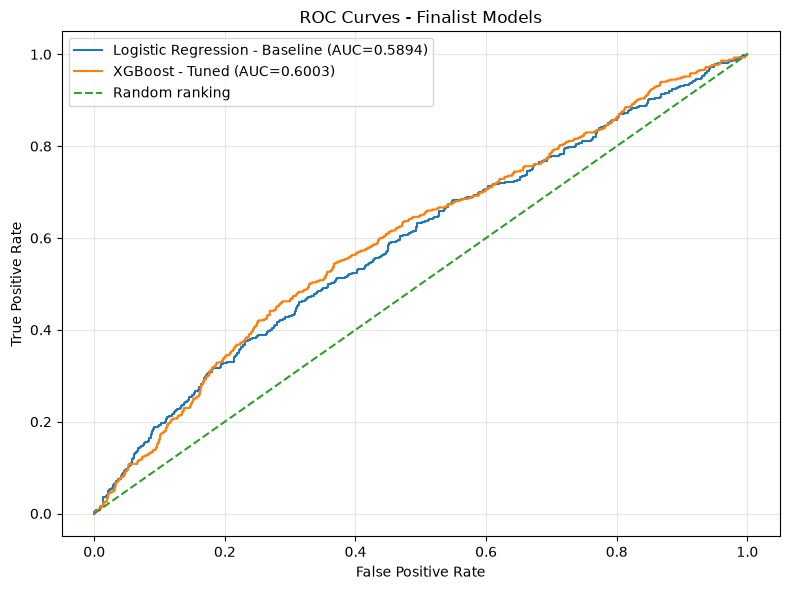

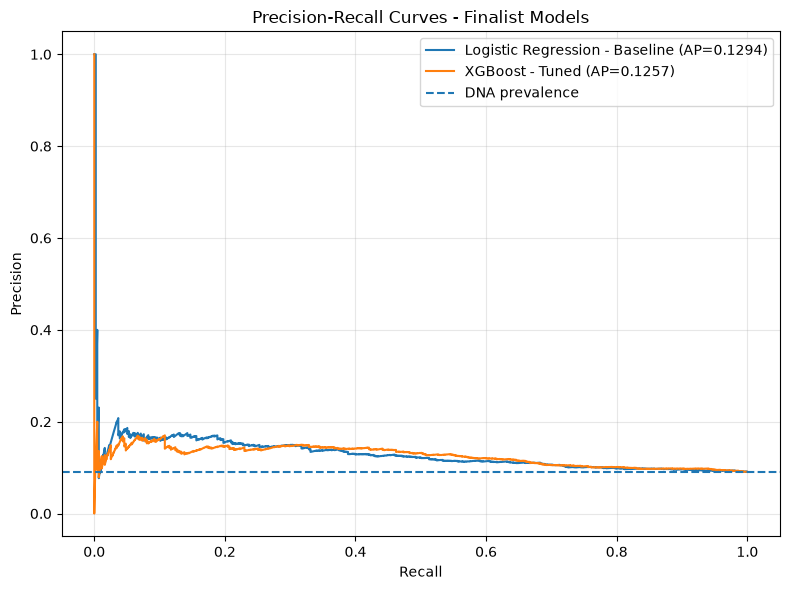

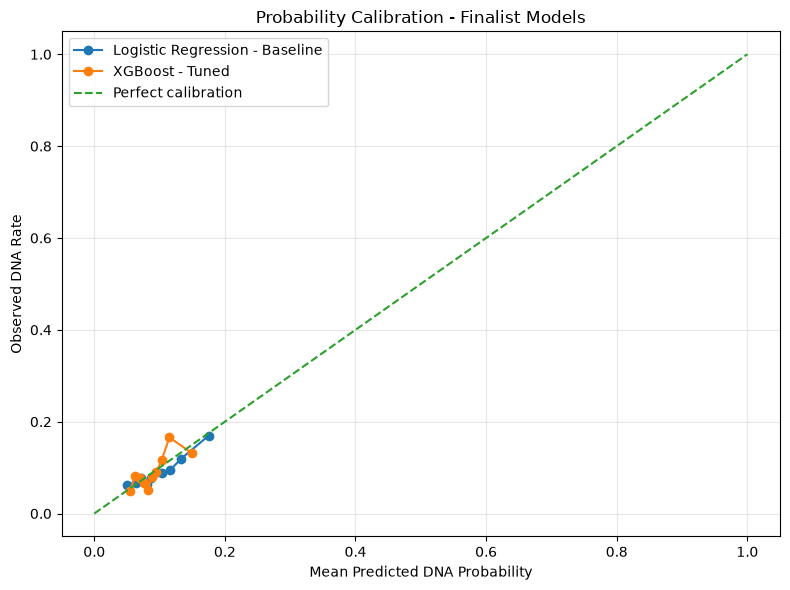


Calibration summary


,model,bin,mean_predicted_probability,observed_dna_rate,calibration_difference
0,Logistic Regression - Baseline,1,0.0501,0.0628,0.0126
1,Logistic Regression - Baseline,2,0.0634,0.0671,0.0037
2,Logistic Regression - Baseline,3,0.0719,0.0776,0.0057
3,Logistic Regression - Baseline,4,0.0801,0.0650,-0.0151
4,Logistic Regression - Baseline,5,0.0874,0.0774,-0.0100
5,Logistic Regression - Baseline,6,0.0953,0.0901,-0.0052
6,Logistic Regression - Baseline,7,0.1039,0.0881,-0.0158
7,Logistic Regression - Baseline,8,0.1158,0.0943,-0.0215
8,Logistic Regression - Baseline,9,0.1331,0.1195,-0.0136
9,Logistic Regression - Baseline,10,0.1751,0.1695,-0.0056



Calibration diagnostics


,model,mean_predicted_risk,actual_dna_prevalence,brier_score,log_loss,overall_risk_bias
0,Logistic Regression - Baseline,0.0976,0.0911,0.0822,0.3015,0.0065
1,XGBoost - Tuned,0.0897,0.0911,0.0821,0.3005,-0.0014



Weekly top-150 finalist comparison


,model,weeks_evaluated,total_selected_for_calls,total_dnas_captured,total_actual_dnas,random_expected_dnas,overall_precision,overall_recall,overall_lift_vs_random
0,Logistic Regression - Baseline,7,1050,148,435,96.2697,0.1410,0.3402,1.5373
1,XGBoost - Tuned,7,1050,153,435,96.2697,0.1457,0.3517,1.5893



Weekly DNA capture stability


model,appointment_week,Logistic Regression - Baseline,XGBoost - Tuned,xgboost_minus_logistic
0,2025-12-15,21,23,2
1,2025-12-22,25,25,0
2,2025-12-29,22,19,-3
3,2026-01-05,24,23,-1
4,2026-01-12,21,22,1
5,2026-01-19,12,15,3
6,2026-01-26,23,26,3



Weeks XGBoost identified more DNAs: 4
Weeks Logistic Regression identified more DNAs: 2
Weeks with equal DNA capture: 1


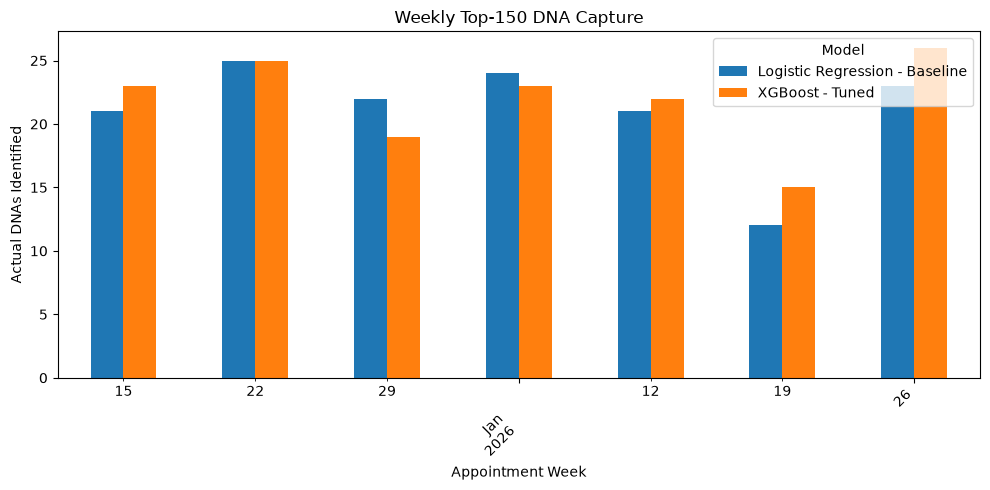


Weekly DNA capture difference: XGBoost minus Logistic
Observed mean difference per week: 0.714
Exploratory 95% bootstrap interval: [-0.857  2.143]

Provisional model selection


,model,weeks_evaluated,total_selected_for_calls,total_dnas_captured,total_actual_dnas,random_expected_dnas,overall_precision,overall_recall,overall_lift_vs_random,roc_auc,pr_auc,brier_score
0,XGBoost - Tuned,7,1050,153,435,96.2697,0.1457,0.3517,1.5893,0.6003,0.1257,0.0821
1,Logistic Regression - Baseline,7,1050,148,435,96.2697,0.1410,0.3402,1.5373,0.5894,0.1294,0.0822


Selected provisional model: XGBoost - Tuned
Selection basis: retrospective weekly DNA capture, with PR-AUC and Brier score as tie-breakers.
Alternative finalist: Logistic Regression - Baseline

Saving Cell 8 reports
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_finalist_validation_metrics.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_calibration_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_calibration_diagnostics.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_weekly_finalist_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_weekly_finalist_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell08_weekly_stability.csv
Saved: c:\U

In [34]:

# Final Model Selection and Validation Review


# Objectives:
# 1. Compare baseline Logistic Regression and tuned XGBoost.
# 2. Review ROC-AUC, PR-AUC and probability calibration.
# 3. Evaluate retrospective weekly top-150 outreach.
# 4. Examine the stability of weekly DNA capture.
# 5. Select a provisional model for final test evaluation.
# 6. Save the comparison and model-selection reports.
#
# Validation data only.
# The untouched test dataset will not be evaluated.

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve,
    precision_recall_curve
)

from sklearn.calibration import calibration_curve

# Verify required outputs from previous cells

required_objects = [
    "baseline_models",
    "baseline_predictions",
    "tuned_models",
    "tuned_predictions",
    "baseline_comparison",
    "tuned_comparison",
    "weekly_base",
    "weekly_outreach_summary",
    "tuned_weekly_summary",
    "y_val",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cells 1-7 first. Missing: {missing_objects}"
)

MODEL_REPORT_DIR = Path(MODEL_REPORT_DIR)
MODEL_REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Cell 8: Final model selection and validation review")
print("Previous cell outputs verified.")

# Define the two finalist models.
#
# Logistic Regression is the strongest baseline by PR-AUC.
# Tuned XGBoost is our strongest model for retrospective
# weekly DNA identification.
#
# Preserve the trained pipelines from earlier cells.

finalist_models = {
    "Logistic Regression - Baseline": {
        "pipeline": baseline_models["Logistic Regression"],
        "probabilities": np.asarray(
            baseline_predictions["Logistic Regression"],
            dtype=float
        )
    },
    "XGBoost - Tuned": {
        "pipeline": tuned_models["XGBoost"],
        "probabilities": np.asarray(
            tuned_predictions["XGBoost"],
            dtype=float
        )
    }
}

actual_labels = np.asarray(y_val, dtype=int)

assert set(np.unique(actual_labels)) == {0, 1}

for model_name, model_info in finalist_models.items():

    probabilities = model_info["probabilities"]

    assert len(probabilities) == len(actual_labels)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

print("\nFinalist models:")
for model_name in finalist_models:
    print("-", model_name)

# Calculate validation performance.
#
# ROC-AUC evaluates discrimination between classes.
# Brier score and log loss evaluate probability quality.
#
# Higher ROC-AUC and PR-AUC are better.

validation_results = []

for model_name, model_info in finalist_models.items():

    probabilities = model_info["probabilities"]

    validation_results.append({
        "model": model_name,
        "roc_auc": roc_auc_score(
            actual_labels,
            probabilities
        ),
        "pr_auc": average_precision_score(
            actual_labels,
            probabilities
        ),
        "brier_score": brier_score_loss(
            actual_labels,
            probabilities
        ),
        "log_loss": log_loss(
            actual_labels,
            probabilities,
            labels=[0, 1]
        ),
        "mean_predicted_risk": probabilities.mean(),
        "actual_dna_prevalence": actual_labels.mean()
    })

finalist_validation = pd.DataFrame(validation_results)

print("\nValidation performance comparison")
display(finalist_validation.round(4))

# Plot ROC curves.
#
# The diagonal represents random ranking.
# Curves above the diagonal indicate useful discrimination.

plt.figure(figsize=(8, 6))

for model_name, model_info in finalist_models.items():

    probabilities = model_info["probabilities"]

    fpr, tpr, _ = roc_curve(
        actual_labels,
        probabilities
    )

    auc_score = roc_auc_score(
        actual_labels,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Finalist Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot precision-recall curves.
#
# The horizontal reference represents DNA prevalence.


plt.figure(figsize=(8, 6))

for model_name, model_info in finalist_models.items():

    probabilities = model_info["probabilities"]

    precision, recall, _ = precision_recall_curve(
        actual_labels,
        probabilities
    )

    ap_score = average_precision_score(
        actual_labels,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap_score:.4f})"
    )

plt.axhline(
    y=actual_labels.mean(),
    linestyle="--",
    label="DNA prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Finalist Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Evaluate probability calibration.
#
# Calibration checks whether predicted risks correspond
# to observed DNA frequencies.


calibration_rows = []

plt.figure(figsize=(8, 6))

for model_name, model_info in finalist_models.items():

    probabilities = model_info["probabilities"]

    observed_fraction, mean_predicted = calibration_curve(
        actual_labels,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        observed_fraction,
        marker="o",
        label=model_name
    )

    # Store bin-level calibration results.
    # Quantile bins may merge if probability values repeat.

    for bin_number, (predicted, observed) in enumerate(
        zip(mean_predicted, observed_fraction),
        start=1
    ):

        calibration_rows.append({
            "model": model_name,
            "bin": bin_number,
            "mean_predicted_probability": predicted,
            "observed_dna_rate": observed,
            "calibration_difference": observed - predicted
        })

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted DNA Probability")
plt.ylabel("Observed DNA Rate")
plt.title("Probability Calibration - Finalist Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

calibration_summary = pd.DataFrame(calibration_rows)

print("\nCalibration summary")
display(calibration_summary.round(4))

# Calculate an additional calibration diagnostic.
#
# Compare the mean predicted risk with the actual
# DNA prevalence for each finalist.

calibration_diagnostics = finalist_validation[
    [
        "model",
        "mean_predicted_risk",
        "actual_dna_prevalence",
        "brier_score",
        "log_loss"
    ]
].copy()

calibration_diagnostics["overall_risk_bias"] = (
    calibration_diagnostics["mean_predicted_risk"]
    - calibration_diagnostics["actual_dna_prevalence"]
)

print("\nCalibration diagnostics")
display(calibration_diagnostics.round(4))

# Reproduce the weekly top-150 selection for each finalist.


WEEKLY_CALL_CAPACITY = 150

weekly_finalist_rows = []

for model_name, model_info in finalist_models.items():

    model_data = weekly_base.copy()

    model_data["predicted_dna_probability"] = (
        model_info["probabilities"]
    )

    for appointment_week, week_data in model_data.groupby(
        "appointment_week"
    ):

        ranked_week = week_data.sort_values(
            [
                "predicted_dna_probability",
                "appointment_id"
            ],
            ascending=[False, True]
        )

        selected = ranked_week.head(
            WEEKLY_CALL_CAPACITY
        )

        selected_count = len(selected)

        captured_dnas = int(
            selected["actual_dna"].sum()
        )

        total_week_dnas = int(
            week_data["actual_dna"].sum()
        )

        random_expected = (
            selected_count
            * total_week_dnas
            / len(week_data)
        )

        weekly_finalist_rows.append({
            "model": model_name,
            "appointment_week": appointment_week,
            "total_appointments": len(week_data),
            "total_dnas": total_week_dnas,
            "selected_for_calls": selected_count,
            "captured_dnas": captured_dnas,
            "random_expected_dnas": random_expected,
            "precision_at_capacity": (
                captured_dnas / selected_count
                if selected_count > 0 else np.nan
            ),
            "recall_at_capacity": (
                captured_dnas / total_week_dnas
                if total_week_dnas > 0 else np.nan
            )
        })

weekly_finalist_results = pd.DataFrame(
    weekly_finalist_rows
)

# Aggregate performance across validation weeks.

weekly_finalist_summary = (
    weekly_finalist_results
    .groupby("model", as_index=False)
    .agg(
        weeks_evaluated=("appointment_week", "nunique"),
        total_selected_for_calls=(
            "selected_for_calls", "sum"
        ),
        total_dnas_captured=("captured_dnas", "sum"),
        total_actual_dnas=("total_dnas", "sum"),
        random_expected_dnas=(
            "random_expected_dnas", "sum"
        )
    )
)

weekly_finalist_summary["overall_precision"] = (
    weekly_finalist_summary["total_dnas_captured"]
    / weekly_finalist_summary["total_selected_for_calls"]
)

weekly_finalist_summary["overall_recall"] = (
    weekly_finalist_summary["total_dnas_captured"]
    / weekly_finalist_summary["total_actual_dnas"]
)

weekly_finalist_summary["overall_lift_vs_random"] = (
    weekly_finalist_summary["total_dnas_captured"]
    / weekly_finalist_summary["random_expected_dnas"]
)

print("\nWeekly top-150 finalist comparison")
display(weekly_finalist_summary.round(4))

# Compare the finalists week by week.


weekly_stability = weekly_finalist_results.pivot(
    index="appointment_week",
    columns="model",
    values="captured_dnas"
).reset_index()

weekly_stability["xgboost_minus_logistic"] = (
    weekly_stability["XGBoost - Tuned"]
    - weekly_stability["Logistic Regression - Baseline"]
)

print("\nWeekly DNA capture stability")
display(weekly_stability)

print(
    "\nWeeks XGBoost identified more DNAs:",
    int((weekly_stability["xgboost_minus_logistic"] > 0).sum())
)

print(
    "Weeks Logistic Regression identified more DNAs:",
    int((weekly_stability["xgboost_minus_logistic"] < 0).sum())
)

print(
    "Weeks with equal DNA capture:",
    int((weekly_stability["xgboost_minus_logistic"] == 0).sum())
)

# Plot weekly DNA capture.
#
# The visualization to assess whether performance
# differences are consistent across the validation period.

weekly_plot = weekly_stability.set_index(
    "appointment_week"
)[
    [
        "Logistic Regression - Baseline",
        "XGBoost - Tuned"
    ]
]

weekly_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Appointment Week")
plt.ylabel("Actual DNAs Identified")
plt.title("Weekly Top-150 DNA Capture")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# Calculate a descriptive paired bootstrap interval.


weekly_differences = weekly_stability[
    "xgboost_minus_logistic"
].to_numpy()

rng = np.random.default_rng(42)

bootstrap_samples = 5000

bootstrap_mean_differences = []

for _ in range(bootstrap_samples):

    sampled_differences = rng.choice(
        weekly_differences,
        size=len(weekly_differences),
        replace=True
    )

    bootstrap_mean_differences.append(
        sampled_differences.mean()
    )

bootstrap_interval = np.percentile(
    bootstrap_mean_differences,
    [2.5, 97.5]
)

observed_mean_difference = weekly_differences.mean()

print("\nWeekly DNA capture difference: XGBoost minus Logistic")
print(
    "Observed mean difference per week:",
    round(observed_mean_difference, 3)
)

print(
    "Exploratory 95% bootstrap interval:",
    np.round(bootstrap_interval, 3)
)

# Select a provisional model.


selection_table = weekly_finalist_summary.merge(
    finalist_validation[
        [
            "model",
            "roc_auc",
            "pr_auc",
            "brier_score"
        ]
    ],
    on="model",
    how="inner",
    validate="one_to_one"
)

selection_table = selection_table.sort_values(
    [
        "total_dnas_captured",
        "pr_auc",
        "brier_score"
    ],
    ascending=[False, False, True]
).reset_index(drop=True)

provisional_model_name = selection_table.loc[
    0, "model"
]

provisional_model = finalist_models[
    provisional_model_name
]["pipeline"]

provisional_validation_probabilities = finalist_models[
    provisional_model_name
]["probabilities"]

print("\nProvisional model selection")
display(selection_table.round(4))

print("Selected provisional model:", provisional_model_name)

print(
    "Selection basis: retrospective weekly DNA capture, "
    "with PR-AUC and Brier score as tie-breakers."
)

# Preserve the alternative model for sensitivity analysis.
#
# The alternative can be used to investigate whether
# conclusions depend strongly on the chosen algorithm.

alternative_model_name = next(
    name for name in finalist_models
    if name != provisional_model_name
)

alternative_model = finalist_models[
    alternative_model_name
]["pipeline"]

print("Alternative finalist:", alternative_model_name)

# Save validation review reports.

cell08_reports = {
    "cell08_finalist_validation_metrics.csv":
        finalist_validation,

    "cell08_calibration_summary.csv":
        calibration_summary,

    "cell08_calibration_diagnostics.csv":
        calibration_diagnostics,

    "cell08_weekly_finalist_results.csv":
        weekly_finalist_results,

    "cell08_weekly_finalist_summary.csv":
        weekly_finalist_summary,

    "cell08_weekly_stability.csv":
        weekly_stability,

    "cell08_model_selection.csv":
        selection_table
}

print("\nSaving Cell 8 reports")

for filename, report in cell08_reports.items():

    output_path = MODEL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Save the provisional fitted pipeline.
#
# The pipeline includes preprocessing and the estimator.

model_artifact_path = (
    MODEL_REPORT_DIR / "cell08_provisional_model.joblib"
)

joblib.dump(
    provisional_model,
    model_artifact_path
)

print("Saved fitted model:", model_artifact_path)

# Save the model-selection decision as a readable CSV.

selection_decision = pd.DataFrame([
    {
        "selected_model": provisional_model_name,
        "alternative_model": alternative_model_name,
        "selection_metric": "retrospective_weekly_dna_capture",
        "validation_weeks": len(weekly_stability),
        "test_dataset_used": False,
        "selection_status": "provisional",
        "important_limitation": (
            "Appointment-week ranking is retrospective; "
            "prospective outreach eligibility is unverified."
        )
    }
])

selection_decision_path = (
    MODEL_REPORT_DIR / "cell08_selection_decision.csv"
)

selection_decision.to_csv(
    selection_decision_path,
    index=False
)

print("Saved decision:", selection_decision_path)

# Perform final validation checks.

assert len(finalist_validation) == 2
assert len(weekly_finalist_summary) == 2
assert len(selection_table) == 2

assert (
    weekly_finalist_results["selected_for_calls"]
    <= WEEKLY_CALL_CAPACITY
).all()

assert (
    weekly_finalist_results["captured_dnas"]
    <= weekly_finalist_results["total_dnas"]
).all()

assert provisional_model_name in finalist_models
assert alternative_model_name in finalist_models

assert len(provisional_validation_probabilities) == len(
    actual_labels
)

print("\nCell 8 completed successfully.")
print("Finalist models reviewed:", len(finalist_models))
print("Provisional model:", provisional_model_name)
print("Test dataset evaluated: NO")
print("Next stage: Untouched test evaluation and fairness.")


CELL 9: FINAL UNTOUCHED TEST EVALUATION

Test appointments: 5488
Actual DNAs: 524
Actual attendances: 4964
Test DNA prevalence: 0.0955

Predictions generated successfully.
Models: ['XGBoost - Tuned', 'Logistic Regression - Baseline']

Validation-selected classification thresholds


,model,threshold_source,selected_threshold,validation_precision,validation_recall,validation_f1
0,XGBoost - Tuned,validation_only,0.1000,0.1414,0.4414,0.2142
1,Logistic Regression - Baseline,validation_only,0.1165,0.1399,0.3747,0.2037



Model: XGBoost - Tuned
Threshold: Default 0.50
Threshold value: 0.5
              precision    recall  f1-score   support

    Attended       0.90      1.00      0.95      4964
         DNA       0.00      0.00      0.00       524

    accuracy                           0.90      5488
   macro avg       0.45      0.50      0.47      5488
weighted avg       0.82      0.90      0.86      5488



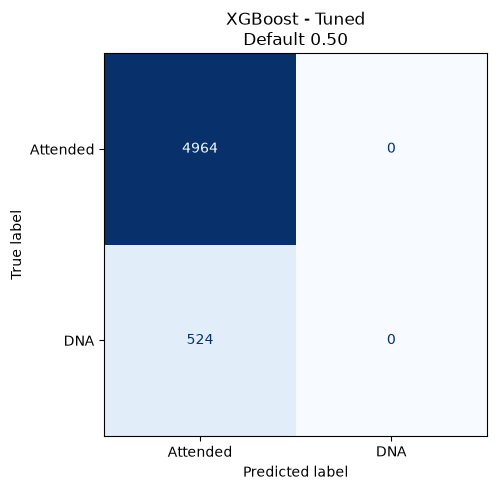


Model: XGBoost - Tuned
Threshold: Validation-selected F1
Threshold value: 0.1
              precision    recall  f1-score   support

    Attended       0.92      0.72      0.81      4964
         DNA       0.13      0.41      0.20       524

    accuracy                           0.69      5488
   macro avg       0.53      0.56      0.50      5488
weighted avg       0.84      0.69      0.75      5488



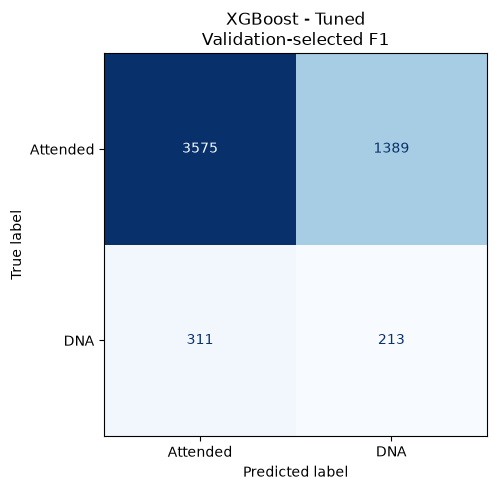


Model: Logistic Regression - Baseline
Threshold: Default 0.50
Threshold value: 0.5
              precision    recall  f1-score   support

    Attended       0.90      1.00      0.95      4964
         DNA       0.00      0.00      0.00       524

    accuracy                           0.90      5488
   macro avg       0.45      0.50      0.47      5488
weighted avg       0.82      0.90      0.86      5488



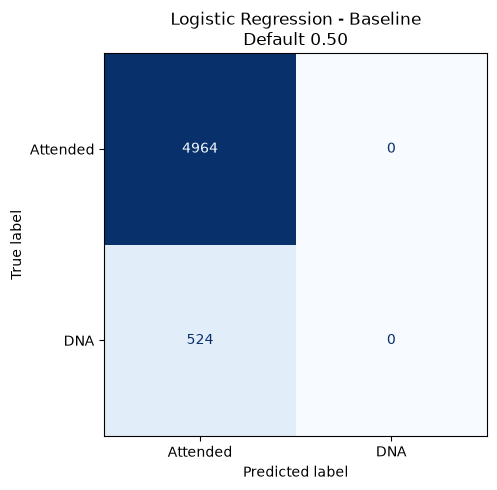


Model: Logistic Regression - Baseline
Threshold: Validation-selected F1
Threshold value: 0.1165
              precision    recall  f1-score   support

    Attended       0.92      0.77      0.84      4964
         DNA       0.14      0.35      0.20       524

    accuracy                           0.73      5488
   macro avg       0.53      0.56      0.52      5488
weighted avg       0.84      0.73      0.78      5488



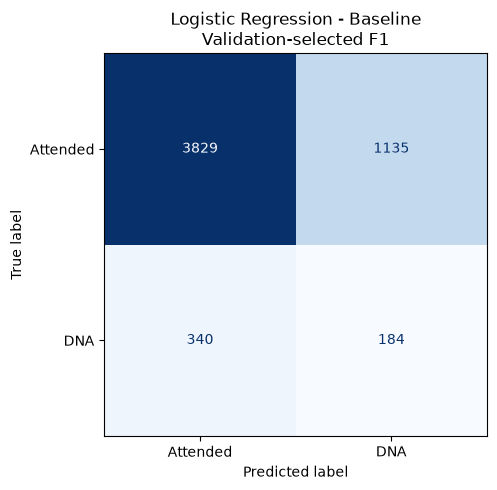


Final classification metric comparison


,model,threshold_type,threshold,accuracy,precision,recall_sensitivity,specificity,f1_score,true_positives,true_negatives,false_positives,false_negatives
0,XGBoost - Tuned,Default 0.50,0.5000,0.9045,0.0000,0.0000,1.0000,0.0000,0,4964,0,524
1,XGBoost - Tuned,Validation-selected F1,0.1000,0.6902,0.1330,0.4065,0.7202,0.2004,213,3575,1389,311
2,Logistic Regression - Baseline,Default 0.50,0.5000,0.9045,0.0000,0.0000,1.0000,0.0000,0,4964,0,524
3,Logistic Regression - Baseline,Validation-selected F1,0.1165,0.7312,0.1395,0.3511,0.7714,0.1997,184,3829,1135,340



Confusion matrix counts


,model,threshold_type,threshold,TN,FP,FN,TP
0,XGBoost - Tuned,Default 0.50,0.5000,4964,0,524,0
1,XGBoost - Tuned,Validation-selected F1,0.1000,3575,1389,311,213
2,Logistic Regression - Baseline,Default 0.50,0.5000,4964,0,524,0
3,Logistic Regression - Baseline,Validation-selected F1,0.1165,3829,1135,340,184



Final test discrimination and calibration metrics


,model,test_appointments,test_dnas,dna_prevalence,roc_auc,pr_auc,brier_score,log_loss,mean_predicted_risk
0,XGBoost - Tuned,5488,524,0.0955,0.6042,0.1328,0.0854,0.3095,0.0904
1,Logistic Regression - Baseline,5488,524,0.0955,0.5982,0.1357,0.0854,0.3096,0.0978


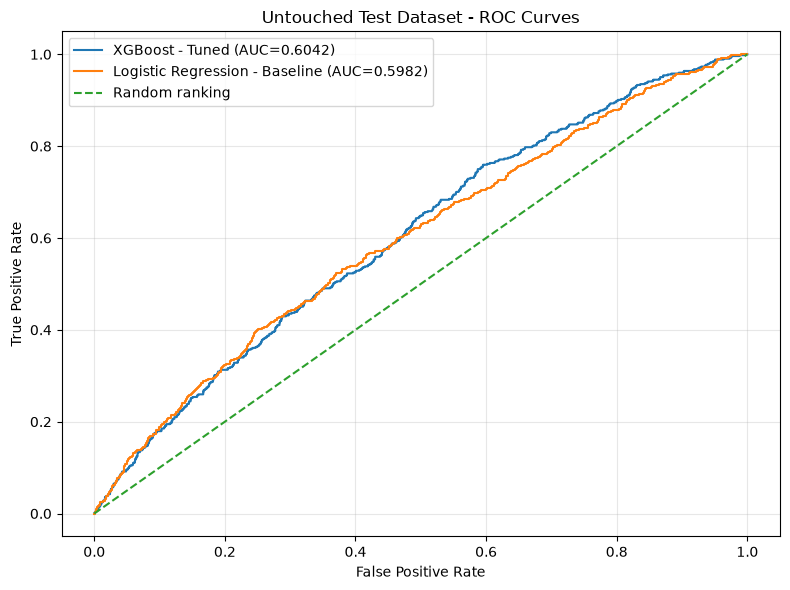

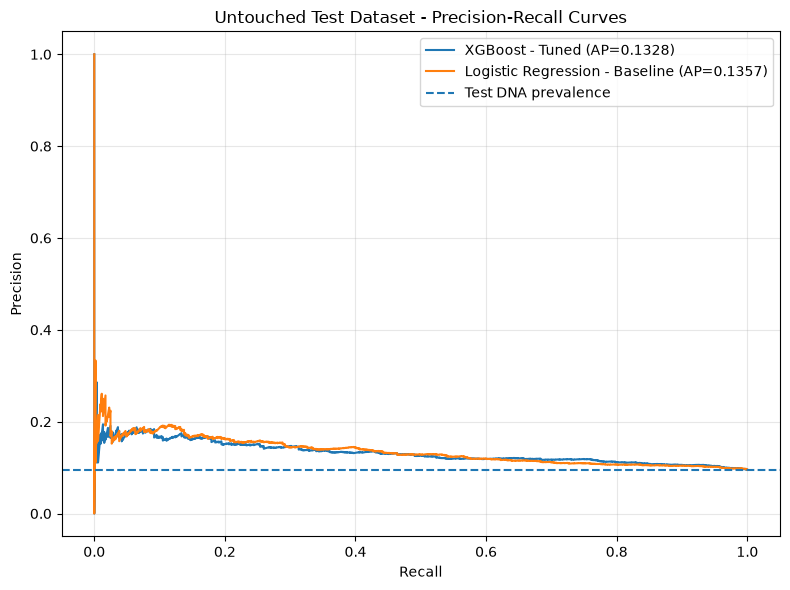

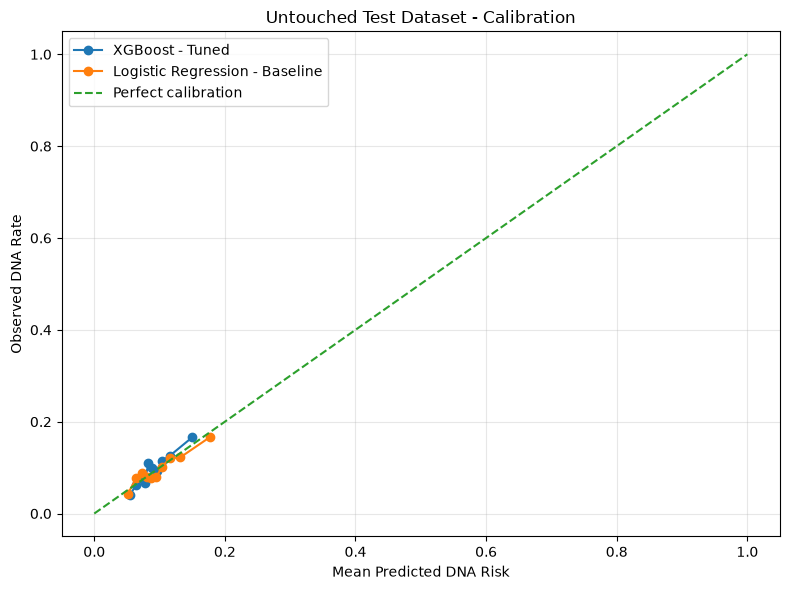


Test calibration results


,model,bin,mean_predicted_risk,observed_dna_rate,difference
0,XGBoost - Tuned,1,0.0544,0.0401,-0.0143
1,XGBoost - Tuned,2,0.0641,0.0619,-0.0021
2,XGBoost - Tuned,3,0.0710,0.0765,0.0055
3,XGBoost - Tuned,4,0.0771,0.0675,-0.0095
4,XGBoost - Tuned,5,0.0828,0.1093,0.0265
5,XGBoost - Tuned,6,0.0890,0.1002,0.0112
6,XGBoost - Tuned,7,0.0961,0.0931,-0.0030
7,XGBoost - Tuned,8,0.1039,0.1148,0.0109
8,XGBoost - Tuned,9,0.1156,0.1257,0.0101
9,XGBoost - Tuned,10,0.1498,0.1658,0.0160



Final retrospective weekly top-150 evaluation


,model,weeks_evaluated,total_selected,total_dnas_captured,total_dnas,random_expected_dnas,precision_at_capacity,recall_at_capacity,lift_vs_random
0,Logistic Regression - Baseline,9,1350,190,524,131.4091,0.1407,0.3626,1.4459
1,XGBoost - Tuned,9,1350,187,524,131.4091,0.1385,0.3569,1.4230



Weekly breakdown


,model,appointment_week,total_appointments,total_dnas,selected_appointments,captured_dnas,random_expected_dnas,precision_at_capacity,recall_at_capacity
0,XGBoost - Tuned,2026-02-02/2026-02-08,209,23,150,17,16.5072,0.1133,0.7391
1,XGBoost - Tuned,2026-02-09/2026-02-15,684,78,150,31,17.1053,0.2067,0.3974
2,XGBoost - Tuned,2026-02-16/2026-02-22,679,61,150,23,13.4757,0.1533,0.3770
3,XGBoost - Tuned,2026-02-23/2026-03-01,701,57,150,19,12.1969,0.1267,0.3333
4,XGBoost - Tuned,2026-03-02/2026-03-08,739,61,150,22,12.3816,0.1467,0.3607
5,XGBoost - Tuned,2026-03-09/2026-03-15,675,61,150,16,13.5556,0.1067,0.2623
6,XGBoost - Tuned,2026-03-16/2026-03-22,692,57,150,19,12.3555,0.1267,0.3333
7,XGBoost - Tuned,2026-03-23/2026-03-29,688,80,150,21,17.4419,0.1400,0.2625
8,XGBoost - Tuned,2026-03-30/2026-04-05,421,46,150,19,16.3895,0.1267,0.4130
9,Logistic Regression - Baseline,2026-02-02/2026-02-08,209,23,150,17,16.5072,0.1133,0.7391



Validation versus untouched test comparison


,model,test_appointments,test_dnas,dna_prevalence,roc_auc,pr_auc,brier_score,log_loss,mean_predicted_risk,validation_roc_auc,validation_pr_auc,validation_brier_score,roc_auc_change,pr_auc_change
0,XGBoost - Tuned,5488,524,0.0955,0.6042,0.1328,0.0854,0.3095,0.0904,0.6003,0.1257,0.0821,0.0038,0.0071
1,Logistic Regression - Baseline,5488,524,0.0955,0.5982,0.1357,0.0854,0.3096,0.0978,0.5894,0.1294,0.0822,0.0088,0.0063



Saving Cell 9 reports
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_validation_thresholds.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_classification_metrics.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_confusion_matrices.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_test_metrics.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_test_calibration.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_weekly_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_weekly_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\cell09_selected_

In [35]:

# Final Evaluation on the Untouched Test Dataset
# NHS Dorset - Outpatient DNA Prediction

# Objectives:
# Evaluate the selected XGBoost model on unseen test data.
# Compare against baseline Logistic Regression.
# Display confusion matrices at 0.50 and validation-selected thresholds.
# Report classification, ranking and calibration metrics.
# Evaluate retrospective weekly top-150 appointment selection.
# Save all final evaluation reports.
#
# Do not retrain, retune or select models using test results.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    roc_curve
)

from sklearn.calibration import calibration_curve

print("CELL 9: FINAL UNTOUCHED TEST EVALUATION")

# Verify that all required objects exist.

required_objects = [
    "provisional_model",
    "provisional_model_name",
    "alternative_model",
    "alternative_model_name",
    "X_val_input",
    "X_test_input",
    "y_val",
    "y_test",
    "df_test",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run previous cells first. Missing: {missing_objects}"
)

MODEL_REPORT_DIR = Path(MODEL_REPORT_DIR)
MODEL_REPORT_DIR.mkdir(parents=True, exist_ok=True)

assert provisional_model_name == "XGBoost - Tuned", (
    "Check Cell 8 model selection before final evaluation."
)

assert alternative_model_name == "Logistic Regression - Baseline"

assert len(X_test_input) == len(y_test)
assert len(X_val_input) == len(y_val)
assert len(df_test) == len(y_test)

assert len(y_test) == 5488, (
    "Unexpected test population. Verify the chronological split."
)

y_val_array = np.asarray(y_val, dtype=int)
y_test_array = np.asarray(y_test, dtype=int)

assert set(np.unique(y_test_array)) == {0, 1}
assert int(y_test_array.sum()) == 524

print("\nTest appointments:", len(y_test_array))
print("Actual DNAs:", int(y_test_array.sum()))
print("Actual attendances:", int((y_test_array == 0).sum()))
print("Test DNA prevalence:", round(y_test_array.mean(), 4))

# Preserve the model selection made in Cell 8.


test_models = {
    provisional_model_name: provisional_model,
    alternative_model_name: alternative_model
}

# Generate probabilities for both validation and test data.


validation_probabilities = {}
test_probabilities = {}

for model_name, fitted_model in test_models.items():

    validation_probabilities[model_name] = (
        fitted_model.predict_proba(X_val_input)[:, 1]
    )

    test_probabilities[model_name] = (
        fitted_model.predict_proba(X_test_input)[:, 1]
    )

    assert len(
        validation_probabilities[model_name]
    ) == len(y_val_array)

    assert len(
        test_probabilities[model_name]
    ) == len(y_test_array)

    assert np.isfinite(
        test_probabilities[model_name]
    ).all()

    assert (
        (test_probabilities[model_name] >= 0)
        & (test_probabilities[model_name] <= 1)
    ).all()

print("\nPredictions generated successfully.")
print("Models:", list(test_models))

# Select an F1-maximizing threshold using validation data only.


threshold_selection_rows = []

selected_thresholds = {}

for model_name, probabilities in validation_probabilities.items():

    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_val_array,
            probabilities
        )
    )

    # The final precision/recall point has no corresponding threshold.

    precision_at_threshold = precision_values[:-1]
    recall_at_threshold = recall_values[:-1]

    f1_values = (
        2 * precision_at_threshold * recall_at_threshold
        / np.maximum(
            precision_at_threshold + recall_at_threshold,
            1e-12
        )
    )

    best_index = int(np.argmax(f1_values))

    best_threshold = float(thresholds[best_index])

    selected_thresholds[model_name] = best_threshold

    threshold_selection_rows.append({
        "model": model_name,
        "threshold_source": "validation_only",
        "selected_threshold": best_threshold,
        "validation_precision": float(
            precision_at_threshold[best_index]
        ),
        "validation_recall": float(
            recall_at_threshold[best_index]
        ),
        "validation_f1": float(f1_values[best_index])
    })

threshold_selection = pd.DataFrame(
    threshold_selection_rows
)

print("\nValidation-selected classification thresholds")
display(threshold_selection.round(4))

# Evaluate classification metrics and confusion matrices.
#
# Positive class 1 means DNA.
#
# TN: correctly predicted attendance
# FP: predicted DNA but patient attended
# FN: predicted attendance but patient was DNA
# TP: correctly predicted DNA

classification_rows = []
confusion_rows = []

for model_name, probabilities in test_probabilities.items():

    evaluation_thresholds = {
        "Default 0.50": 0.50,
        "Validation-selected F1": selected_thresholds[model_name]
    }

    for threshold_name, threshold in evaluation_thresholds.items():

        predicted_labels = (
            probabilities >= threshold
        ).astype(int)

        cm = confusion_matrix(
            y_test_array,
            predicted_labels,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )

        classification_rows.append({
            "model": model_name,
            "threshold_type": threshold_name,
            "threshold": threshold,
            "accuracy": accuracy_score(
                y_test_array,
                predicted_labels
            ),
            "precision": precision_score(
                y_test_array,
                predicted_labels,
                zero_division=0
            ),
            "recall_sensitivity": recall_score(
                y_test_array,
                predicted_labels,
                zero_division=0
            ),
            "specificity": specificity,
            "f1_score": f1_score(
                y_test_array,
                predicted_labels,
                zero_division=0
            ),
            "true_positives": int(tp),
            "true_negatives": int(tn),
            "false_positives": int(fp),
            "false_negatives": int(fn)
        })

        confusion_rows.append({
            "model": model_name,
            "threshold_type": threshold_name,
            "threshold": threshold,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

        print("\nModel:", model_name)
        print("Threshold:", threshold_name)
        print("Threshold value:", round(threshold, 4))

        print(
            classification_report(
                y_test_array,
                predicted_labels,
                labels=[0, 1],
                target_names=["Attended", "DNA"],
                zero_division=0
            )
        )

        display_plot = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Attended", "DNA"]
        )

        fig, ax = plt.subplots(figsize=(6, 5))

        display_plot.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            f"{model_name}\n{threshold_name}"
        )

        plt.tight_layout()
        plt.show()

classification_results = pd.DataFrame(
    classification_rows
)

confusion_results = pd.DataFrame(
    confusion_rows
)

print("\nFinal classification metric comparison")
display(classification_results.round(4))

print("\nConfusion matrix counts")
display(confusion_results.round(4))

# Calculate threshold-independent test metrics.
#
# These assess discrimination and probability quality.
# No threshold optimization is performed on test data.

test_metric_rows = []

for model_name, probabilities in test_probabilities.items():

    test_metric_rows.append({
        "model": model_name,
        "test_appointments": len(y_test_array),
        "test_dnas": int(y_test_array.sum()),
        "dna_prevalence": y_test_array.mean(),
        "roc_auc": roc_auc_score(
            y_test_array,
            probabilities
        ),
        "pr_auc": average_precision_score(
            y_test_array,
            probabilities
        ),
        "brier_score": brier_score_loss(
            y_test_array,
            probabilities
        ),
        "log_loss": log_loss(
            y_test_array,
            probabilities,
            labels=[0, 1]
        ),
        "mean_predicted_risk": probabilities.mean()
    })

test_metrics = pd.DataFrame(test_metric_rows)

print("\nFinal test discrimination and calibration metrics")
display(test_metrics.round(4))

# Plot test ROC curves.


plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test_array,
        probabilities
    )

    auc_value = roc_auc_score(
        y_test_array,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Untouched Test Dataset - ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot test precision-recall curves.

plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test_array,
        probabilities
    )

    ap_value = average_precision_score(
        y_test_array,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap_value:.4f})"
    )

plt.axhline(
    y=y_test_array.mean(),
    linestyle="--",
    label="Test DNA prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Untouched Test Dataset - Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Assess test probability calibration.
#
# Calibration curves compare predicted risk with observed DNA rate.
# This is diagnostic only; no recalibration is fitted on test data.

test_calibration_rows = []

plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():

    observed_rate, predicted_risk = calibration_curve(
        y_test_array,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted_risk,
        observed_rate,
        marker="o",
        label=model_name
    )

    for bin_number, (predicted, observed) in enumerate(
        zip(predicted_risk, observed_rate),
        start=1
    ):

        test_calibration_rows.append({
            "model": model_name,
            "bin": bin_number,
            "mean_predicted_risk": predicted,
            "observed_dna_rate": observed,
            "difference": observed - predicted
        })

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted DNA Risk")
plt.ylabel("Observed DNA Rate")
plt.title("Untouched Test Dataset - Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

test_calibration = pd.DataFrame(
    test_calibration_rows
)

print("\nTest calibration results")
display(test_calibration.round(4))

# Evaluate the retrospective weekly top-150 strategy.


assert "appointment_id" in df_test.columns
assert "appointment_datetime" in df_test.columns
assert df_test["appointment_id"].is_unique

WEEKLY_CALL_CAPACITY = 150

test_weekly_base = pd.DataFrame({
    "appointment_id": df_test["appointment_id"].to_numpy(),
    "appointment_datetime": pd.to_datetime(
        df_test["appointment_datetime"]
    ).to_numpy(),
    "actual_dna": y_test_array
})

assert test_weekly_base["appointment_datetime"].notna().all()

test_weekly_base["appointment_week"] = (
    test_weekly_base["appointment_datetime"]
    .dt.to_period("W")
    .astype(str)
)

test_weekly_rows = []
test_selected_rows = []

for model_name, probabilities in test_probabilities.items():

    model_data = test_weekly_base.copy()

    model_data["predicted_dna_probability"] = probabilities

    for week, week_data in model_data.groupby(
        "appointment_week"
    ):

        ranked = week_data.sort_values(
            ["predicted_dna_probability", "appointment_id"],
            ascending=[False, True]
        )

        selected = ranked.head(
            WEEKLY_CALL_CAPACITY
        ).copy()

        selected["model"] = model_name

        test_selected_rows.append(selected)

        total_appointments = len(week_data)
        total_dnas = int(week_data["actual_dna"].sum())

        selected_count = len(selected)
        captured_dnas = int(selected["actual_dna"].sum())

        expected_random_dnas = (
            selected_count * total_dnas / total_appointments
        )

        test_weekly_rows.append({
            "model": model_name,
            "appointment_week": week,
            "total_appointments": total_appointments,
            "total_dnas": total_dnas,
            "selected_appointments": selected_count,
            "captured_dnas": captured_dnas,
            "random_expected_dnas": expected_random_dnas,
            "precision_at_capacity": (
                captured_dnas / selected_count
                if selected_count else np.nan
            ),
            "recall_at_capacity": (
                captured_dnas / total_dnas
                if total_dnas else np.nan
            )
        })

test_weekly_results = pd.DataFrame(
    test_weekly_rows
)

test_selected_appointments = pd.concat(
    test_selected_rows,
    ignore_index=True
)

# Summarize outreach ranking performance.

test_weekly_summary = (
    test_weekly_results
    .groupby("model", as_index=False)
    .agg(
        weeks_evaluated=("appointment_week", "nunique"),
        total_selected=("selected_appointments", "sum"),
        total_dnas_captured=("captured_dnas", "sum"),
        total_dnas=("total_dnas", "sum"),
        random_expected_dnas=("random_expected_dnas", "sum")
    )
)

test_weekly_summary["precision_at_capacity"] = (
    test_weekly_summary["total_dnas_captured"]
    / test_weekly_summary["total_selected"]
)

test_weekly_summary["recall_at_capacity"] = (
    test_weekly_summary["total_dnas_captured"]
    / test_weekly_summary["total_dnas"]
)

test_weekly_summary["lift_vs_random"] = (
    test_weekly_summary["total_dnas_captured"]
    / test_weekly_summary["random_expected_dnas"]
)

print("\nFinal retrospective weekly top-150 evaluation")
display(test_weekly_summary.round(4))

print("\nWeekly breakdown")
display(test_weekly_results.round(4))

# Compare test performance with the earlier validation results.


validation_reference = finalist_validation[
    ["model", "roc_auc", "pr_auc", "brier_score"]
].copy()

validation_reference = validation_reference.rename(
    columns={
        "roc_auc": "validation_roc_auc",
        "pr_auc": "validation_pr_auc",
        "brier_score": "validation_brier_score"
    }
)

validation_test_comparison = test_metrics.merge(
    validation_reference,
    on="model",
    how="left",
    validate="one_to_one"
)

validation_test_comparison["roc_auc_change"] = (
    validation_test_comparison["roc_auc"]
    - validation_test_comparison["validation_roc_auc"]
)

validation_test_comparison["pr_auc_change"] = (
    validation_test_comparison["pr_auc"]
    - validation_test_comparison["validation_pr_auc"]
)

print("\nValidation versus untouched test comparison")
display(validation_test_comparison.round(4))

# Save the evaluation reports.


cell09_reports = {
    "cell09_validation_thresholds.csv":
        threshold_selection,

    "cell09_classification_metrics.csv":
        classification_results,

    "cell09_confusion_matrices.csv":
        confusion_results,

    "cell09_test_metrics.csv":
        test_metrics,

    "cell09_test_calibration.csv":
        test_calibration,

    "cell09_weekly_results.csv":
        test_weekly_results,

    "cell09_weekly_summary.csv":
        test_weekly_summary,

    "cell09_selected_appointments_research_only.csv":
        test_selected_appointments,

    "cell09_validation_test_comparison.csv":
        validation_test_comparison
}

print("\nSaving Cell 9 reports")

for filename, report in cell09_reports.items():

    output_path = MODEL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Perform final checks.

assert len(test_metrics) == 2
assert len(classification_results) == 4
assert len(confusion_results) == 4

assert (
    test_weekly_results["selected_appointments"]
    <= WEEKLY_CALL_CAPACITY
).all()

assert (
    test_weekly_results["captured_dnas"]
    <= test_weekly_results["total_dnas"]
).all()

for _, result in confusion_results.iterrows():

    assert (
        result["TN"]
        + result["FP"]
        + result["FN"]
        + result["TP"]
    ) == len(y_test_array)

print("\nCELL 9 COMPLETED SUCCESSFULLY")

print("Selected model:", provisional_model_name)
print("Alternative model:", alternative_model_name)
print("Test appointments:", len(y_test_array))
print("Test DNAs:", int(y_test_array.sum()))

print("\nFinal model selection remains unchanged.")
print("No model retraining or test-based threshold tuning.")
print("Next stage: Fairness assessment and outreach impact.")


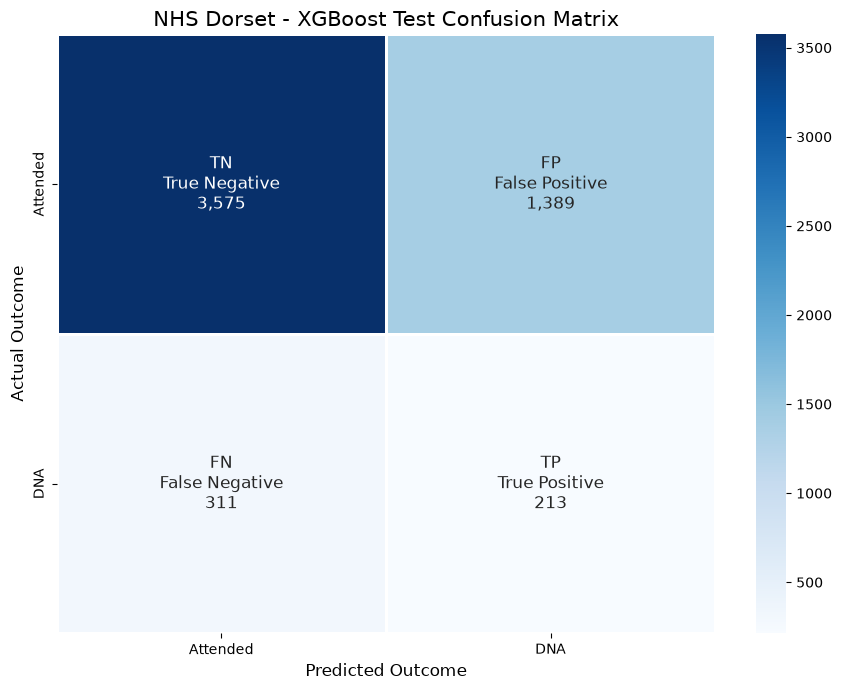

In [36]:
# Confusion Matrix Visualization

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Get XGBoost predictions on the untouched test dataset
probabilities = test_probabilities["XGBoost - Tuned"]

# Use the threshold selected from validation data
threshold = selected_thresholds["XGBoost - Tuned"]

# Convert predicted probabilities into class predictions
predictions = (probabilities >= threshold).astype(int)

# Calculate confusion matrix from actual test outcomes
cm = confusion_matrix(
    y_test_array,
    predictions,
    labels=[0, 1]
)

# Extract the four confusion matrix values
tn, fp, fn, tp = cm.ravel()

# Create labels containing both the name and calculated count
labels = np.array([
    [f"TN\nTrue Negative\n{tn:,}",
     f"FP\nFalse Positive\n{fp:,}"],
    [f"FN\nFalse Negative\n{fn:,}",
     f"TP\nTrue Positive\n{tp:,}"]
])

# Display the colored confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    xticklabels=["Attended", "DNA"],
    yticklabels=["Attended", "DNA"],
    linewidths=2,
    linecolor="white",
    annot_kws={"size": 12},
    cbar=True
)

plt.title(
    "NHS Dorset - XGBoost Test Confusion Matrix",
    fontsize=15
)

plt.xlabel("Predicted Outcome", fontsize=12)
plt.ylabel("Actual Outcome", fontsize=12)

plt.tight_layout()
plt.show()


CELL 11: FAIRNESS AND BIAS ASSESSMENT

Selected model: XGBoost - Tuned
Test appointments: 5488
Actual DNAs: 524
Classification threshold: 0.1

Fairness audit population prepared.
Appointments: 5488
Retrospectively selected appointments: 1350

SUBGROUP FAIRNESS RESULTS


,characteristic,group,appointments,actual_dnas,dna_prevalence,TN,FP,FN,TP,recall,precision,false_positive_rate,roc_auc,pr_auc,selection_rate,outreach_dna_recall,small_sample_warning
0,Age,18-34,902,117,0.1297,356,429,36,81,0.6923,0.1588,0.5465,0.5964,0.1751,0.4812,0.6068,False
1,Age,35-49,795,93,0.1170,442,260,51,42,0.4516,0.1391,0.3704,0.5595,0.1531,0.3208,0.3548,False
2,Age,50-64,797,70,0.0878,603,124,52,18,0.2571,0.1268,0.1706,0.5756,0.1257,0.1556,0.2286,False
3,Age,65-79,1581,104,0.0658,1393,84,96,8,0.0769,0.0870,0.0569,0.6103,0.0999,0.0582,0.1058,False
4,Age,80+,766,78,0.1018,520,168,58,20,0.2564,0.1064,0.2442,0.5273,0.1156,0.1997,0.1923,False
5,Age,Missing/Invalid,6,0,0.0000,6,0,0,0,NaN,NaN,0.0000,NaN,NaN,0.0000,NaN,True
6,Age,Under 18,641,62,0.0967,255,324,18,44,0.7097,0.1196,0.5596,0.6128,0.1322,0.4555,0.6613,False
7,Sex,Female,2854,299,0.1048,1850,705,174,125,0.4181,0.1506,0.2759,0.6067,0.1477,0.2446,0.3645,False
8,Sex,Male,2614,223,0.0853,1712,679,136,87,0.3901,0.1136,0.2840,0.6019,0.1223,0.2475,0.3453,False
9,Sex,Missing/Unknown,20,2,0.1000,13,5,1,1,0.5000,0.1667,0.2778,0.5556,0.1714,0.2500,0.5000,True



SUBGROUP CONFUSION MATRIX HEATMAPS


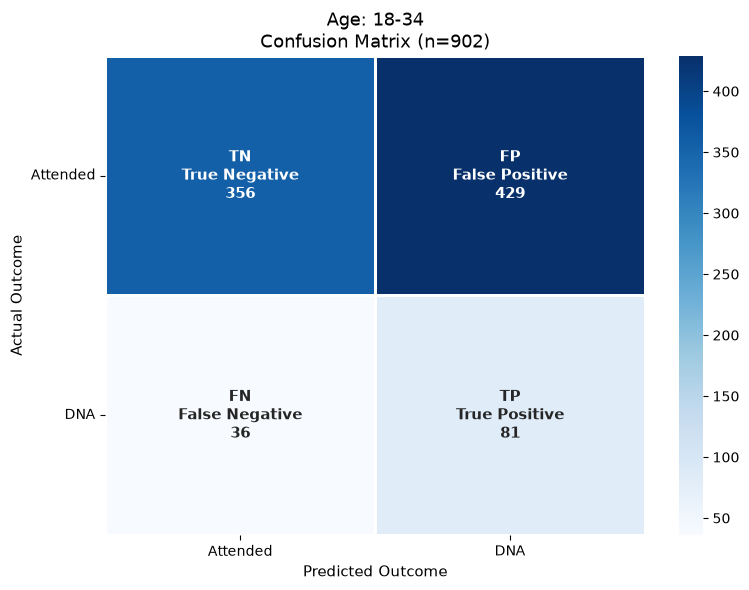

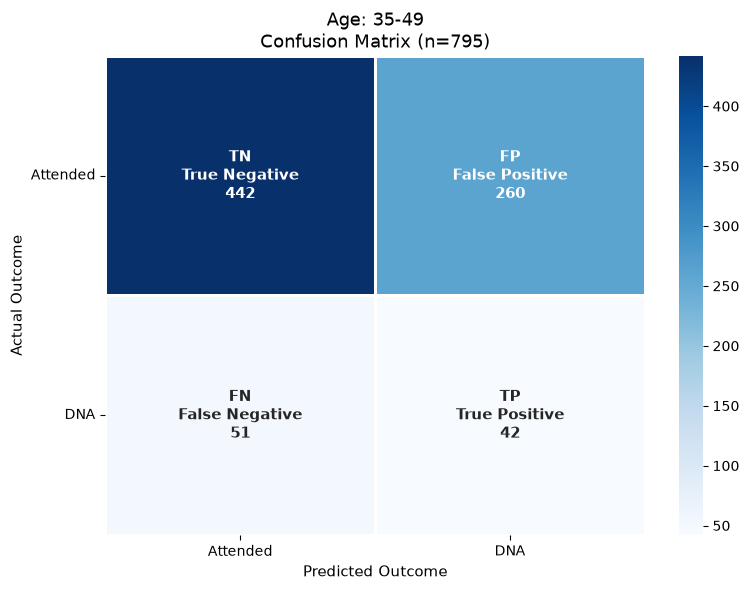

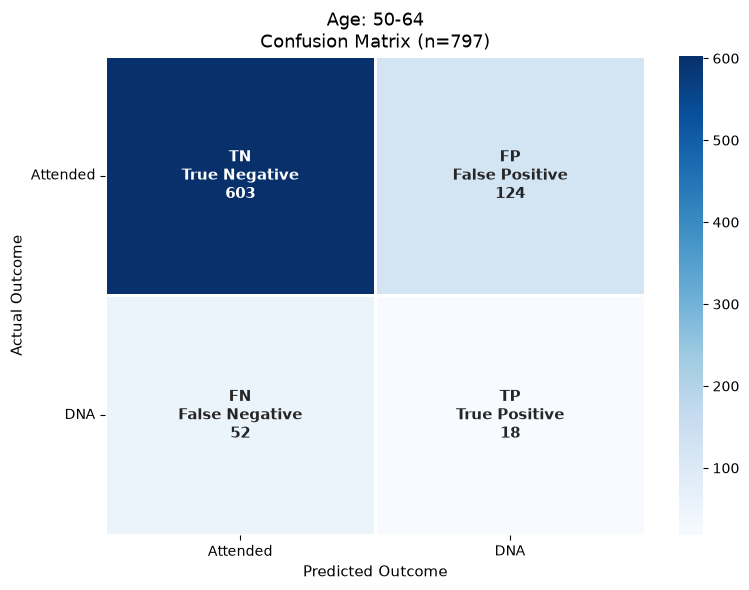

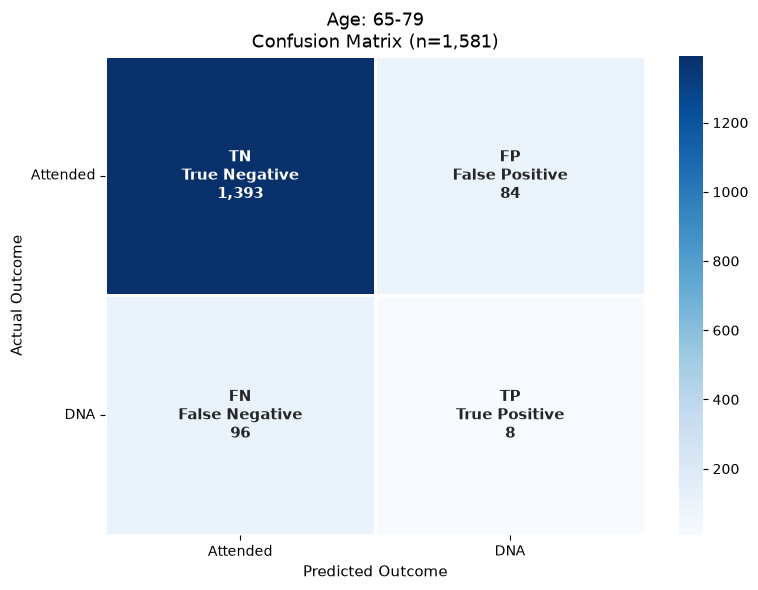

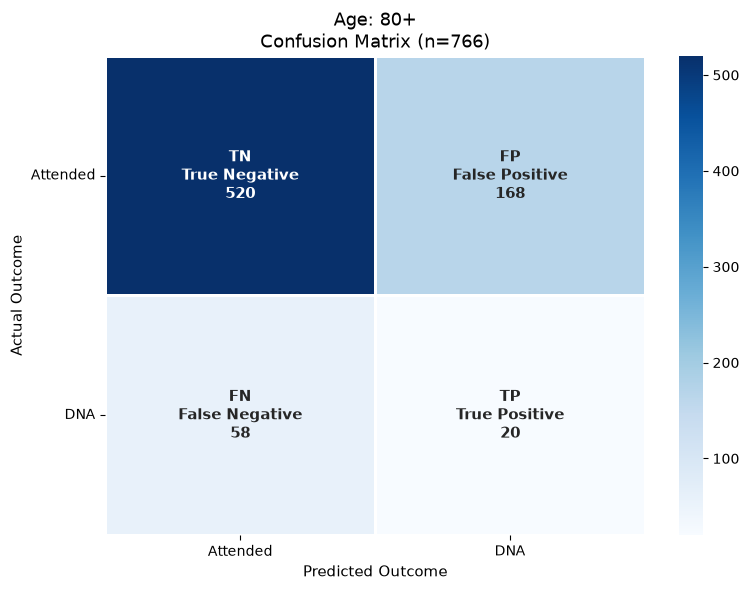

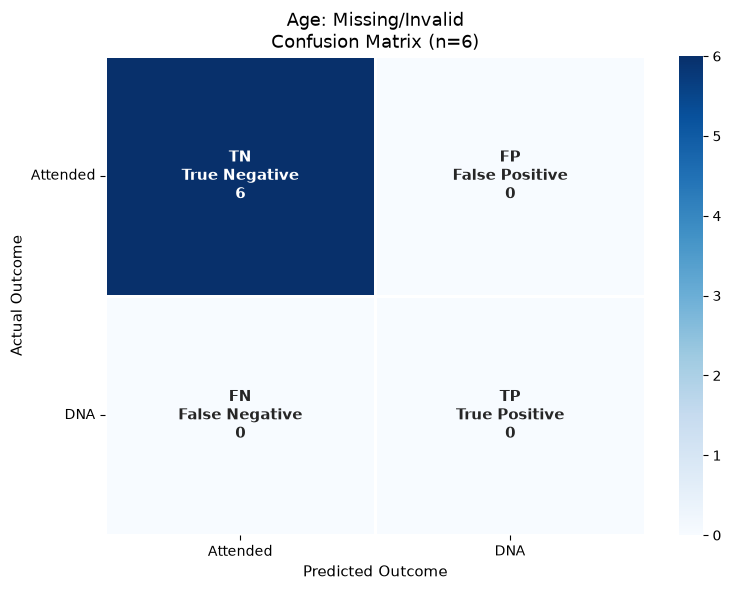

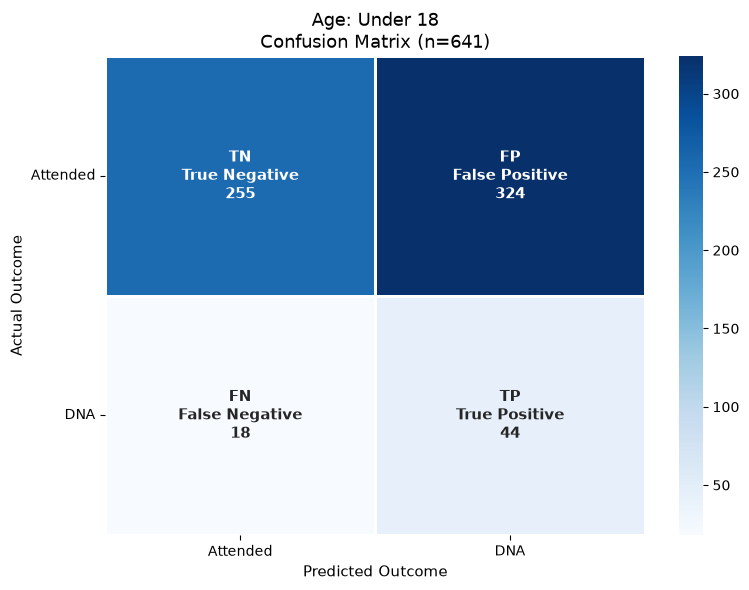

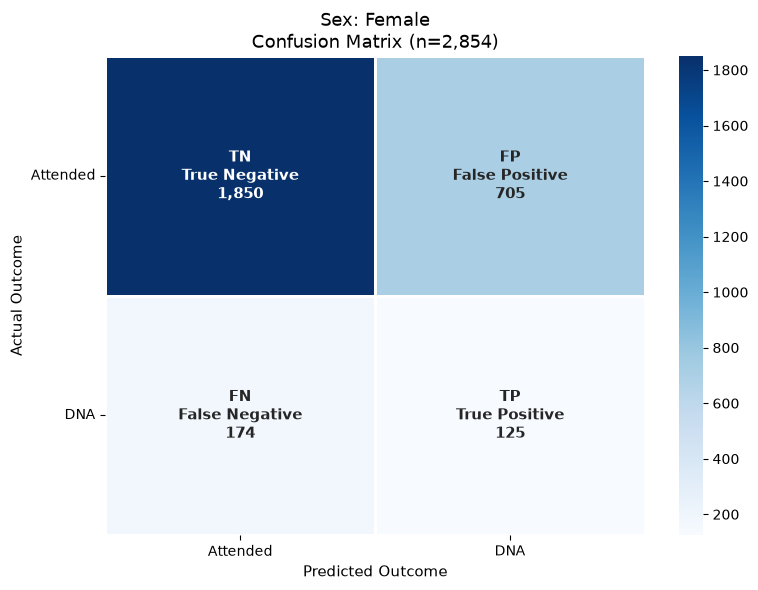

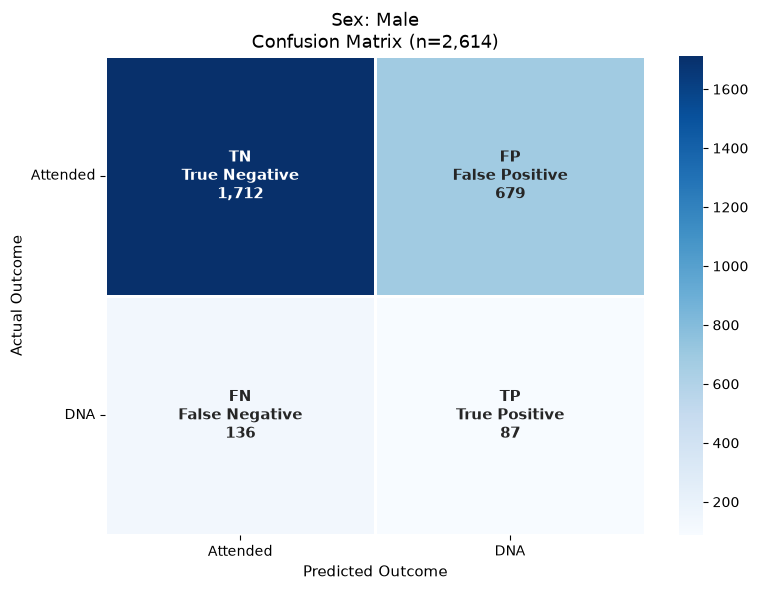

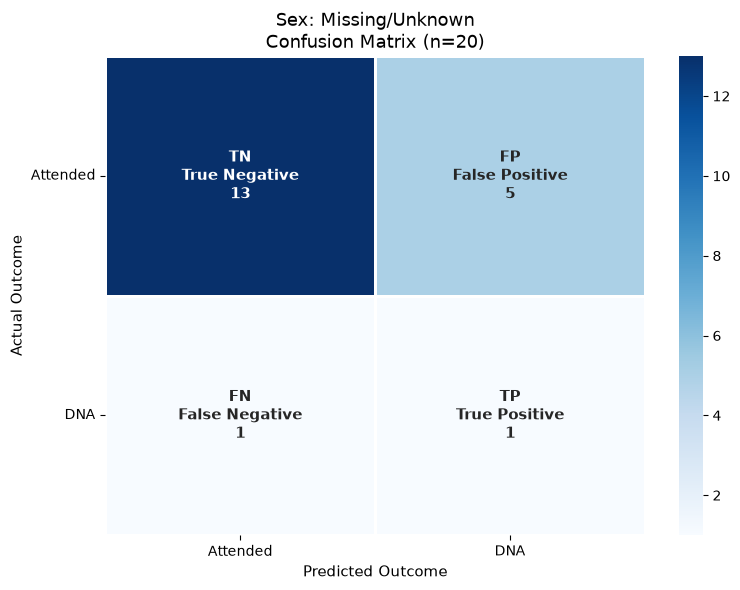

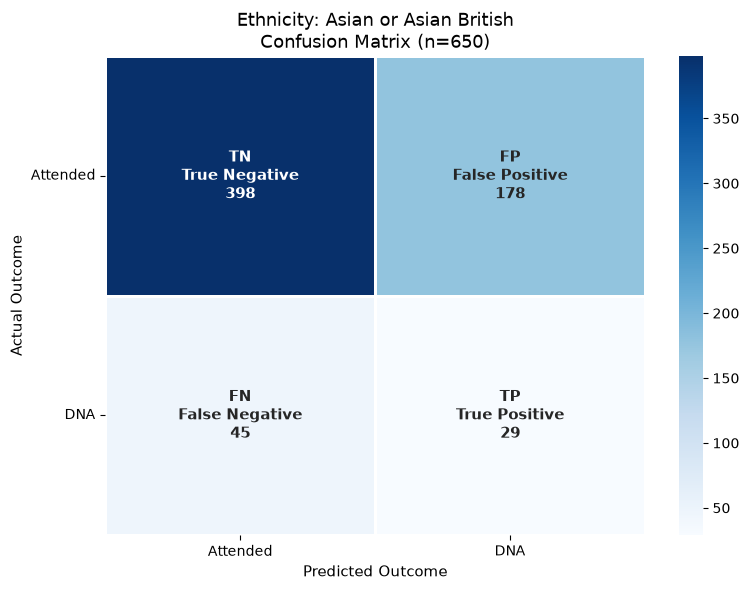

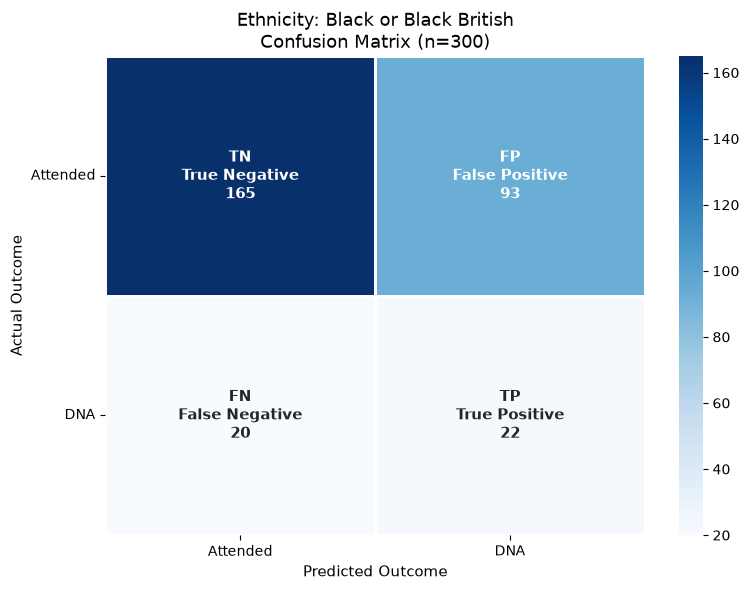

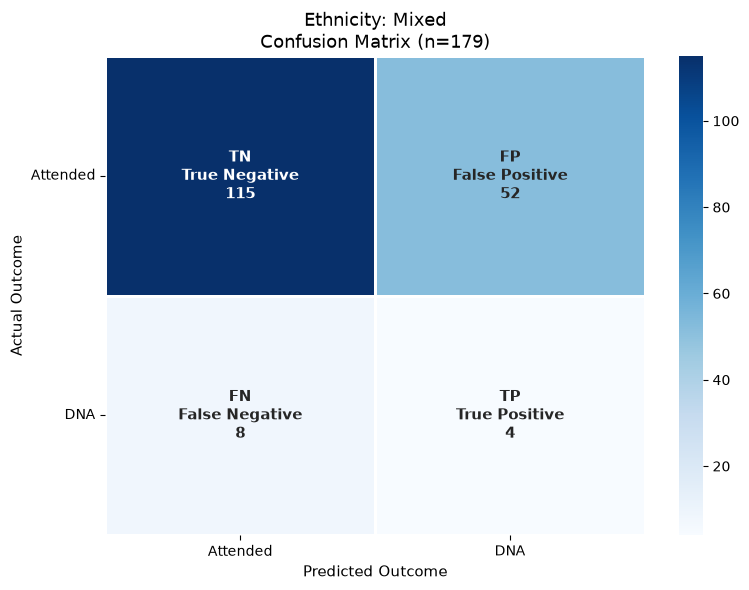

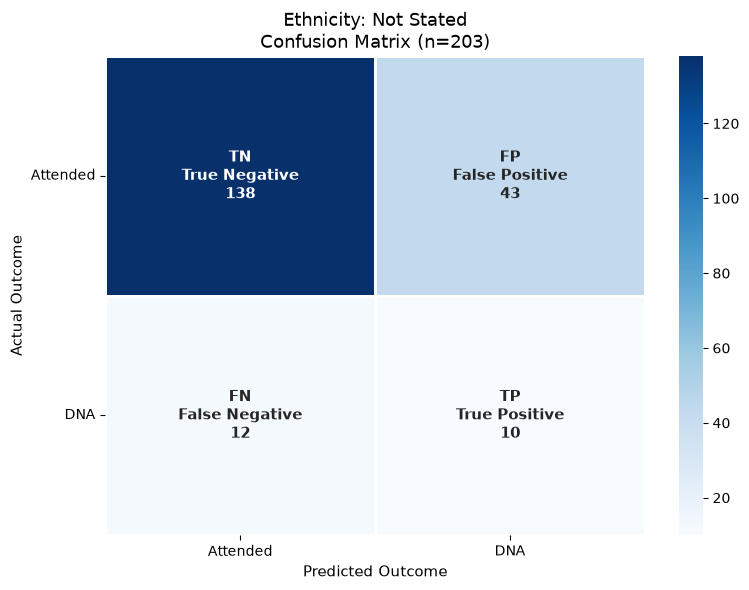

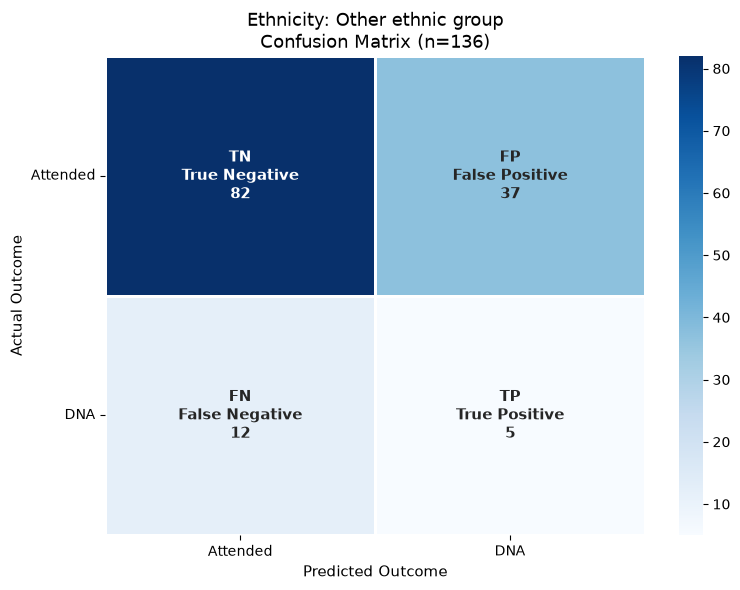

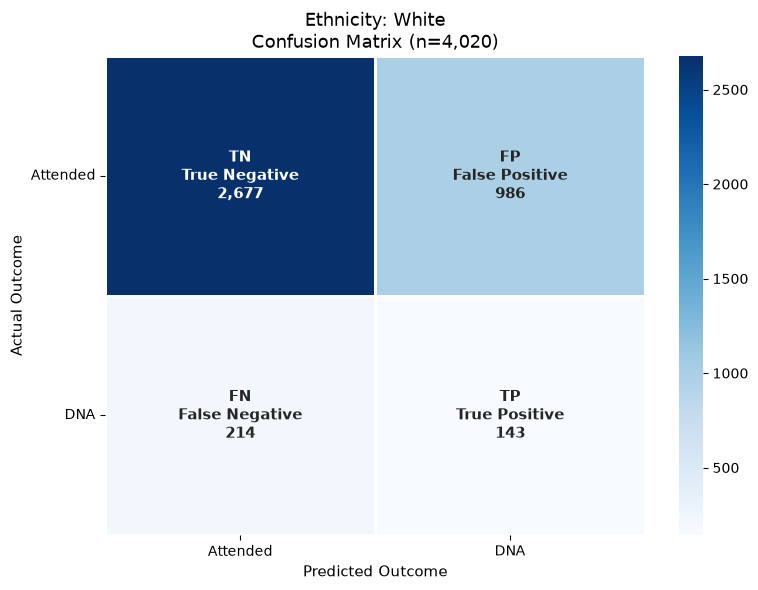

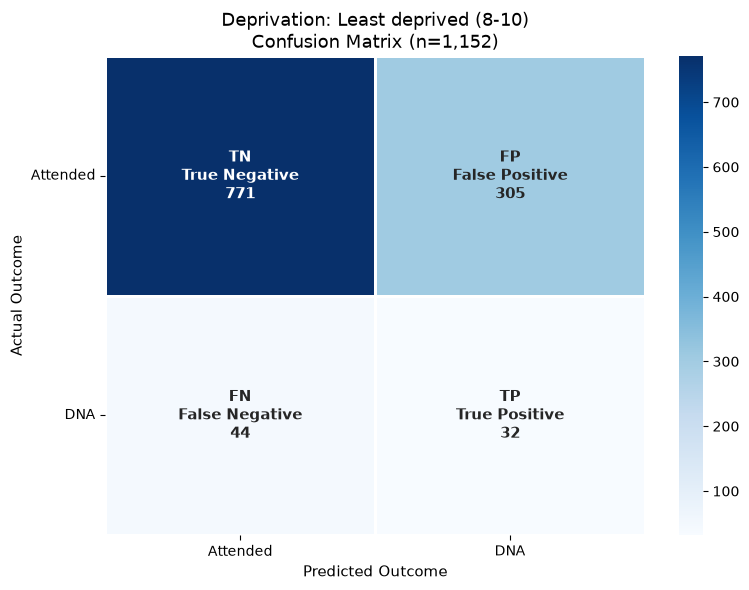

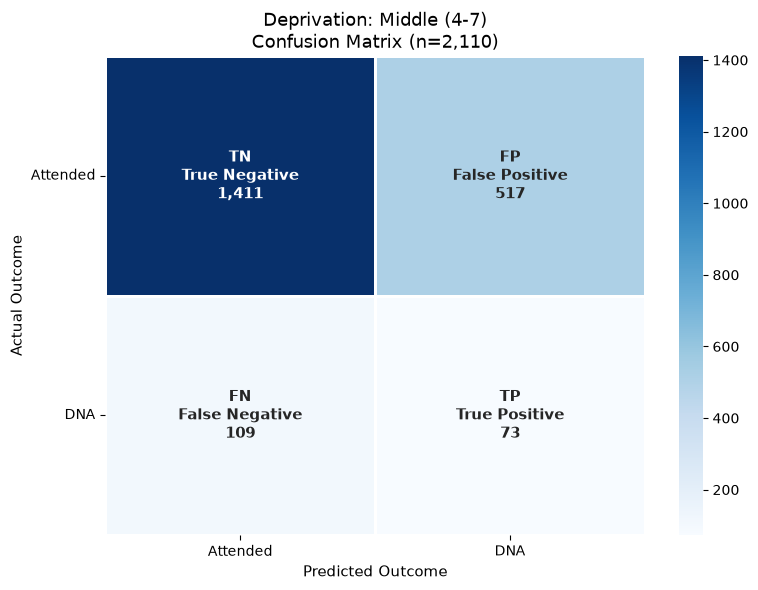

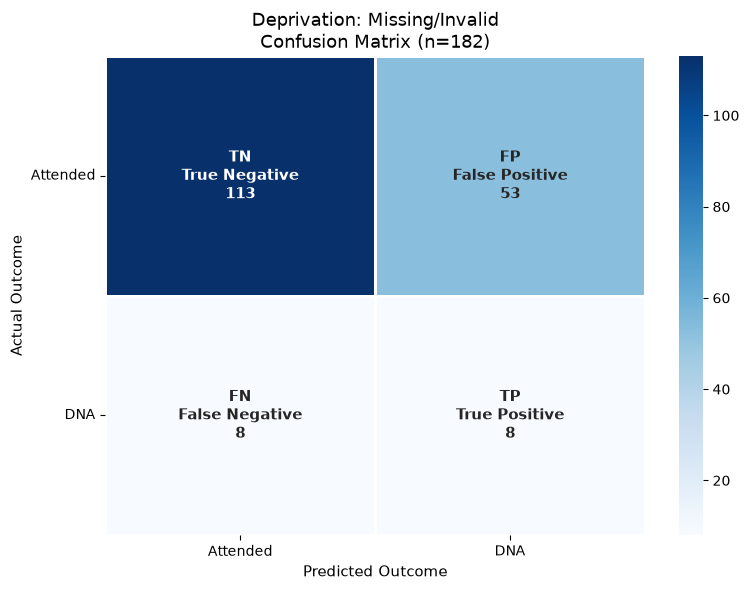

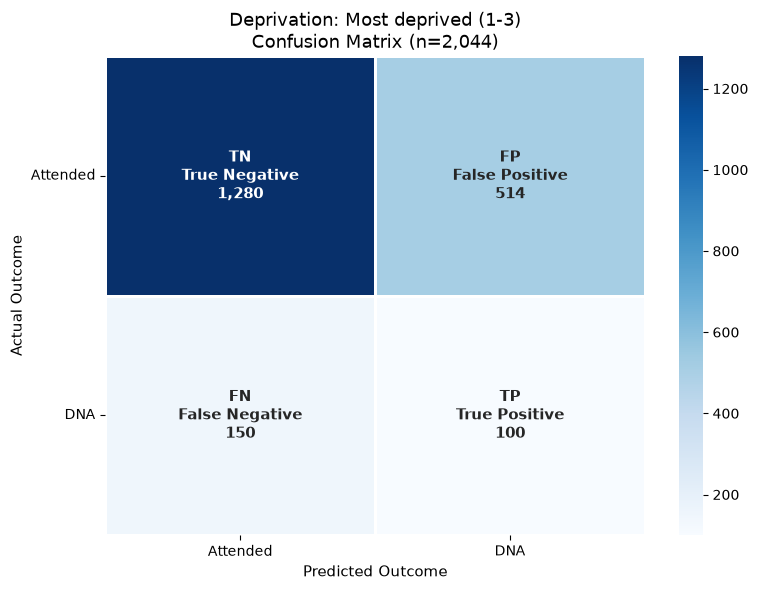


DESCRIPTIVE FAIRNESS GAPS


,characteristic,reliable_groups,recall_gap,false_positive_rate_gap,selection_rate_gap,outreach_dna_recall_gap
0,Age,6,0.6328,0.5027,0.4230,0.5555
1,Deprivation,3,0.0211,0.0184,0.0154,0.0416
2,Ethnicity,4,0.1319,0.1229,0.1147,0.1072
3,Sex,2,0.0279,0.0081,0.0029,0.0193



GROUPS REQUIRING FURTHER REVIEW


,characteristic,group,appointments,actual_dnas,review_reasons
0,Age,18-34,902,117,Higher false-positive rate than comparison group
1,Age,35-49,795,93,Lower recall than comparison group; Lower outr...
2,Age,50-64,797,70,Lower recall than comparison group; Lower outr...
3,Age,65-79,1581,104,Lower recall than comparison group; Lower outr...
4,Age,80+,766,78,Lower recall than comparison group; Lower outr...
5,Age,Missing/Invalid,6,0,Small sample or too few outcome events
6,Age,Under 18,641,62,Higher false-positive rate than comparison group
7,Deprivation,Missing/Invalid,182,16,Small sample or too few outcome events
8,Ethnicity,Asian or Asian British,650,74,Lower recall than comparison group; Lower outr...
9,Ethnicity,Black or Black British,300,42,Higher false-positive rate than comparison group



SUBGROUP PERFORMANCE COMPARISON CHARTS


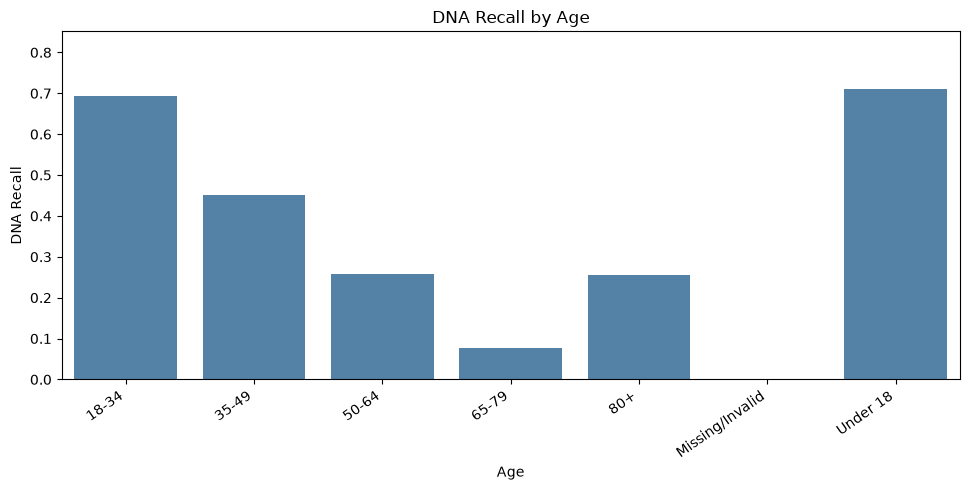

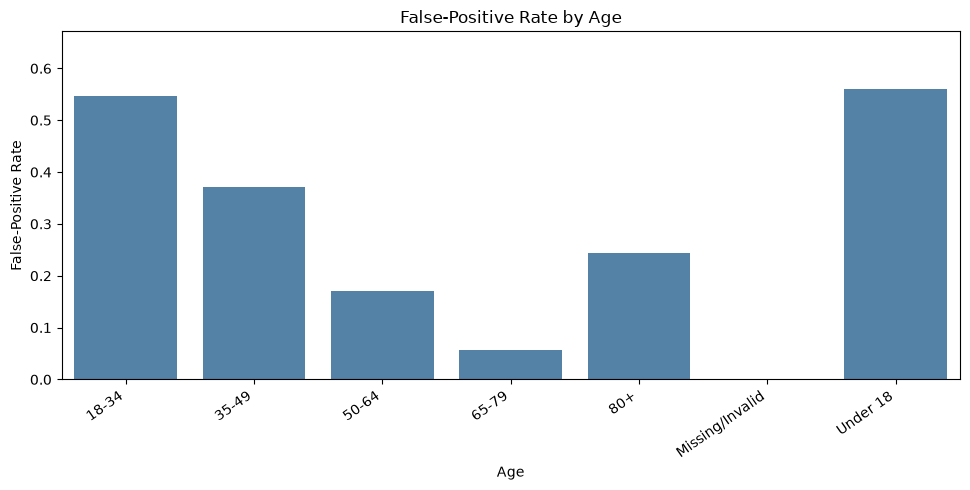

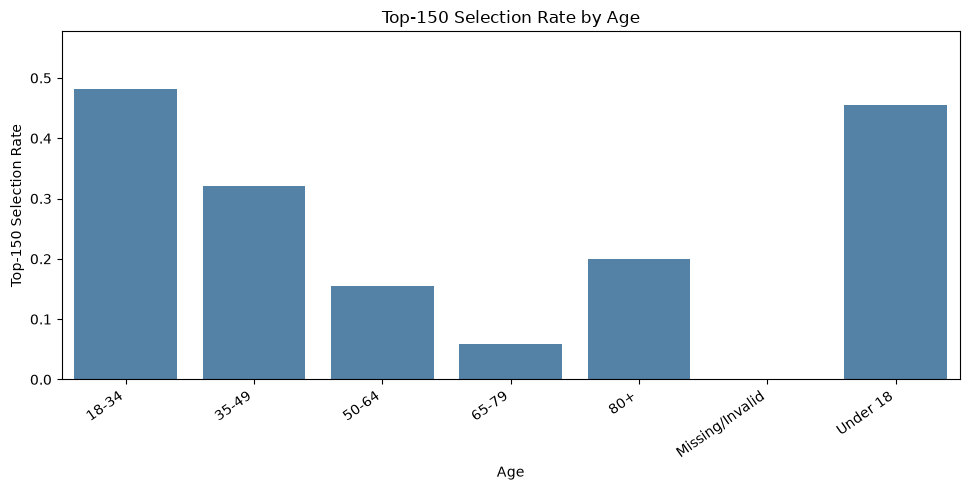

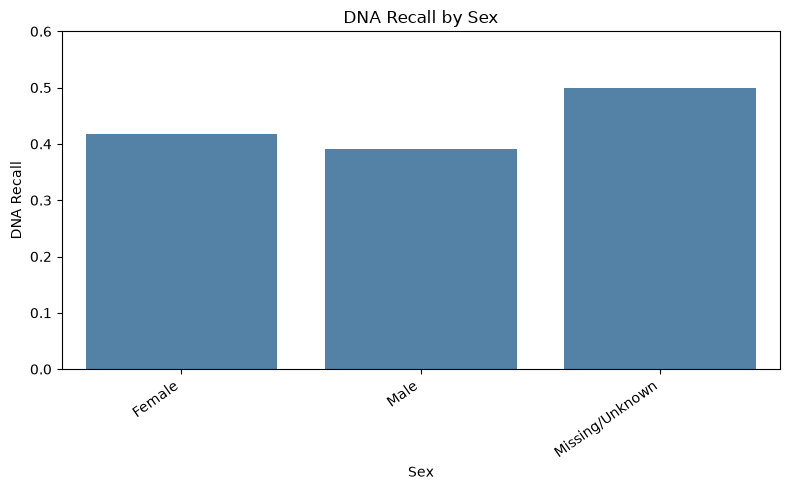

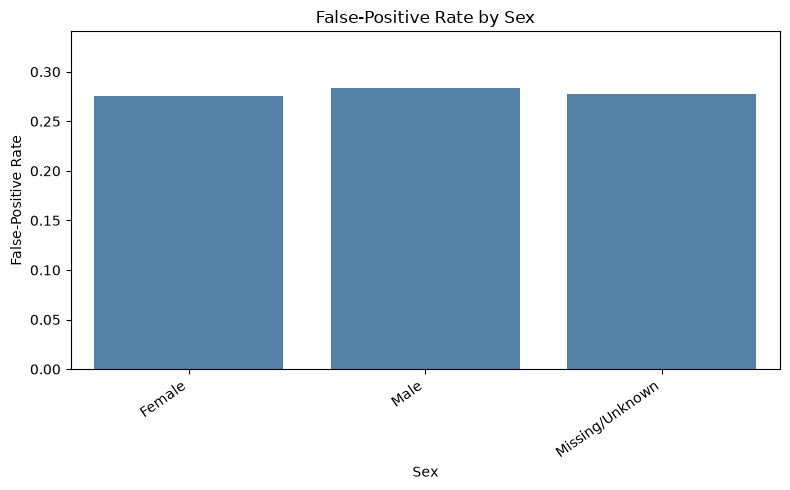

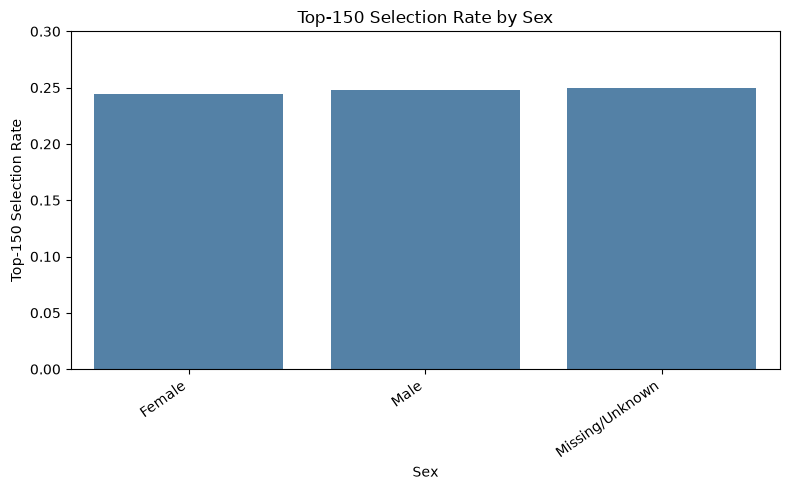

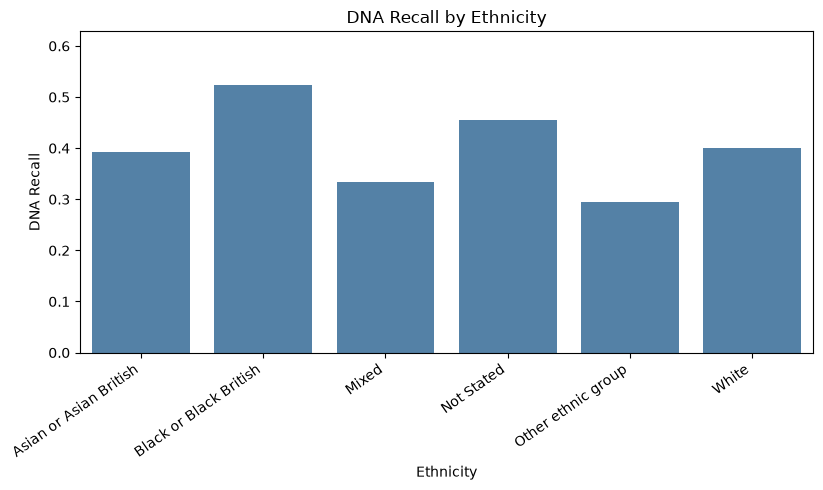

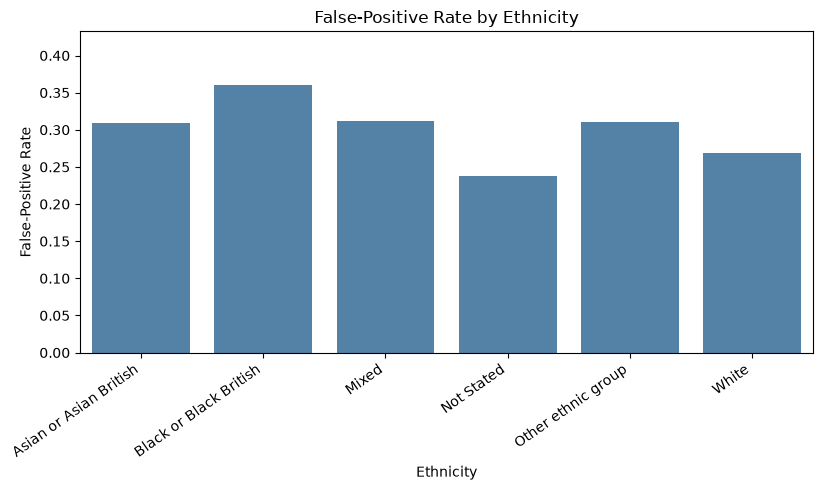

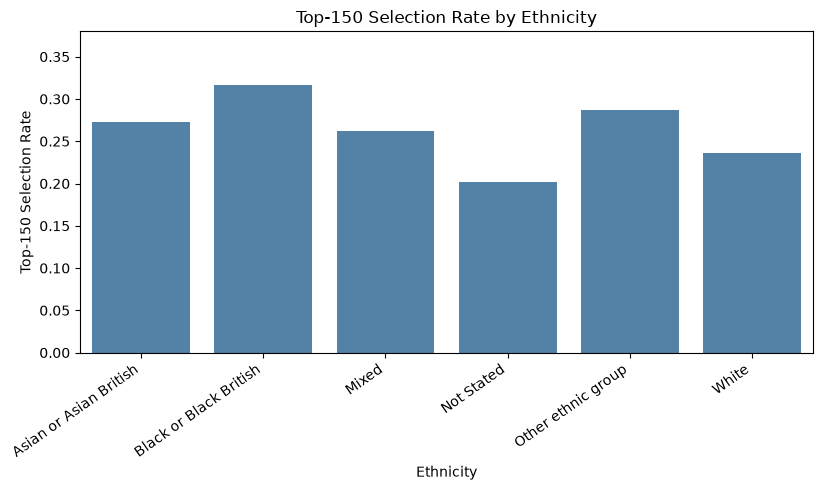

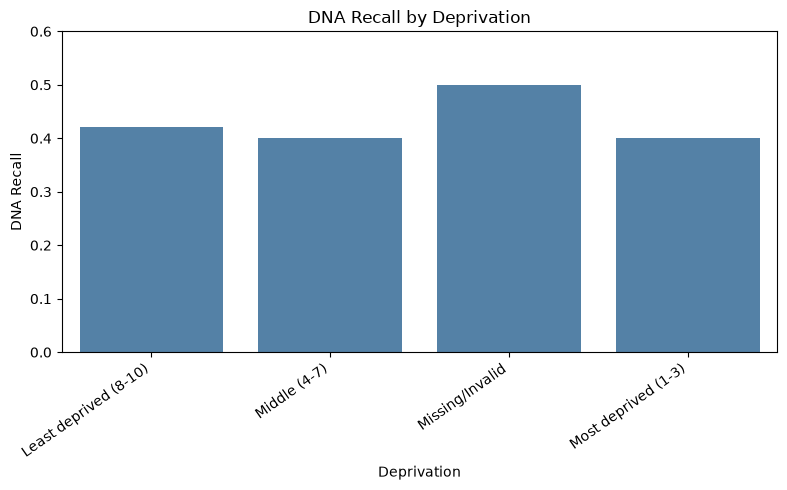

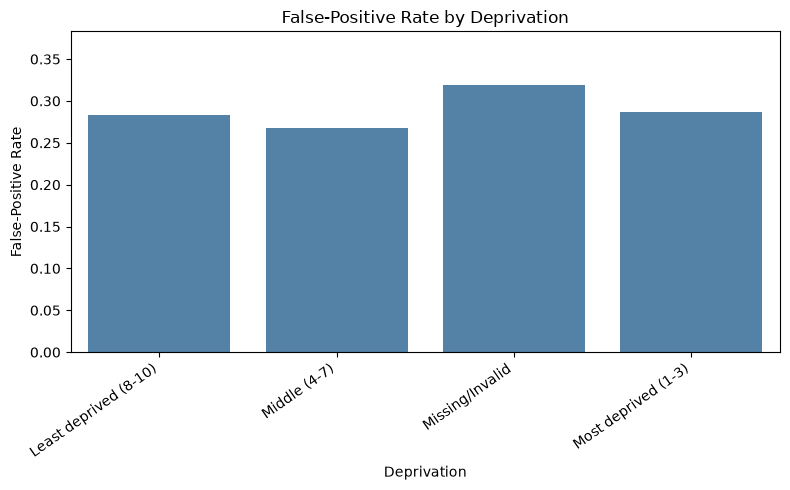

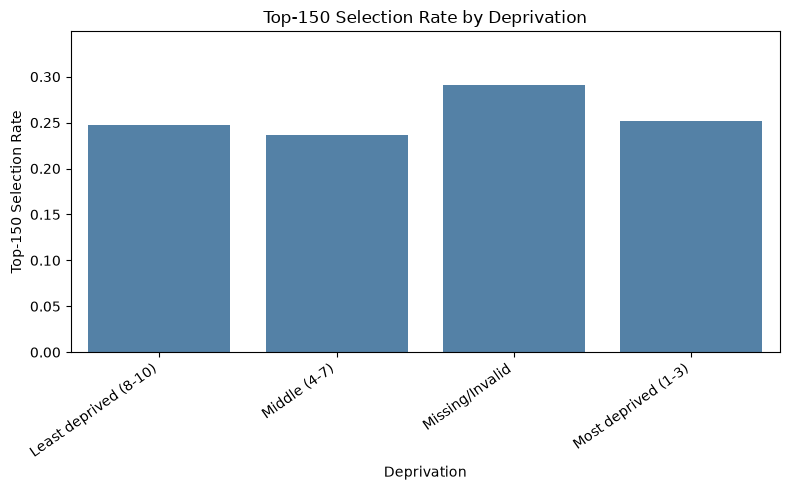


OVERALL CONFUSION MATRIX CHECK
TN: 3575
FP: 1389
FN: 311
TP: 213

SAVING FAIRNESS REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\fairness\cell11_subgroup_fairness_metrics.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\fairness\cell11_fairness_gaps.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\fairness\cell11_fairness_review_flags.csv

CELL 11 COMPLETED SUCCESSFULLY
Selected model: XGBoost - Tuned
Test appointments: 5488
Characteristics assessed: Age, Sex, Ethnicity, Deprivation
Groups assessed: 20
Groups flagged for review: 14
Reports saved to: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\fairness

Interpretation: These results identify possible differences in model performance and outreach selection. They do not establish discrimination or clinical safety.

The top-150 analysis remai

In [37]:

# Cell 11: Fairness and Bias Assessment
# NHS Dorset - Outpatient DNA Prediction

# Objectives:
# 1. Assess fairness across age, sex, ethnicity and deprivation.
# 2. Calculate subgroup precision, recall and other metrics.
# 3. Display confusion matrix heatmaps for demographic groups.
# 4. Compare retrospective weekly top-150 outreach selection.
# 5. Identify performance gaps and small-sample limitations.
# 6. Save charts and reproducible fairness reports.
#
# The selected model and validation threshold remain unchanged.
# This is a test-set fairness audit, not model tuning.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from IPython.display import display

print("CELL 11: FAIRNESS AND BIAS ASSESSMENT")

# Check that previous notebook cells have been executed.

required_objects = [
    "df_test",
    "y_test_array",
    "test_probabilities",
    "selected_thresholds",
    "provisional_model_name",
    "test_selected_appointments",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run previous cells first. Missing: {missing_objects}"
)

# Create a directory for fairness reports and figures.

MODEL_REPORT_DIR = Path(MODEL_REPORT_DIR)

FAIRNESS_REPORT_DIR = MODEL_REPORT_DIR / "fairness"

FAIRNESS_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Use the model already selected on validation data.

fairness_model_name = provisional_model_name

assert fairness_model_name == "XGBoost - Tuned"

fairness_probabilities = np.asarray(
    test_probabilities[fairness_model_name],
    dtype=float
)

fairness_actual = np.asarray(
    y_test_array,
    dtype=int
)

fairness_threshold = float(
    selected_thresholds[fairness_model_name]
)

assert len(df_test) == len(fairness_actual)
assert len(df_test) == len(fairness_probabilities)
assert df_test["appointment_id"].is_unique
assert np.isfinite(fairness_probabilities).all()

print("\nSelected model:", fairness_model_name)
print("Test appointments:", len(df_test))
print("Actual DNAs:", int(fairness_actual.sum()))
print("Classification threshold:", round(fairness_threshold, 4))

# Prepare demographic information for fairness auditing.
#
# Sex, ethnicity and deprivation were excluded from
# the model predictors. Age was retained as a predictor.
#
# All four characteristics can be examined for fairness.

fairness_columns = [
    "appointment_id",
    "age",
    "sex",
    "ethnic_group",
    "imd_decile"
]

missing_columns = [
    column for column in fairness_columns
    if column not in df_test.columns
]

assert not missing_columns, (
    f"Missing fairness columns: {missing_columns}"
)

fairness_df = (
    df_test[fairness_columns]
    .copy()
    .reset_index(drop=True)
)

fairness_df["actual_dna"] = fairness_actual

fairness_df["predicted_probability"] = (
    fairness_probabilities
)

fairness_df["predicted_dna"] = (
    fairness_probabilities >= fairness_threshold
).astype(int)

# Create age groups.
#
# Invalid or missing ages are retained in a separate group.

age_numeric = pd.to_numeric(
    fairness_df["age"],
    errors="coerce"
)

age_numeric = age_numeric.where(
    age_numeric.between(0, 120)
)

fairness_df["age_group"] = pd.cut(
    age_numeric,
    bins=[-1, 17, 34, 49, 64, 79, 120],
    labels=[
        "Under 18",
        "18-34",
        "35-49",
        "50-64",
        "65-79",
        "80+"
    ]
).astype("string")

fairness_df["age_group"] = (
    fairness_df["age_group"]
    .fillna("Missing/Invalid")
)

# Standardize sex and ethnicity labels.
#
# Unknown values remain visible in the fairness results.

for column in ["sex", "ethnic_group"]:

    values = (
        fairness_df[column]
        .astype("string")
        .str.strip()
    )

    missing_labels = [
        "",
        "nan",
        "none",
        "unknown",
        "not known"
    ]

    values = values.mask(
        values.str.lower().isin(missing_labels).fillna(False)
    )

    fairness_df[column] = (
        values.fillna("Missing/Unknown")
    )

# Normalize common recorded sex values.

sex_normalization = {
    "male": "Male",
    "m": "Male",
    "female": "Female",
    "f": "Female"
}

fairness_df["sex"] = (
    fairness_df["sex"]
    .apply(
        lambda value: sex_normalization.get(
            str(value).lower(),
            value
        )
    )
)

# Group Index of Multiple Deprivation deciles.
#
# IMD 1 represents the most deprived areas.
# IMD 10 represents the least deprived areas.
#
# IMD measures area deprivation, not individual income.

imd_numeric = pd.to_numeric(
    fairness_df["imd_decile"],
    errors="coerce"
)

fairness_df["imd_group"] = pd.cut(
    imd_numeric,
    bins=[0, 3, 7, 10],
    labels=[
        "Most deprived (1-3)",
        "Middle (4-7)",
        "Least deprived (8-10)"
    ]
).astype("string")

fairness_df["imd_group"] = (
    fairness_df["imd_group"]
    .fillna("Missing/Invalid")
)

# Reuse the retrospective top-150 appointment selected
# earlier.


assert {
    "model",
    "appointment_id"
}.issubset(test_selected_appointments.columns)

selected_for_model = (
    test_selected_appointments.loc[
        test_selected_appointments["model"]
        == fairness_model_name,
        "appointment_id"
    ]
)

assert selected_for_model.is_unique

fairness_df["selected_top150"] = (
    fairness_df["appointment_id"]
    .isin(selected_for_model)
    .astype(int)
)

assert int(fairness_df["selected_top150"].sum()) == len(
    selected_for_model
)

print("\nFairness audit population prepared.")
print("Appointments:", len(fairness_df))
print(
    "Retrospectively selected appointments:",
    int(fairness_df["selected_top150"].sum())
)

# Define demographic characteristics for comparison.

group_variables = {
    "Age": "age_group",
    "Sex": "sex",
    "Ethnicity": "ethnic_group",
    "Deprivation": "imd_group"
}

# Minimum sample sizes for exploratory fairness assessment.
#


MIN_GROUP_SIZE = 100
MIN_DNA_COUNT = 20
MIN_ATTENDED_COUNT = 20

fairness_rows = []

# Calculate subgroup classification and outreach metrics.

for characteristic, column in group_variables.items():

    grouped = fairness_df.groupby(
        column,
        dropna=False
    )

    for group_name, group in grouped:

        y_true = group["actual_dna"].to_numpy()

        y_pred = group["predicted_dna"].to_numpy()

        y_prob = (
            group["predicted_probability"].to_numpy()
        )

        # Calculate confusion matrix directly from
        # actual outcomes and model predictions.
        #
        # Rows: actual Attended, actual DNA
        # Columns: predicted Attended, predicted DNA

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        appointments = len(group)

        actual_dnas = int(y_true.sum())

        actual_attendances = (
            appointments - actual_dnas
        )

        # Recall: proportion of actual DNAs identified.

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        # Precision: proportion of predicted DNAs
        # that actually missed their appointments.

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        # False-positive rate: proportion of attendances
        # incorrectly classified as DNAs.

        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )

        # Calculate ranking metrics when both
        # outcome classes are present.

        if len(np.unique(y_true)) == 2:

            roc_auc = roc_auc_score(
                y_true,
                y_prob
            )

            pr_auc = average_precision_score(
                y_true,
                y_prob
            )

        else:

            roc_auc = np.nan
            pr_auc = np.nan

        # Calculate retrospective outreach metrics.

        selected_count = int(
            group["selected_top150"].sum()
        )

        selected_actual_dnas = int(
            (
                (group["selected_top150"] == 1)
                & (group["actual_dna"] == 1)
            ).sum()
        )

        selection_rate = (
            selected_count / appointments
            if appointments > 0
            else np.nan
        )

        outreach_precision = (
            selected_actual_dnas / selected_count
            if selected_count > 0
            else np.nan
        )

        outreach_dna_recall = (
            selected_actual_dnas / actual_dnas
            if actual_dnas > 0
            else np.nan
        )

        # Flag groups with limited data.

        small_sample_warning = (
            appointments < MIN_GROUP_SIZE
            or actual_dnas < MIN_DNA_COUNT
            or actual_attendances < MIN_ATTENDED_COUNT
        )

        fairness_rows.append({
            "characteristic": characteristic,
            "group": str(group_name),
            "appointments": appointments,
            "actual_dnas": actual_dnas,
            "actual_attendances": actual_attendances,
            "dna_prevalence": (
                actual_dnas / appointments
            ),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "recall": recall,
            "precision": precision,
            "false_positive_rate": false_positive_rate,
            "specificity": specificity,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc,
            "selected_top150": selected_count,
            "selection_rate": selection_rate,
            "selected_actual_dnas": selected_actual_dnas,
            "outreach_precision": outreach_precision,
            "outreach_dna_recall": outreach_dna_recall,
            "small_sample_warning": small_sample_warning
        })

fairness_results = pd.DataFrame(fairness_rows)

print("\nSUBGROUP FAIRNESS RESULTS")

display(
    fairness_results[
        [
            "characteristic",
            "group",
            "appointments",
            "actual_dnas",
            "dna_prevalence",
            "TN",
            "FP",
            "FN",
            "TP",
            "recall",
            "precision",
            "false_positive_rate",
            "roc_auc",
            "pr_auc",
            "selection_rate",
            "outreach_dna_recall",
            "small_sample_warning"
        ]
    ].round(4)
)

# Create confusion matrix heatmaps for every subgroup.
#
# Each heatmap displays:
# TN = True Negative
# FP = False Positive
# FN = False Negative
# TP = True Positive
#
# Values are calculated from test predictions.
# No confusion matrix counts are hardcoded.

print("\nSUBGROUP CONFUSION MATRIX HEATMAPS")

for characteristic, column in group_variables.items():

    for group_name, group in fairness_df.groupby(
        column,
        dropna=False
    ):

        cm = confusion_matrix(
            group["actual_dna"],
            group["predicted_dna"],
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        heatmap_labels = np.array([
            [
                f"TN\nTrue Negative\n{tn:,}",
                f"FP\nFalse Positive\n{fp:,}"
            ],
            [
                f"FN\nFalse Negative\n{fn:,}",
                f"TP\nTrue Positive\n{tp:,}"
            ]
        ])

        plt.figure(figsize=(8, 6))

        ax = sns.heatmap(
            cm,
            annot=heatmap_labels,
            fmt="",
            cmap="Blues",
            xticklabels=[
                "Attended",
                "DNA"
            ],
            yticklabels=[
                "Attended",
                "DNA"
            ],
            linewidths=2,
            linecolor="white",
            annot_kws={
                "size": 11,
                "weight": "bold"
            },
            cbar=True
        )

        plt.title(
            f"{characteristic}: {group_name}\n"
            f"Confusion Matrix (n={len(group):,})",
            fontsize=13
        )

        plt.xlabel(
            "Predicted Outcome",
            fontsize=11
        )

        plt.ylabel(
            "Actual Outcome",
            fontsize=11
        )

        plt.xticks(rotation=0)
        plt.yticks(rotation=0)

        plt.tight_layout()

        # Save each heatmap with a safe, unique filename.

        group_slug = "".join(
            char.lower() if char.isalnum() else "_"
            for char in str(group_name)
        ).strip("_")

        figure_path = (
            FAIRNESS_REPORT_DIR
            / (
                f"cell11_confusion_matrix_"
                f"{characteristic.lower()}_"
                f"{group_slug}.png"
            )
        )

        plt.savefig(
            figure_path,
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# Calculate descriptive fairness gaps.
#
# Compare the highest and lowest metric values
# among groups with adequate sample sizes.
#
# These differences do not establish discrimination.

gap_metrics = [
    "recall",
    "false_positive_rate",
    "selection_rate",
    "outreach_dna_recall"
]

fairness_gap_rows = []

for characteristic, group in fairness_results.groupby(
    "characteristic"
):

    reliable = group.loc[
        ~group["small_sample_warning"]
    ]

    gap_row = {
        "characteristic": characteristic,
        "reliable_groups": len(reliable)
    }

    for metric in gap_metrics:

        values = reliable[metric].dropna()

        gap_row[f"{metric}_gap"] = (
            float(values.max() - values.min())
            if len(values) >= 2
            else np.nan
        )

    fairness_gap_rows.append(gap_row)

fairness_gaps = pd.DataFrame(
    fairness_gap_rows
)

print("\nDESCRIPTIVE FAIRNESS GAPS")

display(fairness_gaps.round(4))

# Identify groups requiring additional investigation.


REVIEW_GAP = 0.10

review_rows = []

for characteristic, group in fairness_results.groupby(
    "characteristic"
):

    reliable = group.loc[
        ~group["small_sample_warning"]
    ]

    for _, row in group.iterrows():

        reasons = []

        if row["small_sample_warning"]:

            reasons.append(
                "Small sample or too few outcome events"
            )

        elif len(reliable) >= 2:

            for metric in [
                "recall",
                "outreach_dna_recall"
            ]:

                values = reliable[metric].dropna()

                if (
                    len(values) >= 2
                    and pd.notna(row[metric])
                    and (
                        values.max() - row[metric]
                    ) >= REVIEW_GAP
                ):

                    reasons.append(
                        f"Lower {metric} than comparison group"
                    )

            fpr_values = (
                reliable["false_positive_rate"].dropna()
            )

            if (
                len(fpr_values) >= 2
                and pd.notna(row["false_positive_rate"])
                and (
                    row["false_positive_rate"]
                    - fpr_values.min()
                ) >= REVIEW_GAP
            ):

                reasons.append(
                    "Higher false-positive rate "
                    "than comparison group"
                )

        if reasons:

            review_rows.append({
                "characteristic": characteristic,
                "group": row["group"],
                "appointments": row["appointments"],
                "actual_dnas": row["actual_dnas"],
                "review_reasons": "; ".join(reasons)
            })

fairness_review_flags = pd.DataFrame(
    review_rows,
    columns=[
        "characteristic",
        "group",
        "appointments",
        "actual_dnas",
        "review_reasons"
    ]
)

print("\nGROUPS REQUIRING FURTHER REVIEW")

if fairness_review_flags.empty:

    print(
        "No groups met the exploratory screening criteria. "
        "This does not prove the model is fair."
    )

else:

    display(fairness_review_flags)

# Create bar charts to compare subgroup performance.
#
# Heatmaps show raw confusion matrix counts.
# Bar charts allow easier comparison of group-level rates.
#
# for useful for fairness interpretation.

plot_metrics = {
    "recall": "DNA Recall",
    "false_positive_rate": "False-Positive Rate",
    "selection_rate": "Top-150 Selection Rate"
}

print("\nSUBGROUP PERFORMANCE COMPARISON CHARTS")

for characteristic in group_variables:

    plot_data = fairness_results.loc[
        fairness_results["characteristic"] == characteristic
    ].copy()

    for metric, metric_label in plot_metrics.items():

        plt.figure(
            figsize=(
                max(8, len(plot_data) * 1.4),
                5
            )
        )

        sns.barplot(
            data=plot_data,
            x="group",
            y=metric,
            color="steelblue"
        )

        maximum_value = plot_data[metric].max()

        upper_limit = (
            max(
                0.05,
                min(1.0, maximum_value * 1.2)
            )
            if pd.notna(maximum_value)
            else 1.0
        )

        plt.ylim(0, upper_limit)

        plt.title(
            f"{metric_label} by {characteristic}"
        )

        plt.xlabel(characteristic)
        plt.ylabel(metric_label)

        plt.xticks(
            rotation=35,
            ha="right"
        )

        plt.tight_layout()

        figure_path = (
            FAIRNESS_REPORT_DIR
            / (
                f"cell11_{metric}_"
                f"{characteristic.lower()}.png"
            )
        )

        plt.savefig(
            figure_path,
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# Validate fairness results against the overall test data.
#


overall_cm = confusion_matrix(
    fairness_actual,
    fairness_df["predicted_dna"],
    labels=[0, 1]
)

overall_tn, overall_fp, overall_fn, overall_tp = (
    overall_cm.ravel()
)

for characteristic in group_variables:

    group = fairness_results.loc[
        fairness_results["characteristic"] == characteristic
    ]

    assert int(group["appointments"].sum()) == len(
        fairness_df
    )

    assert int(group["actual_dnas"].sum()) == int(
        fairness_actual.sum()
    )

    assert int(group["TN"].sum()) == int(overall_tn)
    assert int(group["FP"].sum()) == int(overall_fp)
    assert int(group["FN"].sum()) == int(overall_fn)
    assert int(group["TP"].sum()) == int(overall_tp)

    assert int(group["selected_top150"].sum()) == int(
        fairness_df["selected_top150"].sum()
    )

print("\nOVERALL CONFUSION MATRIX CHECK")

print("TN:", int(overall_tn))
print("FP:", int(overall_fp))
print("FN:", int(overall_fn))
print("TP:", int(overall_tp))

# Save aggregate fairness reports.


fairness_reports = {
    "cell11_subgroup_fairness_metrics.csv":
        fairness_results,
    "cell11_fairness_gaps.csv":
        fairness_gaps,
    "cell11_fairness_review_flags.csv":
        fairness_review_flags
}

print("\nSAVING FAIRNESS REPORTS")

for filename, report in fairness_reports.items():

    output_path = FAIRNESS_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Summarize the fairness assessment.

print("\nCELL 11 COMPLETED SUCCESSFULLY")

print("Selected model:", fairness_model_name)

print(
    "Test appointments:",
    len(fairness_df)
)

print(
    "Characteristics assessed:",
    ", ".join(group_variables.keys())
)

print(
    "Groups assessed:",
    len(fairness_results)
)

print(
    "Groups flagged for review:",
    len(fairness_review_flags)
)

print(
    "Reports saved to:",
    FAIRNESS_REPORT_DIR
)

print(
    "\nInterpretation: These results identify possible "
    "differences in model performance and outreach selection. "
    "They do not establish discrimination or clinical safety."
)

print(
    "\nThe top-150 analysis remains retrospective and "
    "appointment-based. The next Cell will simulate weekly "
    "selection of up to 150 unique eligible patients."
)

print(
    "\nNo model retraining, model reselection "
    "or threshold adjustment was performed."
)


CELL 12: WEEKLY PATIENT CALLING STRATEGY

Selected model: XGBoost - Tuned
Weekly calling capacity: 150
Calling schedule: Monday at 09:00

OPERATIONAL ELIGIBILITY SUMMARY


,criterion,appointments
0,All test appointments,5488
1,Booked by Monday 09:00,5417
2,Prediction cutoff by Monday 09:00,5417
3,Appointment still upcoming,5212
4,Valid patient identifier,5488
5,Eligible appointments,5141



WEEKLY CALLING LIST CREATED
Eligible appointments: 5141
Unique patient-week candidates: 5024
Total selected patient-week entries: 1350

WEEKLY OUTREACH PERFORMANCE


,appointment_week,eligible_patients,eligible_dnas,patients_selected,selected_actual_dnas,precision_at_150,recall_at_150,random_baseline_dna_rate,expected_random_dnas,lift_vs_random
0,2026-02-02,201,21,150,17,0.1133,0.8095,0.1045,15.67,1.0848
1,2026-02-09,631,70,150,29,0.1933,0.4143,0.1109,16.64,1.7428
2,2026-02-16,611,57,150,26,0.1733,0.4561,0.0933,13.99,1.8580
3,2026-02-23,648,49,150,16,0.1067,0.3265,0.0756,11.34,1.4106
4,2026-03-02,681,56,150,22,0.1467,0.3929,0.0822,12.33,1.7836
5,2026-03-09,622,59,150,17,0.1133,0.2881,0.0949,14.23,1.1948
6,2026-03-16,633,51,150,17,0.1133,0.3333,0.0806,12.09,1.4067
7,2026-03-23,624,65,150,15,0.1000,0.2308,0.1042,15.62,0.9600
8,2026-03-30,373,39,150,16,0.1067,0.4103,0.1046,15.68,1.0202



OVERALL OUTREACH PERFORMANCE


,weeks_evaluated,eligible_patient_week_candidates,patients_selected,actual_dnas_among_selected,precision_at_150,recall_at_150,expected_random_dnas,lift_vs_random
0,9,5024,1350,175,0.1296,0.3747,127.605,1.3714



POSSIBLE PARTIAL TEST WEEKS


,appointment_week,eligible_patients,patients_selected,possible_partial_week
0,2026-02-02,201,150,True
8,2026-03-30,373,150,True



ILLUSTRATIVE PREVENTION SCENARIOS


,scenario,contact_rate,intervention_effectiveness,estimated_dnas_prevented,estimated_prevented_per_week
0,Conservative,0.50,0.1,8.75,0.97
1,Central,0.70,0.2,24.50,2.72
2,Optimistic,0.85,0.3,44.62,4.96


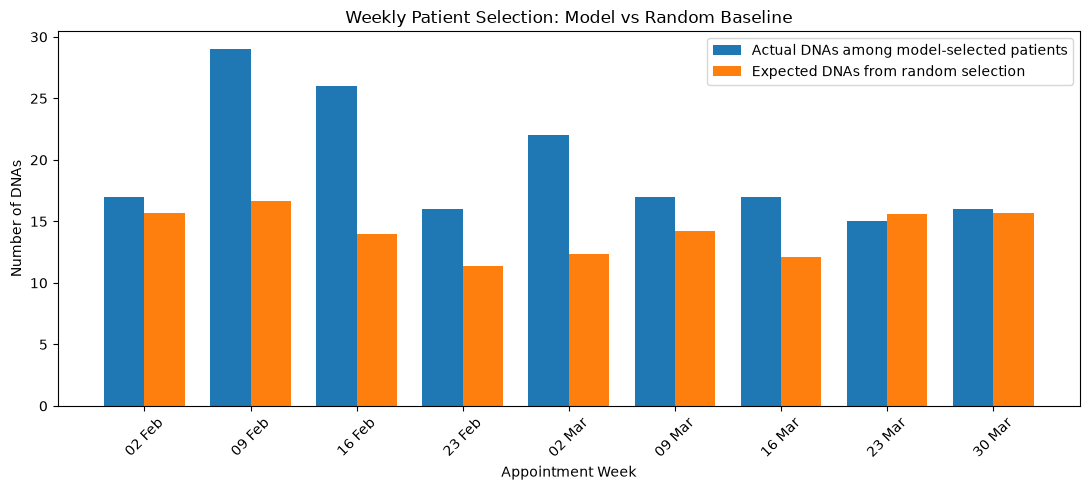

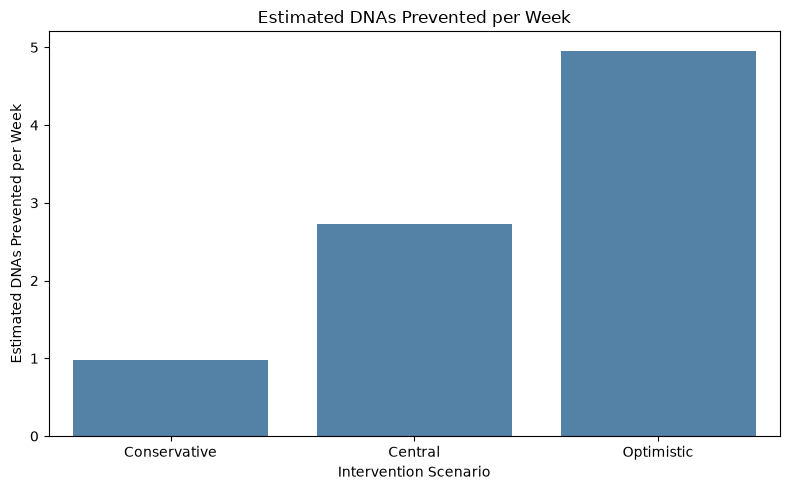


SAVING OPERATIONAL REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\weekly_outreach\cell12_eligibility_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\weekly_outreach\cell12_weekly_calling_list.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\weekly_outreach\cell12_weekly_outreach_results.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\weekly_outreach\cell12_overall_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\weekly_outreach\cell12_intervention_scenarios.csv

CELL 12 COMPLETED
Selected model: XGBoost - Tuned
Weeks evaluated: 9
Patients selected: 1350
Actual DNAs among selected appointments: 175
Overall Precision@150: 0.1296
Overall Recall@150: 0.3747
Lift versus random: 1.3714

These results measure retrospective

In [38]:

# Cell 12: Weekly Patient Calling Strategy
# NHS Dorset - Outpatient DNA Prediction

# Objectives:
# 1. Simulate weekly patient selection using existing model predictions.
# 2. Check booking, prediction and appointment eligibility.
# 3. Select up to 150 unique patients per appointment week.
# 4. Evaluate Precision@150, Recall@150 and lift over random selection.
# 5. Estimate DNAs potentially prevented under explicit assumptions.
# 6. Save evaluation reports and figures.
#
# This is a retrospective test-set simulation.
# No model retraining, reselection or threshold tuning occurs.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

print("CELL 12: WEEKLY PATIENT CALLING STRATEGY")

# Verify that the required outputs from earlier cells exist.

required_objects = [
    "df_test",
    "y_test_array",
    "test_probabilities",
    "provisional_model_name",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run the earlier notebook cells first: {missing_objects}"
)

# Create the output directory.

OUTREACH_REPORT_DIR = (
    Path(MODEL_REPORT_DIR) / "weekly_outreach"
)

OUTREACH_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Define the assumed weekly calling schedule.
#
# Monday at 09:00 is the list-generation time.
# The list covers appointments after Monday 09:00
# and before the following Monday.
#

WEEKLY_CALL_CAPACITY = 150
CALLING_HOUR = 9

selected_model_name = provisional_model_name

assert selected_model_name in test_probabilities, (
    "Selected model probabilities are unavailable."
)

print("\nSelected model:", selected_model_name)
print("Weekly calling capacity:", WEEKLY_CALL_CAPACITY)
print("Calling schedule: Monday at 09:00")

# Check the required source columns.

required_columns = [
    "appointment_id",
    "patient_id",
    "appointment_datetime",
    "booked_datetime",
    "prediction_cutoff_datetime"
]

missing_columns = [
    column for column in required_columns
    if column not in df_test.columns
]

assert not missing_columns, (
    f"Missing operational columns: {missing_columns}"
)

# Reuse the predictions and outcomes from the test set.
#
# Actual outcomes are used only for retrospective
# evaluation, never for patient selection.

risk_probabilities = np.asarray(
    test_probabilities[selected_model_name],
    dtype=float
).reshape(-1)

actual_outcomes = np.asarray(
    y_test_array,
    dtype=int
).reshape(-1)

assert len(df_test) == len(risk_probabilities)
assert len(df_test) == len(actual_outcomes)

assert np.isfinite(risk_probabilities).all()

assert (
    (risk_probabilities >= 0)
    & (risk_probabilities <= 1)
).all()

assert np.isin(actual_outcomes, [0, 1]).all()

# Construct the evaluation dataset.


outreach_df = (
    df_test[required_columns]
    .copy()
    .reset_index(drop=True)
)

outreach_df["predicted_dna_probability"] = (
    risk_probabilities
)

outreach_df["actual_dna"] = actual_outcomes

# Convert the three timestamp columns.

date_columns = [
    "appointment_datetime",
    "booked_datetime",
    "prediction_cutoff_datetime"
]

for column in date_columns:

    outreach_df[column] = pd.to_datetime(
        outreach_df[column],
        errors="coerce"
    )

assert outreach_df[date_columns].notna().all().all(), (
    "Some required operational timestamps are missing."
)

assert outreach_df["appointment_id"].notna().all()

assert outreach_df["appointment_id"].is_unique, (
    "Appointment IDs must be unique."
)

# Calculate the Monday associated with each appointment.
#


outreach_df["appointment_week"] = (
    outreach_df["appointment_datetime"].dt.normalize()
    - pd.to_timedelta(
        outreach_df[
            "appointment_datetime"
        ].dt.day_of_week,
        unit="D"
    )
)

# Generate the assumed Monday 09:00 calling timestamp.

outreach_df["calling_datetime"] = (
    outreach_df["appointment_week"]
    + pd.Timedelta(hours=CALLING_HOUR)
)

# Define operational eligibility.


outreach_df["booked_in_time"] = (
    outreach_df["booked_datetime"]
    <= outreach_df["calling_datetime"]
)

outreach_df["prediction_available"] = (
    outreach_df["prediction_cutoff_datetime"]
    <= outreach_df["calling_datetime"]
)

outreach_df["appointment_still_upcoming"] = (
    outreach_df["appointment_datetime"]
    > outreach_df["calling_datetime"]
)

# Standardize patient identifiers for duplicate checking.

patient_ids = (
    outreach_df["patient_id"]
    .astype("string")
    .str.strip()
)

invalid_patient_values = [
    "",
    "nan",
    "none",
    "null"
]

outreach_df["valid_patient_id"] = (
    patient_ids.notna()
    & patient_ids.ne("").fillna(False)
    & ~patient_ids.str.lower().isin(
        invalid_patient_values
    ).fillna(False)
)

outreach_df["patient_id"] = patient_ids

outreach_df["operationally_eligible"] = (
    outreach_df["booked_in_time"]
    & outreach_df["prediction_available"]
    & outreach_df["appointment_still_upcoming"]
    & outreach_df["valid_patient_id"]
)

# Display an eligibility summary.


eligibility_summary = pd.DataFrame({
    "criterion": [
        "All test appointments",
        "Booked by Monday 09:00",
        "Prediction cutoff by Monday 09:00",
        "Appointment still upcoming",
        "Valid patient identifier",
        "Eligible appointments"
    ],
    "appointments": [
        len(outreach_df),
        int(outreach_df["booked_in_time"].sum()),
        int(outreach_df["prediction_available"].sum()),
        int(
            outreach_df[
                "appointment_still_upcoming"
            ].sum()
        ),
        int(outreach_df["valid_patient_id"].sum()),
        int(
            outreach_df[
                "operationally_eligible"
            ].sum()
        )
    ]
})

print("\nOPERATIONAL ELIGIBILITY SUMMARY")

display(eligibility_summary)

# Keep only eligible appointments.

eligible_df = outreach_df.loc[
    outreach_df["operationally_eligible"]
].copy()

assert not eligible_df.empty, (
    "No eligible appointments were found. "
    "Review the calling-time and prediction-cutoff assumptions."
)

# Rank eligible appointments by predicted DNA risk.
#
# Highest predicted probability receives highest priority.
# Ties are resolved by appointment time and appointment ID.


eligible_df = eligible_df.sort_values(
    by=[
        "appointment_week",
        "predicted_dna_probability",
        "appointment_datetime",
        "appointment_id"
    ],
    ascending=[
        True,
        False,
        True,
        True
    ],
    kind="stable"
)

# A patient can have more than one appointment.
#
# Retain only their highest-risk eligible appointment
# within each week, ensuring one calling-list entry
# per patient per week.
#
# The evaluation counts only that representative
# appointment, not all appointments for the patient.

unique_patient_candidates = (
    eligible_df
    .drop_duplicates(
        subset=[
            "appointment_week",
            "patient_id"
        ],
        keep="first"
    )
    .copy()
)

# Select the top 150 unique patients per week.
#
# If fewer than 150 eligible patients exist,
# select only those available.

weekly_calling_list = (
    unique_patient_candidates
    .groupby(
        "appointment_week",
        group_keys=False
    )
    .head(WEEKLY_CALL_CAPACITY)
    .copy()
)

weekly_calling_list["selection_rank"] = (
    weekly_calling_list
    .groupby("appointment_week")
    .cumcount()
    .add(1)
)

# Validate the selection rules.

weekly_sizes = (
    weekly_calling_list
    .groupby("appointment_week")
    .size()
)

assert weekly_sizes.le(WEEKLY_CALL_CAPACITY).all()

assert not weekly_calling_list.duplicated(
    subset=[
        "appointment_week",
        "patient_id"
    ]
).any()

assert weekly_calling_list[
    "operationally_eligible"
].all()

assert (
    weekly_calling_list["selection_rank"]
    <= WEEKLY_CALL_CAPACITY
).all()

print("\nWEEKLY CALLING LIST CREATED")

print("Eligible appointments:", len(eligible_df))

print(
    "Unique patient-week candidates:",
    len(unique_patient_candidates)
)

print(
    "Total selected patient-week entries:",
    len(weekly_calling_list)
)

# Calculate weekly ranking performance.
#
# Precision@150:
# Actual DNAs among selected representative appointments
# divided by the number of patients selected.
#
# Recall@150:
# Actual DNAs among selected representative appointments
# divided by DNAs among all eligible representative
# appointments for that week.

# Random baseline:
# DNA prevalence among eligible unique-patient candidates.
#
# Expected random DNAs:
# Selected patients multiplied by the random baseline.
#
# Lift:
# Precision@150 divided by the random baseline.

weekly_results = []

for week, candidates in unique_patient_candidates.groupby(
    "appointment_week",
    sort=True
):

    selected = weekly_calling_list.loc[
        weekly_calling_list["appointment_week"] == week
    ]

    eligible_patients = len(candidates)

    eligible_dnas = int(
        candidates["actual_dna"].sum()
    )

    selected_patients = len(selected)

    selected_dnas = int(
        selected["actual_dna"].sum()
    )

    precision_at_150 = (
        selected_dnas / selected_patients
        if selected_patients > 0
        else np.nan
    )

    recall_at_150 = (
        selected_dnas / eligible_dnas
        if eligible_dnas > 0
        else np.nan
    )

    random_baseline = (
        eligible_dnas / eligible_patients
        if eligible_patients > 0
        else np.nan
    )

    expected_random_dnas = (
        selected_patients * random_baseline
    )

    lift_vs_random = (
        precision_at_150 / random_baseline
        if random_baseline > 0
        else np.nan
    )

    weekly_results.append({
        "appointment_week": week,
        "eligible_patients": eligible_patients,
        "eligible_dnas": eligible_dnas,
        "patients_selected": selected_patients,
        "selected_actual_dnas": selected_dnas,
        "precision_at_150": precision_at_150,
        "recall_at_150": recall_at_150,
        "random_baseline_dna_rate": random_baseline,
        "expected_random_dnas": expected_random_dnas,
        "lift_vs_random": lift_vs_random
    })

weekly_outreach_results = (
    pd.DataFrame(weekly_results)
    .sort_values("appointment_week")
    .reset_index(drop=True)
)

assert not weekly_outreach_results.empty

print("\nWEEKLY OUTREACH PERFORMANCE")

# Format only metric columns, preserving date columns.

weekly_display = weekly_outreach_results.copy()

display(
    weekly_display.round({
        "precision_at_150": 4,
        "recall_at_150": 4,
        "random_baseline_dna_rate": 4,
        "expected_random_dnas": 2,
        "lift_vs_random": 4
    })
)

# Calculate aggregate performance.
#
# Aggregate precision uses all selected patients.
# Aggregate recall uses all eligible representative DNAs.


total_selected = int(
    weekly_outreach_results[
        "patients_selected"
    ].sum()
)

total_selected_dnas = int(
    weekly_outreach_results[
        "selected_actual_dnas"
    ].sum()
)

total_eligible_dnas = int(
    weekly_outreach_results[
        "eligible_dnas"
    ].sum()
)

total_expected_random_dnas = float(
    weekly_outreach_results[
        "expected_random_dnas"
    ].sum()
)

overall_precision_at_150 = (
    total_selected_dnas / total_selected
    if total_selected > 0
    else np.nan
)

overall_recall_at_150 = (
    total_selected_dnas / total_eligible_dnas
    if total_eligible_dnas > 0
    else np.nan
)

overall_lift = (
    total_selected_dnas / total_expected_random_dnas
    if total_expected_random_dnas > 0
    else np.nan
)

overall_summary = pd.DataFrame([{
    "weeks_evaluated": len(weekly_outreach_results),
    "eligible_patient_week_candidates": len(
        unique_patient_candidates
    ),
    "patients_selected": total_selected,
    "actual_dnas_among_selected": total_selected_dnas,
    "precision_at_150": overall_precision_at_150,
    "recall_at_150": overall_recall_at_150,
    "expected_random_dnas": total_expected_random_dnas,
    "lift_vs_random": overall_lift
}])

print("\nOVERALL OUTREACH PERFORMANCE")

display(overall_summary.round(4))

# Identify possible partial weeks in the test period.
#
# A chronological test split may begin or end
# partway through a calendar week.
#

test_start = (
    outreach_df["appointment_datetime"].min()
)

test_end = (
    outreach_df["appointment_datetime"].max()
)

weekly_outreach_results["possible_partial_week"] = (
    (weekly_outreach_results["appointment_week"] < test_start.normalize())
    | (
        weekly_outreach_results["appointment_week"]
        + pd.Timedelta(days=7)
        > test_end.normalize() + pd.Timedelta(days=1)
    )
)

partial_weeks = weekly_outreach_results.loc[
    weekly_outreach_results["possible_partial_week"]
]

print("\nPOSSIBLE PARTIAL TEST WEEKS")

if partial_weeks.empty:

    print(
        "No boundary partial weeks were flagged. "
        "This does not prove complete clinic coverage."
    )

else:

    display(
        partial_weeks[
            [
                "appointment_week",
                "eligible_patients",
                "patients_selected",
                "possible_partial_week"
            ]
        ]
    )

# Estimate potentially prevented DNAs.
#
# The dataset does not contain randomized evidence
# of the effectiveness of telephone calls.
#
# Therefore, these are illustrative scenarios.
#
# Contact rate:
# Proportion of selected patients successfully reached.
#
# Intervention effectiveness:
# Proportion of otherwise missed appointments prevented
# among reached patients who would have missed.
#
# Estimated DNAs prevented:
# Captured DNAs x contact rate x effectiveness.
#
# This assumes that the contact rate and effectiveness
# apply to the selected patients who would otherwise DNA.

intervention_scenarios = pd.DataFrame([
    {
        "scenario": "Conservative",
        "contact_rate": 0.50,
        "intervention_effectiveness": 0.10
    },
    {
        "scenario": "Central",
        "contact_rate": 0.70,
        "intervention_effectiveness": 0.20
    },
    {
        "scenario": "Optimistic",
        "contact_rate": 0.85,
        "intervention_effectiveness": 0.30
    }
])

intervention_scenarios[
    "estimated_dnas_prevented"
] = (
    total_selected_dnas
    * intervention_scenarios["contact_rate"]
    * intervention_scenarios[
        "intervention_effectiveness"
    ]
)

number_of_weeks = len(weekly_outreach_results)

intervention_scenarios[
    "estimated_prevented_per_week"
] = (
    intervention_scenarios["estimated_dnas_prevented"]
    / number_of_weeks
)

print("\nILLUSTRATIVE PREVENTION SCENARIOS")

display(intervention_scenarios.round(2))

# Plot model-selected DNAs against expected random DNAs.

plot_data = weekly_outreach_results.copy()

plot_data["week_label"] = (
    plot_data["appointment_week"]
    .dt.strftime("%d %b")
)

x = np.arange(len(plot_data))
width = 0.38

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    plot_data["selected_actual_dnas"],
    width,
    label="Actual DNAs among model-selected patients"
)

plt.bar(
    x + width / 2,
    plot_data["expected_random_dnas"],
    width,
    label="Expected DNAs from random selection"
)

plt.xticks(
    x,
    plot_data["week_label"],
    rotation=45
)

plt.xlabel("Appointment Week")
plt.ylabel("Number of DNAs")

plt.title(
    "Weekly Patient Selection: Model vs Random Baseline"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    OUTREACH_REPORT_DIR
    / "cell12_model_vs_random.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Plot the illustrative estimated prevention benefit.

plt.figure(figsize=(8, 5))

sns.barplot(
    data=intervention_scenarios,
    x="scenario",
    y="estimated_prevented_per_week",
    color="steelblue"
)

plt.title(
    "Estimated DNAs Prevented per Week"
)

plt.xlabel("Intervention Scenario")
plt.ylabel("Estimated DNAs Prevented per Week")

plt.tight_layout()

plt.savefig(
    OUTREACH_REPORT_DIR
    / "cell12_prevention_scenarios.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save operational reports.
#
# The selected calling list includes identifiers
# from the synthetic assessment dataset.


reports_to_save = {
    "cell12_eligibility_summary.csv":
        eligibility_summary,
    "cell12_weekly_calling_list.csv":
        weekly_calling_list,
    "cell12_weekly_outreach_results.csv":
        weekly_outreach_results,
    "cell12_overall_summary.csv":
        overall_summary,
    "cell12_intervention_scenarios.csv":
        intervention_scenarios
}

print("\nSAVING OPERATIONAL REPORTS")

for filename, report in reports_to_save.items():

    output_path = (
        OUTREACH_REPORT_DIR / filename
    )

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# State the methodological limitations.
#
# 1. The weekly schedule is assumed, not confirmed.
# 2. Predictions were not freshly generated on Monday.
# 3. Prediction-cutoff eligibility is a retrospective proxy.
# 4. Appointments booked after Monday 09:00 are excluded.
# 5. Canceled appointments were excluded earlier.
# 6. Cancellation status as of Monday is not reconstructed.
# 7. Test-period boundary weeks may be incomplete.
# 8. One representative appointment is evaluated per patient.
# 9. Actual DNAs identified are not DNAs prevented.
# 10. Telephone effectiveness assumptions are illustrative.
# 11. Cell 11 identified demographic fairness concerns.
# 12. Real implementation requires prospective validation.

print("\nCELL 12 COMPLETED")

print("Selected model:", selected_model_name)

print(
    "Weeks evaluated:",
    number_of_weeks
)

print(
    "Patients selected:",
    total_selected
)

print(
    "Actual DNAs among selected appointments:",
    total_selected_dnas
)

print(
    "Overall Precision@150:",
    round(overall_precision_at_150, 4)
)

print(
    "Overall Recall@150:",
    round(overall_recall_at_150, 4)
)

print(
    "Lift versus random:",
    round(overall_lift, 4)
)

print(
    "\nThese results measure retrospective risk ranking."
)

print(
    "They do not establish that telephone calls "
    "would prevent the observed DNAs."
)

print(
    "\nOutput directory:",
    OUTREACH_REPORT_DIR
)


In [39]:

# FINAL MODEL EVALUATION AND NHS RECOMMENDATIONS

#
# Purpose:
# 1. Consolidate the final model's test performance.
# 2. Summarize fairness findings.
# 3. Summarize the weekly top-150 calling strategy.
# 4. Present illustrative intervention scenarios.
# 5. Document limitations and NHS implementation actions.
# 6. Save presentation-ready CSV and text reports.
#
# No model retraining or additional test-set tuning.

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

print("CELL 13: FINAL EVALUATION AND RECOMMENDATIONS")


# 1. Validate the outputs from earlier notebook cells


required_objects = [
    "provisional_model_name",
    "test_metrics",
    "fairness_results",
    "fairness_gaps",
    "fairness_review_flags",
    "weekly_outreach_results",
    "overall_summary",
    "intervention_scenarios",
    "MODEL_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Run Cells 9, 11 and 12 first. Missing: {missing_objects}"
)

FINAL_REPORT_DIR = Path(MODEL_REPORT_DIR) / "final_summary"

FINAL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

selected_model = provisional_model_name

assert selected_model == "XGBoost - Tuned", (
    "The selected model differs from the documented "
    "Cell 8 model-selection decision. Review before proceeding."
)


# 2. Final test-set model performance


selected_test_metrics = test_metrics.loc[
    test_metrics["model"] == selected_model
].copy()

assert len(selected_test_metrics) == 1, (
    "Expected exactly one test-metrics row "
    "for the selected model."
)

performance_columns = [
    "model",
    "test_appointments",
    "test_dnas",
    "dna_prevalence",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "log_loss",
    "mean_predicted_risk"
]

assert set(performance_columns).issubset(
    selected_test_metrics.columns
)

final_model_performance = (
    selected_test_metrics[performance_columns]
    .reset_index(drop=True)
)

print("\n1. FINAL MODEL PERFORMANCE")

display(final_model_performance.round(4))

# AUC measures discrimination.
# PR-AUC is especially useful for an imbalanced
# target such as missed appointments.
# Brier score measures probability prediction error.
#
# ROC-AUC around 0.60 indicates modest discrimination.


model_roc_auc = float(
    final_model_performance["roc_auc"].iloc[0]
)

model_pr_auc = float(
    final_model_performance["pr_auc"].iloc[0]
)

test_dna_prevalence = float(
    final_model_performance["dna_prevalence"].iloc[0]
)

print("\nModel interpretation:")

print(f"ROC-AUC: {model_roc_auc:.4f}")
print(f"PR-AUC: {model_pr_auc:.4f}")

print(
    f"Test DNA prevalence: "
    f"{test_dna_prevalence:.2%}"
)

print(
    "The model provides modest risk discrimination. "
    "It should support prioritization rather than "
    "automated clinical decisions."
)


# 3. Fairness and bias assessment

# Retain the descriptive gaps calculated earlier.


final_fairness_summary = fairness_gaps.copy()

final_fairness_flags = fairness_review_flags.copy()

print("\n2. FAIRNESS SUMMARY")

display(final_fairness_summary.round(4))

print(
    "\nDemographic groups flagged for further review:",
    len(final_fairness_flags)
)

# Identify the characteristic with the largest
# observed recall disparity among reliable groups.

valid_recall_gaps = final_fairness_summary.dropna(
    subset=["recall_gap"]
)

if not valid_recall_gaps.empty:

    largest_gap_row = (
        valid_recall_gaps
        .sort_values("recall_gap", ascending=False)
        .iloc[0]
    )

    largest_gap_characteristic = (
        largest_gap_row["characteristic"]
    )

    largest_recall_gap = float(
        largest_gap_row["recall_gap"]
    )

    print(
        "Largest descriptive recall gap:",
        largest_gap_characteristic
    )

    print(
        f"Recall gap: "
        f"{largest_recall_gap:.2%}"
    )

else:

    largest_gap_characteristic = "Not available"
    largest_recall_gap = np.nan

# Age, sex, ethnicity and deprivation were audited.
# The age disparities require particular attention.
#
# Age is included among model predictors.
# Sex, ethnicity and deprivation are retained for
# fairness assessment rather than model prediction.
#



# 4. Weekly outreach performance


final_outreach_summary = overall_summary.copy()

print("\n3. WEEKLY TOP-150 OUTREACH RESULTS")

display(final_outreach_summary.round(4))

weeks_evaluated = int(
    final_outreach_summary["weeks_evaluated"].iloc[0]
)

patients_selected = int(
    final_outreach_summary["patients_selected"].iloc[0]
)

dnas_identified = int(
    final_outreach_summary[
        "actual_dnas_among_selected"
    ].iloc[0]
)

precision_at_150 = float(
    final_outreach_summary["precision_at_150"].iloc[0]
)

recall_at_150 = float(
    final_outreach_summary["recall_at_150"].iloc[0]
)

lift_vs_random = float(
    final_outreach_summary["lift_vs_random"].iloc[0]
)

print(f"Weeks evaluated: {weeks_evaluated}")

print(f"Patient-week entries selected: {patients_selected}")

print(f"Actual DNAs identified: {dnas_identified}")

print(f"Precision@150: {precision_at_150:.2%}")

print(f"Recall@150: {recall_at_150:.2%}")

print(f"Lift over random: {lift_vs_random:.2f}x")

# These metrics are based on eligible, unique
# patient-week candidate appointments, rather
# than all appointments in the test dataset.


# 5. Illustrative prevention scenarios


final_intervention_summary = (
    intervention_scenarios.copy()
)

print("\n4. ILLUSTRATIVE PREVENTION SCENARIOS")

display(final_intervention_summary.round(2))

central_scenario = final_intervention_summary.loc[
    final_intervention_summary["scenario"] == "Central"
]

assert len(central_scenario) == 1

central_weekly_prevention = float(
    central_scenario[
        "estimated_prevented_per_week"
    ].iloc[0]
)

print(
    "\nCentral scenario estimated DNAs "
    f"prevented per week: {central_weekly_prevention:.2f}"
)

print(
    "This is a hypothetical estimate based on "
    "assumed contact and intervention effectiveness."
)


# 6. Implementation and governance recommendations


recommendations = pd.DataFrame([
    {
        "priority": 1,
        "area": "Prospective validation",
        "recommendation":
            "Run the model prospectively in shadow mode "
            "before using its rankings to direct outreach.",
        "reason":
            "Retrospective performance does not establish "
            "prospective clinical or operational benefit."
    },
    {
        "priority": 2,
        "area": "Data availability",
        "recommendation":
            "Generate predictions using only information "
            "available when the weekly calling list is created.",
        "reason":
            "Avoid look-ahead bias and ensure patients "
            "are genuinely eligible for contact."
    },
    {
        "priority": 3,
        "area": "Fairness",
        "recommendation":
            "Monitor recall, selection rates and outcomes "
            "by age, sex, ethnicity and deprivation.",
        "reason":
            "The fairness audit identified substantial "
            "age-related performance differences."
    },
    {
        "priority": 4,
        "area": "Human oversight",
        "recommendation":
            "Allow clinic staff to review and amend "
            "the proposed weekly calling list.",
        "reason":
            "The model has modest discrimination and "
            "cannot account for every patient circumstance."
    },
    {
        "priority": 5,
        "area": "Privacy and security",
        "recommendation":
            "Apply UK GDPR, role-based access, "
            "data minimization, secure storage and audit logs.",
        "reason":
            "Patient-level predictions and contact details "
            "require appropriate information governance."
    },
    {
        "priority": 6,
        "area": "Operational monitoring",
        "recommendation":
            "Track list generation, contact attempts, "
            "successful calls, attendance and model drift.",
        "reason":
            "The clinic needs to know whether the "
            "intervention is functioning and remains useful."
    },
    {
        "priority": 7,
        "area": "Impact evaluation",
        "recommendation":
            "Use an ethically approved controlled pilot, "
            "such as randomized outreach where appropriate.",
        "reason":
            "A comparison group is needed to estimate "
            "the actual effect of telephone calls."
    },
    {
        "priority": 8,
        "area": "Model maintenance",
        "recommendation":
            "Review performance and recalibration "
            "periodically, with documented approval "
            "before any model changes.",
        "reason":
            "Patient behavior, booking processes and "
            "DNA prevalence may change over time."
    }
])

print("\n5. NHS IMPLEMENTATION RECOMMENDATIONS")

display(recommendations)


# 7. Study limitations


limitations = pd.DataFrame([
    {
        "limitation":
            "Synthetic dataset",
        "implication":
            "Results may not represent real NHS Dorset patients."
    },
    {
        "limitation":
            "Modest model discrimination",
        "implication":
            "Risk rankings contain substantial uncertainty."
    },
    {
        "limitation":
            "Retrospective outreach simulation",
        "implication":
            "Weekly patient selection has not been "
            "tested in live clinical operations."
    },
    {
        "limitation":
            "Assumed Monday calling schedule",
        "implication":
            "Actual NHS workflow may require a "
            "different calling time or frequency."
    },
    {
        "limitation":
            "Historical prediction availability",
        "implication":
            "Recorded cutoffs are used as a proxy; "
            "predictions were not freshly generated "
            "at the simulated calling time."
    },
    {
        "limitation":
            "Cancellation handling",
        "implication":
            "Historical cancellation status at calling "
            "time has not been fully reconstructed."
    },
    {
        "limitation":
            "Partial test weeks",
        "implication":
            "Boundary weeks may not represent "
            "complete clinic activity."
    },
    {
        "limitation":
            "Fairness differences",
        "implication":
            "Subgroup performance requires further "
            "investigation before deployment."
    },
    {
        "limitation":
            "Unknown intervention effectiveness",
        "implication":
            "Estimated prevented DNAs are scenarios, "
            "not measured causal effects."
    }
])

print("\n6. STUDY LIMITATIONS")

display(limitations)


# 8. Prepare a presentation-ready summary


presentation_summary = pd.DataFrame([
    {
        "metric": "Selected model",
        "value": selected_model
    },
    {
        "metric": "Test appointments",
        "value": str(
            int(
                final_model_performance[
                    "test_appointments"
                ].iloc[0]
            )
        )
    },
    {
        "metric": "Test DNAs",
        "value": str(
            int(
                final_model_performance[
                    "test_dnas"
                ].iloc[0]
            )
        )
    },
    {
        "metric": "Test ROC-AUC",
        "value": f"{model_roc_auc:.4f}"
    },
    {
        "metric": "Test PR-AUC",
        "value": f"{model_pr_auc:.4f}"
    },
    {
        "metric": "Weeks evaluated",
        "value": str(weeks_evaluated)
    },
    {
        "metric": "Patient-week calls selected",
        "value": str(patients_selected)
    },
    {
        "metric": "DNAs identified retrospectively",
        "value": str(dnas_identified)
    },
    {
        "metric": "Precision@150",
        "value": f"{precision_at_150:.2%}"
    },
    {
        "metric": "Recall@150",
        "value": f"{recall_at_150:.2%}"
    },
    {
        "metric": "Lift over random",
        "value": f"{lift_vs_random:.2f}x"
    },
    {
        "metric": "Central estimated DNAs prevented/week",
        "value": f"{central_weekly_prevention:.2f}"
    },
    {
        "metric": "Largest descriptive recall gap",
        "value": (
            f"{largest_gap_characteristic}: "
            f"{largest_recall_gap:.2%}"
        )
    }
])

print("\n7. PRESENTATION-READY SUMMARY")

display(presentation_summary)


# 9. Save final reports


reports_to_save = {
    "cell13_model_performance.csv":
        final_model_performance,
    "cell13_fairness_summary.csv":
        final_fairness_summary,
    "cell13_fairness_review_flags.csv":
        final_fairness_flags,
    "cell13_outreach_summary.csv":
        final_outreach_summary,
    "cell13_intervention_scenarios.csv":
        final_intervention_summary,
    "cell13_recommendations.csv":
        recommendations,
    "cell13_limitations.csv":
        limitations,
    "cell13_presentation_summary.csv":
        presentation_summary
}

print("\nSAVING FINAL REPORTS")

for filename, report in reports_to_save.items():

    output_path = FINAL_REPORT_DIR / filename

    report.to_csv(
        output_path,
        index=False
    )

    print("Saved:", output_path)

# Save a short, readable final conclusions document.

conclusion_lines = [
    "NHS DORSET - OUTPATIENT DNA PREDICTION",
    "FINAL EVALUATION SUMMARY",
    "",
    f"Selected model: {selected_model}",
    f"Test ROC-AUC: {model_roc_auc:.4f}",
    f"Test PR-AUC: {model_pr_auc:.4f}",
    "",
    f"Weeks evaluated: {weeks_evaluated}",
    f"Patient-week calls selected: {patients_selected}",
    f"Actual DNAs identified: {dnas_identified}",
    f"Precision@150: {precision_at_150:.2%}",
    f"Recall@150: {recall_at_150:.2%}",
    f"Lift over random: {lift_vs_random:.2f}x",
    "",
    "Illustrative central intervention scenario:",
    f"{central_weekly_prevention:.2f} DNAs prevented/week",
    "",
    "Interpretation:",
    "The selected model demonstrates modest discrimination.",
    "Risk-based outreach performed better than random",
    "selection in the retrospective eligible population.",
    "",
    "Important qualification:",
    "Identified DNAs are not prevented DNAs.",
    "The intervention scenarios are not causal estimates.",
    "",
    "Recommendation:",
    "Conduct a prospective, fairness-monitored NHS pilot",
    "with human oversight, secure data handling and",
    "controlled evaluation of telephone outreach."
]

conclusion_path = (
    FINAL_REPORT_DIR / "cell13_final_conclusions.txt"
)

conclusion_path.write_text(
    "\n".join(conclusion_lines),
    encoding="utf-8"
)

print("Saved:", conclusion_path)

print("\nCELL 13 COMPLETED SUCCESSFULLY")

print("Selected model:", selected_model)

print(
    "Final reports directory:",
    FINAL_REPORT_DIR
)


CELL 13: FINAL EVALUATION AND RECOMMENDATIONS

1. FINAL MODEL PERFORMANCE


,model,test_appointments,test_dnas,dna_prevalence,roc_auc,pr_auc,brier_score,log_loss,mean_predicted_risk
0,XGBoost - Tuned,5488,524,0.0955,0.6042,0.1328,0.0854,0.3095,0.0904



Model interpretation:
ROC-AUC: 0.6042
PR-AUC: 0.1328
Test DNA prevalence: 9.55%
The model provides modest risk discrimination. It should support prioritization rather than automated clinical decisions.

2. FAIRNESS SUMMARY


,characteristic,reliable_groups,recall_gap,false_positive_rate_gap,selection_rate_gap,outreach_dna_recall_gap
0,Age,6,0.6328,0.5027,0.4230,0.5555
1,Deprivation,3,0.0211,0.0184,0.0154,0.0416
2,Ethnicity,4,0.1319,0.1229,0.1147,0.1072
3,Sex,2,0.0279,0.0081,0.0029,0.0193



Demographic groups flagged for further review: 14
Largest descriptive recall gap: Age
Recall gap: 63.28%

3. WEEKLY TOP-150 OUTREACH RESULTS


,weeks_evaluated,eligible_patient_week_candidates,patients_selected,actual_dnas_among_selected,precision_at_150,recall_at_150,expected_random_dnas,lift_vs_random
0,9,5024,1350,175,0.1296,0.3747,127.605,1.3714


... (5 outputs left out)

,limitation,implication
0,Synthetic dataset,Results may not represent real NHS Dorset pati...
1,Modest model discrimination,Risk rankings contain substantial uncertainty.
2,Retrospective outreach simulation,Weekly patient selection has not been tested i...
3,Assumed Monday calling schedule,Actual NHS workflow may require a different ca...
4,Historical prediction availability,Recorded cutoffs are used as a proxy; predicti...
5,Cancellation handling,Historical cancellation status at calling time...
6,Partial test weeks,Boundary weeks may not represent complete clin...
7,Fairness differences,Subgroup performance requires further investig...
8,Unknown intervention effectiveness,"Estimated prevented DNAs are scenarios, not me..."



7. PRESENTATION-READY SUMMARY


,metric,value
0,Selected model,XGBoost - Tuned
1,Test appointments,5488
2,Test DNAs,524
3,Test ROC-AUC,0.6042
4,Test PR-AUC,0.1328
5,Weeks evaluated,9
6,Patient-week calls selected,1350
7,DNAs identified retrospectively,175
8,Precision@150,12.96%
9,Recall@150,37.47%



SAVING FINAL REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_model_performance.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_fairness_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_fairness_review_flags.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_outreach_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_intervention_scenarios.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_recommendations.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\final_summary\cell13_limitations.csv
Saved: c:\Use

In [40]:

# VERIFY AND PACKAGE THE SELECTED MODEL


import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost

from pathlib import Path
from sklearn.pipeline import Pipeline

print("CELL 14: SAVED MODEL VERIFICATION")

# 1. Check required notebook objects.

required_objects = [
    "provisional_model",
    "provisional_model_name",
    "preprocessor",
    "X_test_input",
    "selected_features",
    "test_probabilities",
    "MODEL_REPORT_DIR"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Run earlier cells first: {missing}"
)

assert provisional_model_name == "XGBoost - Tuned"

# 2. Verify the model saved in Cell 8.

MODEL_REPORT_DIR = Path(MODEL_REPORT_DIR)

original_model_path = (
    MODEL_REPORT_DIR / "cell08_provisional_model.joblib"
)

assert original_model_path.is_file(), (
    f"Saved model not found: {original_model_path}"
)

loaded_original_model = joblib.load(
    original_model_path
)

# 3. Compare the reloaded model with the original.
#
# This verifies the existing Cell 8 artifact.

original_probabilities = (
    provisional_model.predict_proba(X_test_input)[:, 1]
)

reloaded_probabilities = (
    loaded_original_model.predict_proba(
        X_test_input
    )[:, 1]
)

np.testing.assert_allclose(
    original_probabilities,
    reloaded_probabilities,
    rtol=1e-7,
    atol=1e-9
)

print("\nOriginal model reload: PASS")
print("Predictions match the fitted model.")

# 4. Create a complete reusable pipeline.
#
# Cell 3 fitted the preprocessor using training data.
# The fitted model from Cell 8 already includes
# preprocessing in its own pipeline.

assert isinstance(
    loaded_original_model,
    Pipeline
), (
    "The selected model is not a sklearn Pipeline. "
    "Inspect its preprocessing before packaging."
)

print("\nSaved model pipeline steps:")

for step_name, step_object in (
    loaded_original_model.steps
):
    print(
        f"  {step_name}: "
        f"{type(step_object).__name__}"
    )

# 5. Save a clearly named final artifact.

FINAL_MODEL_DIR = (
    MODEL_REPORT_DIR / "saved_model"
)

FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_model_path = (
    FINAL_MODEL_DIR
    / "nhs_dorset_xgboost_tuned_pipeline.joblib"
)

joblib.dump(
    loaded_original_model,
    final_model_path
)

# 6. Reload the final artifact.

reloaded_final_pipeline = joblib.load(
    final_model_path
)

final_probabilities = (
    reloaded_final_pipeline.predict_proba(
        X_test_input
    )[:, 1]
)

# Compare with the probabilities already used
# in the final test evaluation.

expected_probabilities = np.asarray(
    test_probabilities[provisional_model_name],
    dtype=float
)

np.testing.assert_allclose(
    final_probabilities,
    expected_probabilities,
    rtol=1e-7,
    atol=1e-9
)

assert len(final_probabilities) == len(
    X_test_input
)

assert np.isfinite(
    final_probabilities
).all()

assert (
    (final_probabilities >= 0)
    & (final_probabilities <= 1)
).all()

print("\nFinal pipeline reload: PASS")
print("Predictions match Cell 9 evaluation: PASS")

# 7. Test predictions on five sample records.

sample_features = X_test_input.iloc[:5].copy()

sample_probabilities = (
    reloaded_final_pipeline.predict_proba(
        sample_features
    )[:, 1]
)

sample_results = pd.DataFrame({
    "sample_record": np.arange(1, 6),
    "predicted_dna_probability":
        sample_probabilities
})

print("\nFive sample predictions:")

display(sample_results.round(4))

# 8. Save model metadata.
#
# Keep feature names, software versions and
# the selection decision with the model.

metadata = {
    "model_name": provisional_model_name,
    "model_file": final_model_path.name,
    "selection_basis": "validation_only",
    "feature_count": len(selected_features),
    "feature_names": list(selected_features),
    "python_packages": {
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    },
    "model_purpose":
        "Retrospective outpatient DNA risk ranking",
    "deployment_status":
        "Research assessment only; not clinically validated"
}

metadata_path = (
    FINAL_MODEL_DIR / "model_metadata.joblib"
)

joblib.dump(
    metadata,
    metadata_path
)

# 9. Final checks.

assert final_model_path.is_file()
assert metadata_path.is_file()

print("\nCELL 14 COMPLETED SUCCESSFULLY")

print("Final model:", final_model_path)
print("Metadata:", metadata_path)

print(
    "\nImportant: Only load joblib files "
    "from trusted sources."
)


CELL 14: SAVED MODEL VERIFICATION

Original model reload: PASS
Predictions match the fitted model.

Saved model pipeline steps:
  preprocessing: ColumnTransformer
  classifier: XGBClassifier

Final pipeline reload: PASS
Predictions match Cell 9 evaluation: PASS

Five sample predictions:


,sample_record,predicted_dna_probability
0,1,0.0665
1,2,0.1187
2,3,0.0911
3,4,0.0938
4,5,0.0962



CELL 14 COMPLETED SUCCESSFULLY
Final model: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\saved_model\nhs_dorset_xgboost_tuned_pipeline.joblib
Metadata: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\model_development\saved_model\model_metadata.joblib

Important: Only load joblib files from trusted sources.
